# MATH2991 Assignment 2

**Group member:** Wenze DU(z5594114), Yunshen JI(z5603229)

# 1.AIM
The objective of this assignment is to use a two-part code to stably generate profit and provide liquidity on the Optibook exchange, with the two parts being an active arbitrage strategy and a market-making strategy. Our active strategy focuses on finding active arbitrage space among the OB5X ETF, the stock basket, and futures to generate profit. Market making involves continuously quoting two OB5X options and using futures for Delta hedging. Regarding the profit model, our goal is to find real, executable price deviations, and under the premise of ensuring that profits cover costs, to continuously provide two-way option quotes to earn the spread. At the same time, risks must be strictly controlled: complying with order frequency limits, maintaining position and Delta neutrality, and closing all positions at the end.

# 2.Outline of Strategy
This program is composed of three trading modules: arbitrage, spread trading, and market making and hedging. The three modules use the same exchange connection and share the exchange rule limit codes and positions.

The first module uses a weighted calculation formula containing ASML, AAPL, SAP, TSLA, and NVDA to obtain the current value of the OB5X stock basket, and compares it with the value of the OB5X ETF. If pricing deviations occur continuously and the expected profit is sufficient to cover trading costs (closing costs, etc.), it is identified as an arbitrage trading opportunity, and the algorithm begins to establish positions. Next, when the ETF is relatively expensive compared to the stock basket, the algorithm will sell the ETF and buy the stocks in the basket. When the ETF is relatively cheap, it performs the opposite operation. Furthermore, a simplified Stellage-style adaptive position-sizing rule is used. Instead of trading a fixed quantity for every opportunity, the algorithm selects one, two or three Basket packages according to the strength of the executable edge and the available market depth. 

The second module uses the basis between the OB5X ETF and OB5X futures. The algorithm simultaneously monitors the prices of the OB5X ETF and OB5X futures and converts both uniformly into index points. Based on the normal level and fluctuation range of the recent basis, it determines whether the current basis shows a significant deviation. When the deviation is large enough and the expected profit can cover the bid-ask spread, hedged positions in opposite directions are established simultaneously on the ETF and the futures. After successfully holding positions in the trade, it looks for opportunities to close the positions under conditions such as basis reversion or reaching the take-profit target. The overall logic is to profit from short-term pricing deviations between the ETF and futures, while controlling directional market risk through long-short hedging.

The third is the options module, which simultaneously provides two-way quotes for a call option and a put option with the same expiration date. It utilizes the implied volatility of other options within a group of options with the same underlying asset and identical expiration date to estimate the theoretical price and Delta of each option. It then blends the theoretical price with the current market mid-price to form a more stable quote center. The quote width algorithm dynamically adjusts based on the actual market spread and estimated uncertainty. The quote center will also be skewed based on the current option inventory and portfolio Delta to change the subsequent execution direction in order to reduce risk. If option prices fluctuate violently within a short period, the algorithm will pause quotes on the higher-risk side to avoid being frequently executed in a drastically changing market. After an option trade is executed, it calculates the total Delta for managing the portfolio using OB5X futures. Under normal circumstances, the algorithm prioritizes using passive limit orders for hedging to reduce trading costs. When the Delta risk is large or the passive order waiting time is too long, it uses IOC (Immediate-Or-Cancel) orders to complete the hedge quickly. The algorithm continuously checks option positions, futures positions, and portfolio Delta to prevent new quotes from causing risks to exceed preset limits.

The three modules are called by the same main loop and use the same batch of limit functions. Before each trade, the algorithm retrieves the order book depth, position limits, and expected profit. If a multi-leg arbitrage experiences a partial fill, the algorithm will attempt to fill the missing trading legs; if it cannot be completed safely, it will immediately roll back or force close the positions. In the event of API latency, inconsistent position records, or other anomalies, the algorithm will cancel unfilled orders and reconcile the positions. Near the end of the run, the algorithm stops opening positions and tries to restore all remaining positions to zero as much as possible.

The benefit of this is placing arbitrage, options market making, and risk management within the main loop. The relatively conservative selection of entry conditions, multiple confirmations of entry opportunities, dynamic quoting, Delta hedging, and partial fill handling improve the stability of the algorithm. With more development time, the strategy could further use deeper order books to estimate market impact costs, build a more complete option volatility surface, and incorporate Gamma and Vega risk management. At the same time, it could also automatically adjust the quote width, trading size, as well as take-profit and stop-loss parameters based on historical execution results and real-time liquidity.

# 3.Development

The pricing relationships used by the algorithm come from both the Optibook product definitions and the course material. The OB5X composition and ETF conversion are based on the product definitions provided in Optibook. The Future discounting relationship and option-pricing framework follow the pricing theory introduced in the course. The robust Basis signal and adaptive position-sizing rules are strategy-specific additions developed during testing.

The Basket–ETF strategy is based on the law of one price. Eight OB5X index units are approximated by the integer stock package:

7 ASML + 1 AAPL + 1 SAP + 18 TSLA + 8 NVDA.

The ETF-implied index value is calculated as:

ETF-implied index = 4 * (ETF price - 2.5).

Therefore, one stock Basket package is compared with 32 ETF units. The algorithm calculates opportunities using executable Bid and Ask prices rather than midpoint prices. It considers both possible directions: buying the stock Basket and selling the ETF, or selling the stock Basket and buying the ETF.

For ETF–Future trading, the course Future-pricing relationship is:

Future price = current index value * exp(rT).

Therefore, the index value implied by the Future is calculated as:

Future-implied index = Future price * exp(-rT).

The Basis is then defined by the strategy as:

Basis = Future-implied index - ETF-implied index.

Each Future expiry is monitored separately. Recent Basis observations are used to calculate a rolling median and a MAD-based robust scale. The algorithm enters only when the current Basis is unusually far from its recent normal level and the executable Bid and Ask prices still indicate a positive expected edge.

For the Options strategy, Black-76 is used to estimate the theoretical value and ordinary Delta of the selected Call and Put. The final quote centre combines the theoretical value with the observable market midpoint. Quotes are then adjusted according to the current option inventory and total portfolio Delta.

Based on the observed competition in the order book, several practical adjustments were made to the algorithm.

First, unnecessary quote cancellations were reduced. Orders were refreshed only when the fair value, external market price, inventory or delta exposure changed by a meaningful amount. This allowed existing passive orders to preserve their queue positions for longer.

Second, the algorithm became more selective when entering or quoting. A small theoretical difference was no longer considered sufficient by itself. The strategy also considered the Bid–Ask spread, expected closing cost, available market depth and the risk that the quote would be adversely selected.

Third, a simplified Stellage-style adaptive position-sizing rule was introduced for the Basket–ETF strategy. After identifying an executable opportunity, the algorithm evaluates both the expected surplus and the strength of the signal relative to the trading cost. A normal opportunity uses one Basket package, a stronger opportunity uses two packages, and an exceptional opportunity may use three packages. Before using the larger size, the algorithm recalculates the opportunity using the required quantity and checks the available market depth and remaining position capacity. If the larger package is no longer executable, the strategy falls back to a smaller size. Since one package contains 32 ETF units, the maximum three-package trade uses 96 ETF units and remains within the exchange position limit of 100. This method preserves more capacity for stronger opportunities while limiting the inventory and partial-fill risk associated with weaker signals.

Fourth, the option quotes were adjusted according to inventory and portfolio delta. Quotes that increased existing exposure were made less attractive, while quotes that reduced exposure were prioritised. Ordinary Future delta hedging was used when the portfolio became too directional.

Finally, the execution logic was strengthened. Multi-leg Basket orders were verified using actual exchange positions. Missing legs could be repaired when completion remained economical, while incomplete packages were reversed when the opportunity disappeared. The strategy components also shared one exchange connection and one order-action limiter to improve coordination and reduce unnecessary internal order competition.


# 4.Structure of Code
The program begins by importing the `Exchange` API along with standard libraries for time, mathematics, and statistics, and then sets the run duration, loop interval, order rate limits, and parameters for each module. The entire program shares a single `exchange` connection, while `SHARED_ACTION_TIMES` records the number of orders within the most recent second to ensure that each module does not exceed the exchange's rate limit. `install_api_monitors()` monitors the time consumption of API calls, triggering a recovery process once a slow response is detected.

BasketModule class: Responsible for the arbitrage between the stock basket and the ETF. `read_snapshot()` reads the best bid and ask prices of the OB5X ETF and the five stocks ASML, AAPL, SAP, TSLA, and NVDA, and calculates the buy and sell values of the stock basket according to their weights. `find_opportunity()` compares whether the executable spread between the ETF and the basket is sufficient to cover trading costs. After the opportunity is confirmed,`basket_opportunity_tier()` classifies the opportunity according to its executable surplus and signal-to-spread ratio. `prepare_adaptive_basket_open()` tests whether one, two or three Basket packages can still be executed under the current market depth and position limits, and falls back to a smaller tier when necessary. `apply_basket_multiplier()` then scales the ETF quantity, stock quantities and related risk parameters consistently across all legs. `opening_legs()` generates six trading instructions, and `execute_exact_package()` sends them out all at once using IOC orders. If some legs remain unexecuted, `try_repair_open_package()` attempts to place supplementary orders; if they cannot be supplemented, `restore_positions()` pulls the positions back to their pre-trade state. During the holding period, `choose_exit_reason()` comprehensively considers profit, holding duration, liquidity changes, and stop-loss conditions to determine the timing to close the positions.

OptionsModule class: Responsible for options market making.`discover_products()` identifies the available OB5X options and futures and selects a Call, a Put, and the corresponding Future with the same expiry. `peer_iv_observations()` backward-infers the implied volatility from other options in the same portfolio, and `local_iv_model()` estimates the theoretical price, Delta, and model uncertainty of the target option based on this. `desired_quote()` blends the market mid-price and theoretical price to obtain the quote center, and then combines the option inventory and portfolio Delta to skew the bid and ask prices. `quote_side_allowed()` checks whether the new quote exceeds position or Delta limits. `reconcile_option_quote()` compares the new and old quotes, canceling and resubmitting orders only when there are changes in order to reduce the number of operations.

After execution, `option_delta_from_positions()` calculates the Delta of the option positions, and `total_delta()` adds the futures positions to obtain the total portfolio Delta. `candidate_future_target()` selects the target futures position, and `manage_delta_hedge()` executes the hedge. Under normal circumstances, it uses limit orders for passive hedging, and switches to IOC orders when the Delta risk is large or the wait is too long. `update_inventory_cycle()` and `manage_inventory_cycle()` track each trade and hedging cycle, deciding whether to reduce positions or force close positions based on profit/loss and holding time.

Basis Arbitrage: Implemented by a set of `basis_` functions. `basis_market_snapshot()` converts the ETF price into index points and compares it with the discounted futures price.`basis_observe_distribution()`stores recent Basis observations and calculates a robust z-score using a rolling median and a MAD-derived scale. `basis_confirm_opportunity()` requires the signal to be confirmed consecutively multiple times before trading is allowed, and `basis_execute_pair()` executes both the ETF and futures legs simultaneously. After holding positions, `basis_step()` continuously checks whether the basis has reverted, whether to take profit, whether there is a reverse deviation, or whether it has timed out; if any condition is met, it calls `basis_close()` to close the positions.

Main Loop: Sequentially calls `basket_step()`, `basis_step()`, and `options_step()`. When the basket or basis module is executing a multi-leg trade, the options quotes will be temporarily withdrawn to prevent different modules from simultaneously occupying the ETF or futures, which would lead to position conflicts. Each loop iteration updates the profit and loss, trading volume, positions, and Delta of each module. If API lag occurs or the booked positions are inconsistent with the exchange, `recover_after_stall()` will cancel unfilled orders, re-fetch trade records, and reconcile positions; if it still cannot recover, it will stop opening positions and force risk reduction. When the program ends, it cancels all quotes and attempts to clear the remaining positions of all three modules as much as possible.

# 5. Final Results

The final algorithm was run continuously for 60 minutes on 28 July 2026.

The run generated a total account PnL of +254.40. The Basket–ETF module contributed +17.20, while the ETF–Future Basis module contributed +244.00. The options themselves generated +5.20, but the Future hedge lost 12.00, giving a combined Options and hedge result of -6.80.

The algorithm produced 751 fill reports and a total raw traded volume of 11,152 units. The account PnL ranged from -15.10 to +259.50, with a maximum peak-to-trough drawdown of 59.40.

The Basket–ETF strategy completed three cycles, all of which were profitable. The Basis strategy completed 37 cycles, including 32 profitable cycles, four losing cycles and one flat cycle. The Options strategy completed 81 inventory cycles.

The program completed the full one-hour period without an API error or stall recovery. All outstanding orders were cancelled and all final positions were flat.

The overall result was profitable, but the profit was highly concentrated in the ETF–Future Basis module. The Options and hedge component produced a small negative result, showing that the option quoting and hedge-cost calibration could be improved. Raw traded volume combines stocks, ETF units, Futures and options, so it should be interpreted as an execution-activity measure rather than a notional-normalised turnover figure.

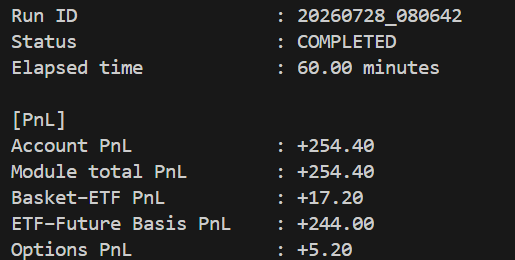 

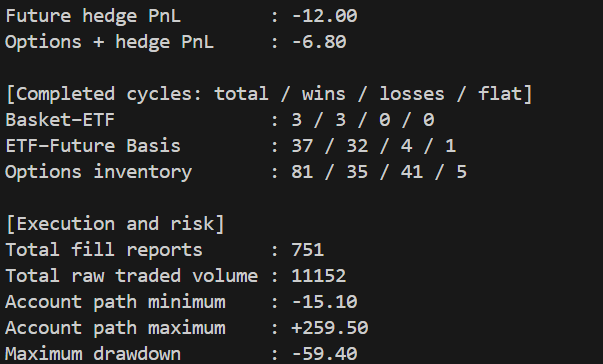 

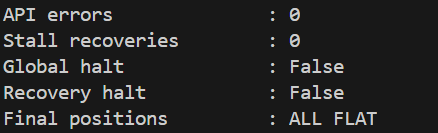

# 6.Evolution of Algorithm

The initial algorithm was constructed using the pricing relationships and market-making principles introduced in the course. The Basket–ETF strategy followed the law of one price, the ETF–Future strategy used the cost-of-carry relationship, and the Options strategy used Black-76 pricing with ordinary delta hedging. After reviewing the calculations and execution logic, I did not identify a fundamental pricing error in the original design.

However, during live testing, the algorithm did not consistently capture the profit suggested by the theoretical signals. To understand this difference, I observed the order book and compared the strategy’s behaviour across different trading periods.

I found that approximately five other active participants were continuously competing for the same market-making and relative-value opportunities. These participants frequently occupied the best Bid and Ask prices and often entered the order queue earlier. As a result, even when my algorithm quoted at the same price, its orders could remain behind the existing volume and receive few or no fills.

This behaviour can be explained by price-time priority. When multiple orders are submitted at the same price, the order that entered the market earlier normally receives execution first. Therefore, identifying the correct theoretical price was not sufficient. The algorithm also needed to consider queue position and the probability of execution.

Frequent quote updates created an additional problem. Cancelling and replacing an order caused the algorithm to lose its existing queue position. Although a new quote could be closer to the latest fair value, it was moved to the back of the queue. This created a trade-off between maintaining an accurate quote and preserving execution priority.

Market competition also affected adverse selection. During stable periods, orders ahead of mine could capture most of the normal trading volume. My orders were more likely to be reached when a large market order arrived or when the market was beginning to move. Therefore, some apparently profitable quotes were filled only under less favourable conditions.

These observations changed the direction of development. The main issue was not that the original pricing relationships were logically incorrect. Instead, the initial algorithm did not fully account for the competitive structure of the order book, including queue priority, fill probability, competing liquidity and adverse selection.

The later development therefore focused on improving how the strategy interacted with the market. The underlying pricing relationships were retained, while the execution, quoting, inventory and position-management rules were adjusted to make the strategy more effective in a competitive environment.

The main lesson from this process was that a theoretically correct trading signal does not automatically produce an executable profit. Actual performance also depends on market microstructure and the behaviour of other participants.

A second issue appeared when the Basket and Options components were first combined. Although both components worked independently, the integrated program experienced long synchronisation pauses. The architecture was therefore changed to one shared exchange connection, one order-action limiter and one unified main loop.

Another important adjustment concerned multi-leg execution. The early design focused on the intended package, but IOC orders could be partially filled. The algorithm was therefore changed to verify actual exchange positions and to repair or reverse incomplete packages.

The first ETF–Future implementation also used an absolute Basis threshold. Further testing showed that each Future expiry could have its own persistent normal Basis. The signal was therefore redesigned using a separate rolling median and MAD model for each Future, together with re-arm and cooldown rules.

Finally, experiments with larger order sizes showed that higher volume also increased partial-fill exposure, hedge cost and inventory risk. The final strategy therefore increased size only when both executable edge and market depth were sufficiently strong.

# 7.Algorithm
The following cell shows the final algorithm.

In [ ]:
from optibook.synchronous_client import Exchange
from collections import deque
from datetime import datetime, timezone
import json
import math
import re
import calendar
import logging
import statistics
import time

STARTUP_FLATTEN_MAX_PASSES = 120
STARTUP_FLATTEN_MAX_VOLUME = 100
STARTUP_FLATTEN_ORDER_DELAY = 0.20
STARTUP_FLATTEN_PASS_DELAY = 0.50

def flatten_account_before_start():
    """
    Cancel all old orders and flatten all existing account positions
    before the measured trading strategy begins.
    """

    cleanup_exchange = Exchange()
    cleanup_exchange.connect()

    print("\n" + "=" * 70)
    print("STARTUP ACCOUNT CLEANUP")
    print("=" * 70)

    # Read every exchange-defined instrument.
    all_positions = cleanup_exchange.get_positions()

    # Cancel outstanding orders first so that they cannot create new positions
    # while the account is being flattened.
    print("Cancelling outstanding orders...")

    for instrument_id in all_positions:
        try:
            cleanup_exchange.delete_orders(instrument_id)
        except Exception:
            pass

        time.sleep(0.05)

    for pass_number in range(
        1,
        STARTUP_FLATTEN_MAX_PASSES + 1,
    ):
        positions = cleanup_exchange.get_positions()

        nonzero_positions = {
            instrument_id: int(position)
            for instrument_id, position in positions.items()
            if int(position) != 0
        }

        if not nonzero_positions:
            print("Clean start confirmed: all positions are zero.")
            print("=" * 70 + "\n")

            if hasattr(cleanup_exchange, "disconnect"):
                try:
                    cleanup_exchange.disconnect()
                except Exception:
                    pass

            return

        print(
            f"Cleanup pass {pass_number}: "
            f"{nonzero_positions}"
        )

        orders_sent = 0

        for instrument_id, position in nonzero_positions.items():
            try:
                # Remove any remaining resting orders in this instrument.
                cleanup_exchange.delete_orders(instrument_id)
                time.sleep(STARTUP_FLATTEN_ORDER_DELAY)

                book = cleanup_exchange.get_last_price_book(
                    instrument_id
                )

                if book is None:
                    print(
                        f"No order book available for "
                        f"{instrument_id}."
                    )
                    continue

                if position > 0:
                    # Long position: sell against the best bid.
                    if not book.bids:
                        print(
                            f"No bid available to close "
                            f"{instrument_id}."
                        )
                        continue

                    price = float(book.bids[0].price)
                    available_volume = int(book.bids[0].volume)
                    side = "ask"

                else:
                    # Short position: buy against the best ask.
                    if not book.asks:
                        print(
                            f"No ask available to close "
                            f"{instrument_id}."
                        )
                        continue

                    price = float(book.asks[0].price)
                    available_volume = int(book.asks[0].volume)
                    side = "bid"

                volume = min(
                    abs(position),
                    available_volume,
                    STARTUP_FLATTEN_MAX_VOLUME,
                )

                if volume <= 0:
                    continue

                cleanup_exchange.insert_order(
                    instrument_id,
                    price=price,
                    volume=volume,
                    side=side,
                    order_type="ioc",
                )

                orders_sent += 1

                print(
                    f"Flattening {instrument_id}: "
                    f"{side} {volume} @ {price:.2f}"
                )

                time.sleep(STARTUP_FLATTEN_ORDER_DELAY)

            except Exception as error:
                print(
                    f"Could not flatten {instrument_id}: "
                    f"{error}"
                )

                time.sleep(STARTUP_FLATTEN_ORDER_DELAY)

        if orders_sent == 0:
            print(
                "No cleanup orders were executable in this pass. "
                "Waiting for liquidity."
            )

        time.sleep(STARTUP_FLATTEN_PASS_DELAY)

    # Final verification after reaching the maximum number of passes.
    final_positions = cleanup_exchange.get_positions()

    remaining_positions = {
        instrument_id: int(position)
        for instrument_id, position in final_positions.items()
        if int(position) != 0
    }

    if hasattr(cleanup_exchange, "disconnect"):
        try:
            cleanup_exchange.disconnect()
        except Exception:
            pass

    if remaining_positions:
        raise RuntimeError(
            "Startup cleanup could not flatten the account. "
            f"Remaining positions: {remaining_positions}"
        )


# Run the cleanup before starting the existing strategy.
flatten_account_before_start()

logging.getLogger('client').setLevel('ERROR')
RUN_MINUTES = 60
RUN_SECONDS = RUN_MINUTES * 60
LOOP_SLEEP_SECONDS = 0.08
COMBINED_SAMPLE_SECONDS = 2.0
COMBINED_STATUS_SECONDS = 30.0
GLOBAL_RISK_CHECK_SECONDS = 1.0
BASKET_RISK_CHECK_SECONDS = 1.0
BASKET_MANAGEMENT_INTERVAL_SECONDS = 0.2
OPTIONS_NORMAL_ACTION_CAP = 12
POST_BASKET_EXECUTION_QUOTE_DELAY_SECONDS = 0.6
OPTION_FILL_SETTLEMENT_SECONDS = 0.4
OPTION_LIMIT_CORRECTION_ROUNDS = 3
STRONG_BASKET_MULTIPLIER = 2
STRONG_BASKET_MIN_SURPLUS = 1.5
STRONG_BASKET_MIN_SIGNAL_TO_SPREAD_RATIO = 1.2
EXCEPTIONAL_BASKET_MULTIPLIER = 3
EXCEPTIONAL_BASKET_MIN_SURPLUS = 4.5
EXCEPTIONAL_BASKET_MIN_SIGNAL_TO_SPREAD_RATIO = 1.45
CALL_BASE_OPTION_VOLUME = 2
CALL_HIGH_EDGE_VOLUME = 4
PUT_BASE_OPTION_VOLUME = 1
PUT_HIGH_EDGE_VOLUME = 2
ADAPTIVE_OPTION_VOLUME = CALL_HIGH_EDGE_VOLUME
CALL_DOUBLE_MIN_EDGE = 0.2
PUT_DOUBLE_MIN_EDGE = 0.2
ADAPTIVE_DOUBLE_MAX_PROJECTED_DELTA = 4.5
ADAPTIVE_DOUBLE_REQUIRE_FLAT_INSTRUMENT = True
BASIS_ETF_MULTIPLIER = 0.25
BASIS_ETF_CASH = 2.5
BASIS_RISK_FREE_RATE = 0.03
BASIS_EXCHANGE_POSITION_LIMIT = 100
BASIS_MAX_UNITS = 25
BASIS_MIN_TRADE_UNITS = 25
BASIS_FULL_CAPACITY_EVERY_ENTRY = True
BASIS_HISTORY_WINDOW_SECONDS = 600.0
BASIS_OBSERVATION_INTERVAL_SECONDS = 0.5
BASIS_MIN_HISTORY_SECONDS = 120.0
BASIS_MIN_HISTORY_SAMPLES = 120
BASIS_MIN_ROBUST_SIGMA = 0.12
BASIS_ENTRY_Z = 2.0
BASIS_MIN_ABS_DEVIATION = 0.5
BASIS_MIN_EXPECTED_CYCLE_EDGE = 0.3
BASIS_EXIT_Z = 0.4
BASIS_REARM_Z = 0.75
BASIS_MAX_ADVERSE_Z_EXTENSION = 1.5
BASIS_ENTRY_CONFIRMATIONS = 3
BASIS_CONFIRMATION_MAX_GAP_SECONDS = 0.45
BASIS_TAKE_PROFIT_EDGE = 0.12
BASIS_TRAIL_ACTIVATION_EDGE = 0.35
BASIS_TRAIL_GIVEBACK_EDGE = 0.15
BASIS_ACCEPTABLE_UNWIND_COST = 0.1
BASIS_SOFT_MAX_HOLD_SECONDS = 25.0
BASIS_HARD_MAX_HOLD_SECONDS = 60.0
BASIS_POST_CLOSE_COOLDOWN_SECONDS = 1.0
BASIS_LOSS_COOLDOWN_SECONDS = 60.0
BASIS_HARD_TIMEOUT_COOLDOWN_SECONDS = 300.0
BASIS_MAX_CONSECUTIVE_LOSSES = 2
BASIS_DIRECTION_BLOCK_SECONDS = 600.0
BASIS_NO_NEW_ENTRY_LAST_SECONDS = 120.0
BASIS_SETTLEMENT_SECONDS = 1.0
BASIS_STATUS_SECONDS = 15.0
BASIS_PNL_SAMPLE_SECONDS = 1.0
BASIS_NORMAL_ACTION_CAP = 18
BASIS_ALLOW_OPTIONS_HEDGE_FUTURE_FALLBACK = True
API_SLOW_CALL_SECONDS = 0.5
API_STALL_CALL_SECONDS = 2.0
MAIN_LOOP_STALL_SECONDS = 3.0
STALL_RECOVERY_COOLDOWN_SECONDS = 15.0
PNL_RISK_GUARDS_DISABLED = True
DISABLED_PNL_LIMIT = 1000000000000.0
GLOBAL_MAX_LIQUIDATION_LOSS = DISABLED_PNL_LIMIT
GLOBAL_LOSS_CONFIRMATIONS = 3
FLAT_AT_NORMAL_END = True
FLAT_ON_KEYBOARD_INTERRUPT = True
SHARED_RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
SHARED_ACTION_TIMES = deque()
exchange = Exchange()
exchange.connect()
print('Connected to Optibook — V10TRI V9-EXACT PURE SINGLE-FILE FINAL SUBMISSION.')
api_call_rows = []
api_call_stats = {}
pending_api_events = []
api_recovery_required = False
last_api_stall_details = None

def api_elapsed_seconds():
    start = globals().get('RUN_START_MONOTONIC')
    if start is None:
        return None
    return time.monotonic() - start

def append_api_event(event_type, message, **details):
    event = {'event_type': event_type, 'message': message, 'details': details}
    pending_api_events.append(event)
    print(f'[API {event_type}] {message}', details if details else '')

def monitored_api_method(method_name, original_method):

    def wrapper(*args, **kwargs):
        global api_recovery_required
        global last_api_stall_details
        started = time.monotonic()
        success = False
        error_text = None
        try:
            result = original_method(*args, **kwargs)
            success = True
            return result
        except Exception as exc:
            error_text = str(exc)
            raise
        finally:
            duration = time.monotonic() - started
            stats = api_call_stats.setdefault(method_name, {'calls': 0, 'errors': 0, 'total_seconds': 0.0, 'max_seconds': 0.0, 'slow_calls': 0, 'stall_calls': 0})
            stats['calls'] += 1
            stats['total_seconds'] += duration
            stats['max_seconds'] = max(stats['max_seconds'], duration)
            if not success:
                stats['errors'] += 1
            is_slow = duration >= API_SLOW_CALL_SECONDS
            is_stall = duration >= API_STALL_CALL_SECONDS
            if is_slow:
                stats['slow_calls'] += 1
                api_call_rows.append({'timestamp': time.time(), 'elapsed_seconds': api_elapsed_seconds(), 'method': method_name, 'duration_seconds': duration, 'success': success, 'error': error_text, 'stall': is_stall})
            if is_stall:
                stats['stall_calls'] += 1
                api_recovery_required = True
                last_api_stall_details = {'method': method_name, 'duration_seconds': duration, 'success': success, 'error': error_text, 'detected_at': time.time()}
                append_api_event('STALL', f'{method_name} took {duration:.3f} seconds', **last_api_stall_details)
    wrapper.__name__ = f'monitored_{method_name}'
    return wrapper

def install_api_monitors():
    method_names = ['get_positions', 'get_pnl', 'get_last_price_book', 'get_outstanding_orders', 'poll_new_trades', 'insert_order', 'delete_orders']
    installed = []
    for method_name in method_names:
        original = getattr(exchange, method_name, None)
        if original is None:
            continue
        try:
            setattr(exchange, method_name, monitored_api_method(method_name, original))
            installed.append(method_name)
        except Exception as exc:
            append_api_event('MONITOR_INSTALL_ERROR', f'Could not monitor {method_name}', error=str(exc))
    print('Installed API timing monitors:', installed)
install_api_monitors()

class BasketModule:

    def __init__(self, shared_exchange, shared_run_id, shared_action_times):
        logging.getLogger('client').setLevel('ERROR')
        self.exchange = shared_exchange
        print('Initialised integrated Basket/ETF V9R module.')
        self.RUN_MINUTES = 60
        self.RUN_SECONDS = self.RUN_MINUTES * 60
        self.LOOP_SLEEP_SECONDS = 0.12
        self.STATUS_INTERVAL_SECONDS = 10.0
        self.PNL_SAMPLE_SECONDS = 2.0
        self.REQUIRE_FLAT_ACCOUNT = True
        self.FLAT_AT_NORMAL_END = True
        self.FLAT_ON_KEYBOARD_INTERRUPT = False
        self.ETF_ID = 'OB5X_ETF'
        self.STOCKS = ['ASML', 'AAPL', 'SAP', 'TSLA', 'NVDA']
        self.BASKET_WEIGHTS = {'ASML': 908.06, 'AAPL': 129.24, 'SAP': 124.78, 'TSLA': 2245.39, 'NVDA': 953.21}
        self.BASKET_DIVISOR = 1000.0
        self.BASKET_INDEX_UNITS = 8
        self.BASKET_QUANTITIES = {'ASML': 7, 'AAPL': 1, 'SAP': 1, 'TSLA': 18, 'NVDA': 8}
        self.ETF_PER_INDEX_UNIT = 4
        self.ETF_PER_PACKAGE = self.ETF_PER_INDEX_UNIT * self.BASKET_INDEX_UNITS
        self.EXACT_BASKET_QUANTITIES = {self.stock: self.BASKET_INDEX_UNITS * self.BASKET_WEIGHTS[self.stock] / self.BASKET_DIVISOR for self.stock in self.STOCKS}
        self.BASKET_RESIDUAL_QUANTITIES = {self.stock: self.BASKET_QUANTITIES[self.stock] - self.EXACT_BASKET_QUANTITIES[self.stock] for self.stock in self.STOCKS}
        self.TRACKED_INSTRUMENTS = [self.ETF_ID, *self.STOCKS]
        self.ROUNDING_SPREAD_MULTIPLIER = 2.0
        self.RESIDUAL_STRESS_BPS = 8.0
        self.EXIT_COST_FRACTION_OF_ROUNDTRIP = 0.55
        self.ROLLBACK_COST_FRACTION_OF_ROUNDTRIP = 0.2
        self.ENTRY_SAFETY_MARGIN_ABS = 0.8
        self.MIN_SIGNAL_SURPLUS_ABS = 2.0
        self.MIN_SIGNAL_TO_SPREAD_RATIO = 1.2
        self.ENTRY_CONFIRMATIONS = 4
        self.MAX_CONFIRMATION_GAP_SECONDS = 0.75
        self.MAX_CONFIRMATION_SPREAD_RATIO = 1.25
        self.POST_CLOSE_COOLDOWN_SECONDS = 3.0
        self.POST_HARD_STOP_COOLDOWN_SECONDS = 45.0
        self.BASE_TAKE_PROFIT_ABS = 1.0
        self.TAKE_PROFIT_SPREAD_FRACTION = 0.12
        self.TRAIL_ACTIVATION_ABS = 3.0
        self.TRAIL_GIVEBACK_ABS = 1.5
        self.TRAIL_MIN_EXIT_PNL = 1.0
        self.MAX_HOLD_SECONDS = 4 * 60
        self.STALE_EXIT_MIN_PNL = -0.5
        self.MARKED_STOP_LOSS_ABS = 8.0
        self.LIQUIDATION_STOP_LOSS_ABS = 14.0
        self.EMERGENCY_LIQUIDATION_STOP_ABS = 25.0
        self.STOP_CONFIRMATIONS = 5
        self.STOP_CONFIRM_MAX_GAP_SECONDS = 0.55
        self.LIQUIDITY_SHOCK_RATIO = 1.6
        self.LIQUIDITY_SHOCK_ABS = 4.0
        self.LIQUIDITY_SHOCK_GRACE_SECONDS = 4.0
        self.MAX_RUN_LIQUIDATION_LOSS = 20.0
        self.MAX_COMPLETED_CYCLES = 30
        self.MAX_FAILED_ROLLBACKS = 2
        self.NO_NEW_ENTRY_LAST_SECONDS = 150
        self.WINDDOWN_CLOSE_LAST_SECONDS = 60
        self.WINDDOWN_ACCEPTABLE_PNL = -1.0
        self.FINAL_FORCE_CLOSE_LAST_SECONDS = 15
        self.MAX_ACTIVE_PACKAGES = 1
        self.OPEN_REPAIR_MAX_INSTRUMENTS = 1
        self.OPEN_REPAIR_MAX_ATTEMPTS = 2
        self.OPEN_REPAIR_MAX_AGGRESSIVE_TICKS = 1
        self.OPEN_REPAIR_MAX_ADDITIONAL_COST_ABS = 3.0
        self.OPEN_REPAIR_MIN_REMAINING_SURPLUS = 0.25
        self.HARD_POSITION_LIMIT = 100
        self.SOFT_LIMITS = {self.ETF_ID: self.ETF_PER_PACKAGE, 'ASML': self.BASKET_QUANTITIES['ASML'], 'AAPL': self.BASKET_QUANTITIES['AAPL'], 'SAP': self.BASKET_QUANTITIES['SAP'], 'TSLA': self.BASKET_QUANTITIES['TSLA'], 'NVDA': self.BASKET_QUANTITIES['NVDA']}
        self.MAX_ORDER_ACTIONS_PER_SECOND = 20
        self.NORMAL_ACTION_CAP = 14
        self.action_times = shared_action_times
        self.instruments = self.exchange.get_instruments()
        self.active_state = None
        self.stop_new_entries = False
        self.interrupted_by_user = False
        self.confirmation_state = {'direction': None, 'count': 0, 'last_time': 0.0, 'last_signal': None, 'spreads': []}
        self.stats = {'open_attempts': 0, 'successful_opens': 0, 'successful_closes': 0, 'failed_packages': 0, 'repair_attempts': 0, 'repair_successes': 0, 'rollback_attempts': 0, 'rollback_failures': 0, 'fills': 0, 'turnover': 0}
        self.ledger_cash = {self.iid: 0.0 for self.iid in self.TRACKED_INSTRUMENTS}
        self.ledger_position = {self.iid: 0 for self.iid in self.TRACKED_INSTRUMENTS}
        self.pnl_rows = []
        self.cycle_rows = []
        self.event_rows = []
        self.latest_snapshot = None
        self.latest_opportunity = None
        self.STARTING_ACCOUNT_PNL = 0.0
        self.RUN_START_WALL = 0.0
        self.RUN_START_MONOTONIC = 0.0
        self.RUN_ID = shared_run_id
        self.last_status_monotonic = 0.0
        self.last_sample_monotonic = 0.0
        self.last_close_monotonic = -1000000000.0
        self.last_hard_stop_monotonic = -1000000000.0
        self.blocked_direction_until = {1: -1000000000.0, -1: -1000000000.0}
        self.cancel_tracked_orders(emergency=True)
        self.starting_positions = self.positions()
        if self.REQUIRE_FLAT_ACCOUNT:
            self.nonzero = self.all_account_positions(self.starting_positions)
            if self.nonzero:
                raise RuntimeError(f'V9R requires a completely flat starting account. Non-zero positions: {self.nonzero}')
        self.drain_old_trades()
        self.STARTING_ACCOUNT_PNL = self.exchange.get_pnl()
        self.RUN_START_WALL = time.time()
        self.RUN_START_MONOTONIC = time.monotonic()
        self.record_event('START', 'Started OB5X Basket/ETF V9R', run_minutes=self.RUN_MINUTES, starting_account_pnl=self.STARTING_ACCOUNT_PNL, basket_index_units=self.BASKET_INDEX_UNITS, basket_quantities=self.BASKET_QUANTITIES, etf_per_package=self.ETF_PER_PACKAGE, exact_quantities=self.EXACT_BASKET_QUANTITIES, residual_quantities=self.BASKET_RESIDUAL_QUANTITIES, min_signal_surplus=self.MIN_SIGNAL_SURPLUS_ABS, min_signal_to_spread_ratio=self.MIN_SIGNAL_TO_SPREAD_RATIO, marked_stop_loss=self.MARKED_STOP_LOSS_ABS, liquidation_stop_loss=self.LIQUIDATION_STOP_LOSS_ABS, emergency_liquidation_stop=self.EMERGENCY_LIQUIDATION_STOP_ABS)
        print(f'Starting Account PnL: {self.STARTING_ACCOUNT_PNL:.2f}')
        print(f'Run duration: {self.RUN_MINUTES} minutes.')
        print('Active strategy: Basket/ETF only.')
        print('Options V7 runs concurrently in the integrated controller.')
        print('V9R protections: original V9 entry logic plus minimal partial-fill repair, liquidity-shock diagnosis, confirmed dual-PnL stop, and post-stop direction cooldown.')

    def __getitem__(self, key):
        return getattr(self, key)

    def __setitem__(self, key, value):
        setattr(self, key, value)

    def get(self, key, default=None):
        return getattr(self, key, default)

    def utc_text(self):
        return datetime.now().isoformat(timespec='milliseconds')

    def record_event(self, event_type, message, **details):
        row = {'timestamp': self.utc_text(), 'elapsed_seconds': time.monotonic() - self.RUN_START_MONOTONIC if self.RUN_START_MONOTONIC > 0 else 0.0, 'event_type': event_type, 'message': message, 'details_json': json.dumps(details, sort_keys=True, default=str)}
        self.event_rows.append(row)
        print(f'[{event_type}] {message}', details if details else '')

    def positions(self):
        return self.exchange.get_positions()

    def top(self, instrument_id):
        try:
            book = self.exchange.get_last_price_book(instrument_id)
        except Exception as exc:
            self.record_event('BOOK_ERROR', f'Could not read {instrument_id}', error=str(exc))
            return None
        if book is None or not book.bids or (not book.asks):
            return None
        bid = float(book.bids[0].price)
        ask = float(book.asks[0].price)
        if not math.isfinite(bid) or not math.isfinite(ask) or bid <= 0 or (ask <= 0) or (bid > ask):
            return None
        return {'bid': bid, 'bid_volume': int(book.bids[0].volume), 'ask': ask, 'ask_volume': int(book.asks[0].volume), 'mid': 0.5 * (bid + ask), 'spread': ask - bid}

    def tick_size(self, instrument_id):
        value = getattr(self.instruments[instrument_id], 'tick_size', None)
        if value is None:
            return 0.1
        return float(value)

    def expected_position_change(self, side, volume):
        return int(volume) if side == 'bid' else -int(volume)

    def relevant_positions(self, position_map=None):
        if position_map is None:
            position_map = self.positions()
        return {iid: int(position_map.get(iid, 0)) for iid in self.TRACKED_INSTRUMENTS if int(position_map.get(iid, 0)) != 0}

    def all_account_positions(self, position_map=None):
        if position_map is None:
            position_map = self.positions()
        return {iid: int(quantity) for iid, quantity in position_map.items() if int(quantity) != 0}

    def clean_actions(self):
        now = time.monotonic()
        while self.action_times and now - self.action_times[0] >= 1.0:
            self.action_times.popleft()

    def reserve_actions(self, number, emergency=False):
        self.clean_actions()
        cap = self.MAX_ORDER_ACTIONS_PER_SECOND if emergency else self.NORMAL_ACTION_CAP
        if len(self.action_times) + number > cap:
            return False
        now = time.monotonic()
        for _ in range(number):
            self.action_times.append(now)
        return True

    def wait_for_actions(self, number, emergency=False, timeout=1.5):
        deadline = time.monotonic() + timeout
        while time.monotonic() < deadline:
            if self.reserve_actions(number, emergency=emergency):
                return True
            time.sleep(0.035)
        return False

    def cancel_tracked_orders(self, emergency=False):
        ids_to_cancel = []
        for iid in self.TRACKED_INSTRUMENTS:
            try:
                orders = self.exchange.get_outstanding_orders(iid)
            except Exception:
                orders = {}
            if orders:
                ids_to_cancel.append(iid)
        if not ids_to_cancel:
            return True
        if not self.wait_for_actions(len(ids_to_cancel), emergency=emergency):
            return False
        for iid in ids_to_cancel:
            self.exchange.delete_orders(iid)
        return True

    def drain_old_trades(self):
        for iid in self.TRACKED_INSTRUMENTS:
            try:
                self.exchange.poll_new_trades(iid)
            except Exception:
                pass

    def poll_trades(self):
        new_trade_count = 0
        for iid in self.TRACKED_INSTRUMENTS:
            try:
                trades = self.exchange.poll_new_trades(iid)
            except Exception as exc:
                self.record_event('TRADE_POLL_ERROR', f'Could not poll {iid}', error=str(exc))
                trades = []
            for trade in trades:
                signed_quantity = int(trade.volume) if trade.side == 'bid' else -int(trade.volume)
                price = float(trade.price)
                self.ledger_position[iid] += signed_quantity
                self.ledger_cash[iid] -= signed_quantity * price
                self.stats['fills'] += 1
                self.stats['turnover'] += abs(signed_quantity)
                new_trade_count += 1
                self.record_event('FILL', f'{iid} {trade.side} fill', instrument_id=iid, side=trade.side, volume=int(trade.volume), price=price, ledger_position=self.ledger_position[iid])
        return new_trade_count

    def wait_and_poll_trades(self, wait_seconds=0.09, rounds=2):
        for _ in range(rounds):
            time.sleep(wait_seconds)
            self.poll_trades()

    def ledger_positions_match_exchange(self):
        current = self.positions()
        differences = {}
        for iid in self.TRACKED_INSTRUMENTS:
            exchange_position = int(current.get(iid, 0))
            ledger_value = int(self.ledger_position[iid])
            if exchange_position != ledger_value:
                differences[iid] = {'exchange': exchange_position, 'ledger': ledger_value}
        return differences

    def strategy_pnl(self, liquidation=False):
        total = 0.0
        for iid in self.TRACKED_INSTRUMENTS:
            market = self.top(iid)
            if market is None:
                return None
            position = self.ledger_position[iid]
            if not liquidation:
                mark = market['mid']
            elif position > 0:
                mark = market['bid']
            elif position < 0:
                mark = market['ask']
            else:
                mark = 0.0
            total += self.ledger_cash[iid] + position * mark
        return total

    def strategy_realised_pnl_if_flat(self):
        if any((self.ledger_position[iid] != 0 for iid in self.TRACKED_INSTRUMENTS)):
            return None
        return sum(self.ledger_cash.values())

    def read_snapshot(self):
        etf = self.top(self.ETF_ID)
        if etf is None:
            return None
        stock_tops = {}
        for stock in self.STOCKS:
            market = self.top(stock)
            if market is None:
                return None
            stock_tops[stock] = market
        weighted_index_bid = sum((self.BASKET_WEIGHTS[stock] * stock_tops[stock]['bid'] for stock in self.STOCKS)) / self.BASKET_DIVISOR
        weighted_index_ask = sum((self.BASKET_WEIGHTS[stock] * stock_tops[stock]['ask'] for stock in self.STOCKS)) / self.BASKET_DIVISOR
        integer_package_bid = sum((self.BASKET_QUANTITIES[stock] * stock_tops[stock]['bid'] for stock in self.STOCKS))
        integer_package_ask = sum((self.BASKET_QUANTITIES[stock] * stock_tops[stock]['ask'] for stock in self.STOCKS))
        integer_package_spread = integer_package_ask - integer_package_bid
        residual_mid = sum((self.BASKET_RESIDUAL_QUANTITIES[stock] * stock_tops[stock]['mid'] for stock in self.STOCKS))
        residual_half_spread = sum((abs(self.BASKET_RESIDUAL_QUANTITIES[stock]) * 0.5 * stock_tops[stock]['spread'] for stock in self.STOCKS))
        residual_stress = sum((abs(self.BASKET_RESIDUAL_QUANTITIES[stock]) * stock_tops[stock]['mid'] * self.RESIDUAL_STRESS_BPS / 10000.0 for stock in self.STOCKS))
        residual_buffer = self.ROUNDING_SPREAD_MULTIPLIER * residual_half_spread + residual_stress
        corrected_index_bid = (integer_package_bid - residual_mid - residual_buffer) / self.BASKET_INDEX_UNITS
        corrected_index_ask = (integer_package_ask - residual_mid + residual_buffer) / self.BASKET_INDEX_UNITS
        conservative_index_bid = min(weighted_index_bid, corrected_index_bid)
        conservative_index_ask = max(weighted_index_ask, corrected_index_ask)
        etf_index_bid = self.ETF_PER_INDEX_UNIT * (etf['bid'] - 2.5)
        etf_index_ask = self.ETF_PER_INDEX_UNIT * (etf['ask'] - 2.5)
        etf_package_spread = self.ETF_PER_PACKAGE * etf['spread']
        full_roundtrip_spread = integer_package_spread + etf_package_spread
        estimated_exit_cost = self.EXIT_COST_FRACTION_OF_ROUNDTRIP * full_roundtrip_spread
        estimated_rollback_cost = self.ROLLBACK_COST_FRACTION_OF_ROUNDTRIP * full_roundtrip_spread
        required_package_signal = estimated_exit_cost + estimated_rollback_cost + residual_buffer + self.ENTRY_SAFETY_MARGIN_ABS
        basket_buy_depth = min((stock_tops[stock]['ask_volume'] // self.BASKET_QUANTITIES[stock] for stock in self.STOCKS))
        basket_sell_depth = min((stock_tops[stock]['bid_volume'] // self.BASKET_QUANTITIES[stock] for stock in self.STOCKS))
        return {'timestamp': self.utc_text(), 'etf': etf, 'stock_tops': stock_tops, 'weighted_index_bid': weighted_index_bid, 'weighted_index_ask': weighted_index_ask, 'integer_package_bid': integer_package_bid, 'integer_package_ask': integer_package_ask, 'integer_package_spread': integer_package_spread, 'residual_mid': residual_mid, 'residual_half_spread': residual_half_spread, 'residual_stress': residual_stress, 'residual_buffer': residual_buffer, 'corrected_index_bid': corrected_index_bid, 'corrected_index_ask': corrected_index_ask, 'conservative_index_bid': conservative_index_bid, 'conservative_index_ask': conservative_index_ask, 'etf_index_bid': etf_index_bid, 'etf_index_ask': etf_index_ask, 'etf_package_spread': etf_package_spread, 'full_roundtrip_spread': full_roundtrip_spread, 'estimated_exit_cost': estimated_exit_cost, 'estimated_rollback_cost': estimated_rollback_cost, 'required_package_signal': required_package_signal, 'basket_buy_depth': basket_buy_depth, 'basket_sell_depth': basket_sell_depth}

    def find_opportunity(self, snapshot):
        candidates = []
        exact_edge_per_index = snapshot['etf_index_bid'] - snapshot['weighted_index_ask']
        corrected_edge_per_index = snapshot['etf_index_bid'] - snapshot['corrected_index_ask']
        conservative_edge_per_index = min(exact_edge_per_index, corrected_edge_per_index)
        package_signal = conservative_edge_per_index * self.BASKET_INDEX_UNITS
        surplus = package_signal - snapshot['required_package_signal']
        signal_spread_ratio = package_signal / max(snapshot['full_roundtrip_spread'], 1e-09)
        if exact_edge_per_index > 0 and corrected_edge_per_index > 0 and (package_signal >= snapshot['required_package_signal']) and (surplus >= self.MIN_SIGNAL_SURPLUS_ABS) and (signal_spread_ratio >= self.MIN_SIGNAL_TO_SPREAD_RATIO) and (snapshot['basket_buy_depth'] >= 1) and (snapshot['etf']['bid_volume'] >= self.ETF_PER_PACKAGE):
            candidates.append({'direction': 1, 'exact_edge_per_index': exact_edge_per_index, 'corrected_edge_per_index': corrected_edge_per_index, 'conservative_edge_per_index': conservative_edge_per_index, 'package_signal': package_signal, 'required_package_signal': snapshot['required_package_signal'], 'surplus': surplus, 'signal_spread_ratio': signal_spread_ratio})
        exact_edge_per_index = snapshot['weighted_index_bid'] - snapshot['etf_index_ask']
        corrected_edge_per_index = snapshot['corrected_index_bid'] - snapshot['etf_index_ask']
        conservative_edge_per_index = min(exact_edge_per_index, corrected_edge_per_index)
        package_signal = conservative_edge_per_index * self.BASKET_INDEX_UNITS
        surplus = package_signal - snapshot['required_package_signal']
        signal_spread_ratio = package_signal / max(snapshot['full_roundtrip_spread'], 1e-09)
        if exact_edge_per_index > 0 and corrected_edge_per_index > 0 and (package_signal >= snapshot['required_package_signal']) and (surplus >= self.MIN_SIGNAL_SURPLUS_ABS) and (signal_spread_ratio >= self.MIN_SIGNAL_TO_SPREAD_RATIO) and (snapshot['basket_sell_depth'] >= 1) and (snapshot['etf']['ask_volume'] >= self.ETF_PER_PACKAGE):
            candidates.append({'direction': -1, 'exact_edge_per_index': exact_edge_per_index, 'corrected_edge_per_index': corrected_edge_per_index, 'conservative_edge_per_index': conservative_edge_per_index, 'package_signal': package_signal, 'required_package_signal': snapshot['required_package_signal'], 'surplus': surplus, 'signal_spread_ratio': signal_spread_ratio})
        if not candidates:
            return None
        return max(candidates, key=lambda item: item['surplus'])

    def reset_confirmation(self):
        self.confirmation_state['direction'] = None
        self.confirmation_state['count'] = 0
        self.confirmation_state['last_time'] = 0.0
        self.confirmation_state['last_signal'] = None
        self.confirmation_state['spreads'] = []

    def direction_is_blocked(self, direction):
        return time.monotonic() < self.blocked_direction_until.get(direction, -1000000000.0)

    def confirm_opportunity(self, opportunity, snapshot):
        now = time.monotonic()
        if opportunity is None or snapshot is None or self.direction_is_blocked(opportunity['direction']):
            self.reset_confirmation()
            return False
        same_direction = self.confirmation_state['direction'] == opportunity['direction']
        short_gap = now - self.confirmation_state['last_time'] <= self.MAX_CONFIRMATION_GAP_SECONDS
        if same_direction and short_gap:
            self.confirmation_state['count'] += 1
        else:
            self.confirmation_state['direction'] = opportunity['direction']
            self.confirmation_state['count'] = 1
            self.confirmation_state['spreads'] = []
        self.confirmation_state['spreads'].append(snapshot['full_roundtrip_spread'])
        self.confirmation_state['spreads'] = self.confirmation_state['spreads'][-self.ENTRY_CONFIRMATIONS:]
        self.confirmation_state['last_time'] = now
        self.confirmation_state['last_signal'] = opportunity['package_signal']
        if self.confirmation_state['count'] < self.ENTRY_CONFIRMATIONS:
            return False
        spreads = self.confirmation_state['spreads']
        spread_ratio = max(spreads) / max(min(spreads), 1e-09)
        if spread_ratio > self.MAX_CONFIRMATION_SPREAD_RATIO:
            self.record_event('ENTRY_REJECT', 'Spread was unstable during confirmation', direction=opportunity['direction'], spread_ratio=spread_ratio, spreads=spreads)
            self.reset_confirmation()
            return False
        return True

    def order_price(self, market, side, aggressive_ticks=0, instrument_id=None):
        tick = self.tick_size(instrument_id) if instrument_id is not None else 0.1
        if side == 'bid':
            return market['ask'] + aggressive_ticks * tick
        return max(tick, market['bid'] - aggressive_ticks * tick)

    def opening_legs(self, direction, snapshot):
        if direction == 1:
            legs = [{'instrument_id': stock, 'side': 'bid', 'volume': self.BASKET_QUANTITIES[stock], 'price': snapshot['stock_tops'][stock]['ask']} for stock in self.STOCKS]
            legs.append({'instrument_id': self.ETF_ID, 'side': 'ask', 'volume': self.ETF_PER_PACKAGE, 'price': snapshot['etf']['bid']})
            return legs
        legs = [{'instrument_id': stock, 'side': 'ask', 'volume': self.BASKET_QUANTITIES[stock], 'price': snapshot['stock_tops'][stock]['bid']} for stock in self.STOCKS]
        legs.append({'instrument_id': self.ETF_ID, 'side': 'bid', 'volume': self.ETF_PER_PACKAGE, 'price': snapshot['etf']['ask']})
        return legs

    def signed_quantities_from_legs(self, legs):
        result = {}
        for leg in legs:
            iid = leg['instrument_id']
            result[iid] = result.get(iid, 0) + self.expected_position_change(leg['side'], leg['volume'])
        return result

    def closing_legs_from_state(self, state, aggressive_ticks=0):
        legs = []
        for iid, signed_quantity in state['signed_quantities'].items():
            if signed_quantity == 0:
                continue
            market = self.top(iid)
            if market is None:
                return None
            if signed_quantity > 0:
                side = 'ask'
                volume = signed_quantity
            else:
                side = 'bid'
                volume = abs(signed_quantity)
            legs.append({'instrument_id': iid, 'side': side, 'volume': int(volume), 'price': self.order_price(market, side, aggressive_ticks=aggressive_ticks, instrument_id=iid)})
        return legs

    def legs_pass_limits(self, legs):
        current = self.positions()
        changes = {}
        for leg in legs:
            iid = leg['instrument_id']
            changes[iid] = changes.get(iid, 0) + self.expected_position_change(leg['side'], leg['volume'])
        for iid, change in changes.items():
            proposed = int(current.get(iid, 0)) + int(change)
            if abs(proposed) > self.HARD_POSITION_LIMIT:
                return False
            soft_limit = self.SOFT_LIMITS.get(iid, self.HARD_POSITION_LIMIT)
            if abs(proposed) > soft_limit:
                return False
        return True

    def legs_have_depth(self, legs):
        for leg in legs:
            market = self.top(leg['instrument_id'])
            if market is None:
                return False
            available = market['ask_volume'] if leg['side'] == 'bid' else market['bid_volume']
            if available < leg['volume']:
                return False
        return True

    def submit_ioc_legs(self, legs, emergency=False):
        if not self.legs_pass_limits(legs):
            self.record_event('LIMIT_BLOCK', 'Package blocked by position limits', legs=legs)
            return False
        if not self.wait_for_actions(len(legs), emergency=emergency):
            self.record_event('ACTION_BLOCK', 'Package blocked by action rate limit', requested_actions=len(legs), emergency=emergency)
            return False
        for leg in legs:
            self.exchange.insert_order(leg['instrument_id'], price=float(leg['price']), volume=int(leg['volume']), side=leg['side'], order_type='ioc')
        return True

    def emergency_order_to_target(self, instrument_id, current_position, target_position, aggressive_ticks=2):
        difference = current_position - target_position
        if difference == 0:
            return None
        market = self.top(instrument_id)
        if market is None:
            return None
        if difference > 0:
            side = 'ask'
            volume = difference
        else:
            side = 'bid'
            volume = abs(difference)
        return {'instrument_id': instrument_id, 'side': side, 'volume': int(volume), 'price': self.order_price(market, side, aggressive_ticks=aggressive_ticks, instrument_id=instrument_id)}

    def restore_positions(self, target_positions, affected_instruments):
        self.stats['rollback_attempts'] += 1
        for attempt in range(1, 5):
            current = self.positions()
            residuals = {iid: int(current.get(iid, 0)) - int(target_positions.get(iid, 0)) for iid in affected_instruments if int(current.get(iid, 0)) != int(target_positions.get(iid, 0))}
            if not residuals:
                return True
            orders = []
            for iid in affected_instruments:
                order = self.emergency_order_to_target(iid, int(current.get(iid, 0)), int(target_positions.get(iid, 0)), aggressive_ticks=min(1 + attempt, 4))
                if order is not None:
                    orders.append(order)
            self.record_event('ROLLBACK', f'Rollback attempt {attempt}', residuals=residuals)
            if not orders:
                break
            if not self.wait_for_actions(len(orders), emergency=True):
                continue
            for order in orders:
                self.exchange.insert_order(order['instrument_id'], price=float(order['price']), volume=int(order['volume']), side=order['side'], order_type='ioc')
            self.wait_and_poll_trades(wait_seconds=0.1, rounds=2)
        current = self.positions()
        success = all((int(current.get(iid, 0)) == int(target_positions.get(iid, 0)) for iid in affected_instruments))
        if not success:
            self.stats['rollback_failures'] += 1
            self.record_event('ROLLBACK_FAILURE', 'Could not restore all positions', current_positions={iid: int(current.get(iid, 0)) for iid in affected_instruments}, target_positions={iid: int(target_positions.get(iid, 0)) for iid in affected_instruments})
        return success

    def actual_package_changes(self, before_positions, affected_instruments):
        current = self.positions()
        return {iid: int(current.get(iid, 0)) - int(before_positions.get(iid, 0)) for iid in affected_instruments}

    def missing_package_changes(self, expected_changes, actual_changes):
        return {iid: int(expected_changes.get(iid, 0)) - int(actual_changes.get(iid, 0)) for iid in expected_changes if int(expected_changes.get(iid, 0)) != int(actual_changes.get(iid, 0))}

    def repair_leg_from_missing_change(self, instrument_id, missing_change, aggressive_ticks):
        market = self.top(instrument_id)
        if market is None:
            return None
        side = 'bid' if missing_change > 0 else 'ask'
        return {'instrument_id': instrument_id, 'side': side, 'volume': abs(int(missing_change)), 'price': self.order_price(market, side, aggressive_ticks=aggressive_ticks, instrument_id=instrument_id)}

    def estimated_repair_slippage(self, repair_leg, original_leg):
        quantity = int(repair_leg['volume'])
        if repair_leg['side'] == 'bid':
            per_unit = max(0.0, float(repair_leg['price']) - float(original_leg['price']))
        else:
            per_unit = max(0.0, float(original_leg['price']) - float(repair_leg['price']))
        return per_unit * quantity

    def try_repair_open_package(self, legs, before_positions, expected_changes, affected, repair_budget_abs):
        original_by_instrument = {leg['instrument_id']: leg for leg in legs}
        estimated_cost_used = 0.0
        attempts_used = 0
        for attempt in range(1, self.OPEN_REPAIR_MAX_ATTEMPTS + 1):
            actual_changes = self.actual_package_changes(before_positions, affected)
            missing = self.missing_package_changes(expected_changes, actual_changes)
            if not missing:
                self.stats['repair_successes'] += 1
                self.record_event('PACKAGE_REPAIRED', 'Incomplete OPEN package was completed before rollback', attempts=attempts_used, estimated_repair_cost=estimated_cost_used, actual_changes=actual_changes, completion_mode='delayed_fill_reconciliation' if attempts_used == 0 else 'repair_attempt')
                return {'success': True, 'attempts': attempts_used, 'estimated_cost': estimated_cost_used}
            if len(missing) > self.OPEN_REPAIR_MAX_INSTRUMENTS:
                self.record_event('REPAIR_ABORT', 'Open repair rejected because more than one instrument is missing', attempt=attempt, missing_changes=missing)
                break
            instrument_id, missing_change = next(iter(missing.items()))
            aggressive_ticks = min(attempt - 1, self.OPEN_REPAIR_MAX_AGGRESSIVE_TICKS)
            repair_leg = self.repair_leg_from_missing_change(instrument_id, missing_change, aggressive_ticks)
            if repair_leg is None:
                self.record_event('REPAIR_ABORT', 'Could not read a book for the missing leg', attempt=attempt, instrument_id=instrument_id, missing_change=missing_change)
                break
            original_leg = original_by_instrument[instrument_id]
            estimated_attempt_cost = self.estimated_repair_slippage(repair_leg, original_leg)
            if estimated_cost_used + estimated_attempt_cost > repair_budget_abs + 1e-09:
                self.record_event('REPAIR_BUDGET_BLOCK', 'Missing-leg repair exceeded the available entry surplus budget', attempt=attempt, instrument_id=instrument_id, missing_change=missing_change, estimated_attempt_cost=estimated_attempt_cost, estimated_cost_used=estimated_cost_used, repair_budget_abs=repair_budget_abs)
                break
            market = self.top(instrument_id)
            if market is None:
                break
            available = market['ask_volume'] if repair_leg['side'] == 'bid' else market['bid_volume']
            if available <= 0:
                self.record_event('REPAIR_NO_DEPTH', 'Missing leg had no executable top-level depth', attempt=attempt, instrument_id=instrument_id, missing_change=missing_change)
                continue
            self.stats['repair_attempts'] += 1
            attempts_used += 1
            self.record_event('REPAIR_ATTEMPT', 'Attempting to complete one missing OPEN leg before rollback', attempt=attempt, instrument_id=instrument_id, missing_change=missing_change, available_volume=available, aggressive_ticks=aggressive_ticks, price=repair_leg['price'], estimated_attempt_cost=estimated_attempt_cost, repair_budget_abs=repair_budget_abs)
            before_attempt_positions = self.positions()
            submitted = self.submit_ioc_legs([repair_leg], emergency=False)
            if not submitted:
                continue
            self.wait_and_poll_trades(wait_seconds=0.085, rounds=2)
            after_attempt_positions = self.positions()
            filled_change = int(after_attempt_positions.get(instrument_id, 0)) - int(before_attempt_positions.get(instrument_id, 0))
            filled_quantity = min(abs(int(filled_change)), abs(int(missing_change)))
            if repair_leg['volume'] > 0:
                estimated_cost_used += estimated_attempt_cost * filled_quantity / repair_leg['volume']
        final_actual = self.actual_package_changes(before_positions, affected)
        final_missing = self.missing_package_changes(expected_changes, final_actual)
        success = not final_missing
        if success:
            self.stats['repair_successes'] += 1
            self.record_event('PACKAGE_REPAIRED', 'Incomplete OPEN package was completed before rollback', attempts=attempts_used, estimated_repair_cost=estimated_cost_used, actual_changes=final_actual)
        else:
            self.record_event('REPAIR_FAILED', 'Open repair did not complete the package; rollback will follow', attempts=attempts_used, estimated_repair_cost=estimated_cost_used, remaining_missing_changes=final_missing)
        return {'success': success, 'attempts': attempts_used, 'estimated_cost': estimated_cost_used}

    def execute_exact_package(self, legs, purpose, emergency=False, repair_budget_abs=0.0):
        affected = sorted({leg['instrument_id'] for leg in legs})
        before_positions = self.positions()
        before_liquidation_pnl = self.strategy_pnl(liquidation=True)
        expected_changes = self.signed_quantities_from_legs(legs)
        if not self.legs_have_depth(legs):
            self.record_event('DEPTH_BLOCK', f'{purpose} blocked by insufficient depth', legs=legs)
            return {'success': False, 'rolled_back': False, 'reason': 'insufficient_depth', 'repair_attempts': 0, 'estimated_repair_cost': 0.0}
        if not self.submit_ioc_legs(legs, emergency=emergency):
            return {'success': False, 'rolled_back': False, 'reason': 'submission_blocked', 'repair_attempts': 0, 'estimated_repair_cost': 0.0}
        self.wait_and_poll_trades(wait_seconds=0.085, rounds=2)
        actual_changes = self.actual_package_changes(before_positions, affected)
        exact = all((actual_changes.get(iid, 0) == expected_changes.get(iid, 0) for iid in affected))
        if exact:
            self.record_event('PACKAGE_FILLED', f'{purpose} package filled exactly', expected_changes=expected_changes, actual_changes=actual_changes)
            return {'success': True, 'rolled_back': False, 'reason': 'filled_exact', 'repair_attempts': 0, 'estimated_repair_cost': 0.0}
        self.stats['failed_packages'] += 1
        self.record_event('PARTIAL_PACKAGE', f'{purpose} package was incomplete', expected_changes=expected_changes, actual_changes=actual_changes)
        if purpose == 'OPEN' and repair_budget_abs > 0.0:
            repair_result = self.try_repair_open_package(legs=legs, before_positions=before_positions, expected_changes=expected_changes, affected=affected, repair_budget_abs=repair_budget_abs)
            if repair_result['success']:
                return {'success': True, 'rolled_back': False, 'reason': 'filled_repaired', 'repair_attempts': repair_result['attempts'], 'estimated_repair_cost': repair_result['estimated_cost']}
        target = {iid: int(before_positions.get(iid, 0)) for iid in affected}
        rollback_success = self.restore_positions(target, affected)
        self.poll_trades()
        after_rollback_pnl = self.strategy_pnl(liquidation=True)
        rollback_pnl_change = None
        if before_liquidation_pnl is not None and after_rollback_pnl is not None:
            rollback_pnl_change = after_rollback_pnl - before_liquidation_pnl
        self.record_event('ROLLBACK_RESULT', f'{purpose} rollback completed', success=rollback_success, liquidation_pnl_change=rollback_pnl_change)
        return {'success': False, 'rolled_back': rollback_success, 'reason': 'partial_fill', 'rollback_pnl_change': rollback_pnl_change, 'repair_attempts': 0, 'estimated_repair_cost': 0.0}

    def active_cycle_liquidation_pnl(self):
        if self.active_state is None:
            return 0.0
        total_liquidation_pnl = self.strategy_pnl(liquidation=True)
        if total_liquidation_pnl is None:
            return None
        return total_liquidation_pnl - self.active_state['baseline_realised_pnl']

    def active_cycle_marked_pnl(self):
        if self.active_state is None:
            return 0.0
        total_marked_pnl = self.strategy_pnl(liquidation=False)
        if total_marked_pnl is None:
            return None
        return total_marked_pnl - self.active_state['baseline_realised_pnl']

    def active_residual_marked_pnl(self):
        if self.active_state is None:
            return 0.0
        direction = self.active_state['direction']
        total = 0.0
        for stock in self.STOCKS:
            market = self.top(stock)
            if market is None:
                return None
            entry_mid = self.active_state['entry_stock_mids'][stock]
            total += direction * self.BASKET_RESIDUAL_QUANTITIES[stock] * (market['mid'] - entry_mid)
        return total

    def active_core_marked_pnl(self):
        marked = self.active_cycle_marked_pnl()
        residual = self.active_residual_marked_pnl()
        if marked is None or residual is None:
            return None
        return marked - residual

    def active_liquidity_cost(self):
        marked = self.active_cycle_marked_pnl()
        liquidation = self.active_cycle_liquidation_pnl()
        if marked is None or liquidation is None:
            return None
        return max(0.0, marked - liquidation)

    def active_spread_ratio(self, snapshot):
        if self.active_state is None or snapshot is None:
            return 1.0
        return snapshot['full_roundtrip_spread'] / max(self.active_state['entry_roundtrip_spread'], 1e-09)

    def current_expected_positions(self):
        if self.active_state is None:
            return {iid: 0 for iid in self.TRACKED_INSTRUMENTS}
        return {iid: int(self.active_state['signed_quantities'].get(iid, 0)) for iid in self.TRACKED_INSTRUMENTS}

    def validate_strategy_positions(self):
        current = self.positions()
        expected = self.current_expected_positions()
        mismatches = {}
        for iid in self.TRACKED_INSTRUMENTS:
            actual = int(current.get(iid, 0))
            target = int(expected.get(iid, 0))
            if actual != target:
                mismatches[iid] = {'actual': actual, 'expected': target}
        ledger_differences = self.ledger_positions_match_exchange()
        return {'state_mismatches': mismatches, 'ledger_mismatches': ledger_differences}

    def open_package(self, opportunity, snapshot):
        if self.active_state is not None:
            return False
        baseline_realised = self.strategy_realised_pnl_if_flat()
        if baseline_realised is None:
            self.record_event('OPEN_BLOCK', 'Cannot open because ledger is not flat', ledger_positions=self.ledger_position.copy())
            return False
        legs = self.opening_legs(opportunity['direction'], snapshot)
        self.stats['open_attempts'] += 1
        repair_budget_abs = max(0.0, min(self.OPEN_REPAIR_MAX_ADDITIONAL_COST_ABS, opportunity['surplus'] - self.OPEN_REPAIR_MIN_REMAINING_SURPLUS))
        result = self.execute_exact_package(legs, purpose='OPEN', emergency=False, repair_budget_abs=repair_budget_abs)
        if not result['success']:
            return False
        signed_quantities = self.signed_quantities_from_legs(legs)
        self.active_state = {'direction': opportunity['direction'], 'opened_at_wall': time.time(), 'opened_at_monotonic': time.monotonic(), 'baseline_realised_pnl': baseline_realised, 'signed_quantities': signed_quantities, 'entry_execution_mode': result.get('reason', 'filled_exact'), 'entry_repair_attempts': result.get('repair_attempts', 0), 'entry_estimated_repair_cost': result.get('estimated_repair_cost', 0.0), 'entry_exact_edge_per_index': opportunity['exact_edge_per_index'], 'entry_corrected_edge_per_index': opportunity['corrected_edge_per_index'], 'entry_package_signal': opportunity['package_signal'], 'entry_required_signal': opportunity['required_package_signal'], 'entry_surplus': opportunity['surplus'], 'entry_signal_to_spread_ratio': opportunity['signal_spread_ratio'], 'entry_roundtrip_spread': snapshot['full_roundtrip_spread'], 'entry_exit_cost': snapshot['estimated_exit_cost'], 'entry_rollback_cost': snapshot['estimated_rollback_cost'], 'entry_residual_mid': snapshot['residual_mid'], 'entry_residual_buffer': snapshot['residual_buffer'], 'entry_stock_mids': {stock: snapshot['stock_tops'][stock]['mid'] for stock in self.STOCKS}, 'entry_etf_mid': snapshot['etf']['mid'], 'take_profit_target': max(self.BASE_TAKE_PROFIT_ABS, self.TAKE_PROFIT_SPREAD_FRACTION * snapshot['full_roundtrip_spread']), 'peak_liquidation_pnl': -math.inf, 'peak_marked_pnl': -math.inf, 'max_liquidity_cost': 0.0, 'max_roundtrip_spread': snapshot['full_roundtrip_spread'], 'stop_confirmation_count': 0, 'last_stop_check': 0.0, 'liquidity_shock_started': None}
        self.stats['successful_opens'] += 1
        self.record_event('OPEN', 'Opened Basket/ETF package', direction=self.active_state['direction'], package_signal=self.active_state['entry_package_signal'], required_signal=self.active_state['entry_required_signal'], surplus=self.active_state['entry_surplus'], signal_spread_ratio=self.active_state['entry_signal_to_spread_ratio'], take_profit_target=self.active_state['take_profit_target'], entry_execution_mode=self.active_state['entry_execution_mode'], entry_repair_attempts=self.active_state['entry_repair_attempts'], entry_estimated_repair_cost=self.active_state['entry_estimated_repair_cost'], signed_quantities=signed_quantities)
        self.reset_confirmation()
        return True

    def close_active_package(self, reason, aggressive_ticks=0):
        if self.active_state is None:
            return False
        state = self.active_state
        pre_close_liquidation_pnl = self.active_cycle_liquidation_pnl()
        pre_close_marked_pnl = self.active_cycle_marked_pnl()
        pre_close_residual_pnl = self.active_residual_marked_pnl()
        pre_close_core_pnl = self.active_core_marked_pnl()
        pre_close_liquidity_cost = self.active_liquidity_cost()
        legs = self.closing_legs_from_state(state, aggressive_ticks=aggressive_ticks)
        if legs is None:
            self.record_event('CLOSE_BLOCK', 'Could not build close legs', reason=reason)
            return False
        result = self.execute_exact_package(legs, purpose=f'CLOSE_{reason}', emergency=aggressive_ticks > 0)
        if not result['success']:
            return False
        self.poll_trades()
        final_strategy_pnl = self.strategy_realised_pnl_if_flat()
        if final_strategy_pnl is None:
            self.record_event('CLOSE_WARNING', 'Close filled but ledger is not flat', ledger_positions=self.ledger_position.copy())
            return False
        realised_cycle_pnl = final_strategy_pnl - state['baseline_realised_pnl']
        hold_seconds = time.monotonic() - state['opened_at_monotonic']
        shock_seconds = 0.0
        if state['liquidity_shock_started'] is not None:
            shock_seconds = time.monotonic() - state['liquidity_shock_started']
        self.cycle_rows.append({'open_timestamp': datetime.fromtimestamp(state['opened_at_wall']).isoformat(timespec='milliseconds'), 'close_timestamp': self.utc_text(), 'direction': state['direction'], 'hold_seconds': hold_seconds, 'entry_execution_mode': state['entry_execution_mode'], 'entry_repair_attempts': state['entry_repair_attempts'], 'entry_estimated_repair_cost': state['entry_estimated_repair_cost'], 'entry_exact_edge_per_index': state['entry_exact_edge_per_index'], 'entry_corrected_edge_per_index': state['entry_corrected_edge_per_index'], 'entry_package_signal': state['entry_package_signal'], 'entry_required_signal': state['entry_required_signal'], 'entry_surplus': state['entry_surplus'], 'entry_signal_to_spread_ratio': state['entry_signal_to_spread_ratio'], 'entry_roundtrip_spread': state['entry_roundtrip_spread'], 'take_profit_target': state['take_profit_target'], 'entry_exit_cost': state['entry_exit_cost'], 'entry_rollback_cost': state['entry_rollback_cost'], 'entry_residual_mid': state['entry_residual_mid'], 'entry_residual_buffer': state['entry_residual_buffer'], 'peak_liquidation_pnl': state['peak_liquidation_pnl'], 'peak_marked_pnl': state['peak_marked_pnl'], 'max_liquidity_cost': state['max_liquidity_cost'], 'max_roundtrip_spread': state['max_roundtrip_spread'], 'pre_close_marked_pnl': pre_close_marked_pnl, 'pre_close_liquidation_pnl': pre_close_liquidation_pnl, 'pre_close_residual_pnl': pre_close_residual_pnl, 'pre_close_core_marked_pnl': pre_close_core_pnl, 'pre_close_liquidity_cost': pre_close_liquidity_cost, 'liquidity_shock_seconds': shock_seconds, 'realised_cycle_pnl': realised_cycle_pnl, 'exit_reason': reason})
        self.stats['successful_closes'] += 1
        self.record_event('CLOSE', 'Closed Basket/ETF package', reason=reason, realised_cycle_pnl=realised_cycle_pnl, pre_close_marked_pnl=pre_close_marked_pnl, pre_close_liquidation_pnl=pre_close_liquidation_pnl, pre_close_residual_pnl=pre_close_residual_pnl, pre_close_core_marked_pnl=pre_close_core_pnl, pre_close_liquidity_cost=pre_close_liquidity_cost, hold_seconds=hold_seconds)
        if reason in {'confirmed_hard_stop', 'emergency_stop'}:
            now = time.monotonic()
            self.last_hard_stop_monotonic = now
            self.blocked_direction_until[state['direction']] = now + self.POST_HARD_STOP_COOLDOWN_SECONDS
            self.record_event('DIRECTION_COOLDOWN', 'Blocked stopped direction after loss', direction=state['direction'], blocked_seconds=self.POST_HARD_STOP_COOLDOWN_SECONDS)
        self.active_state = None
        self.last_close_monotonic = time.monotonic()
        return True

    def choose_exit_reason(self, seconds_remaining, snapshot):
        if self.active_state is None:
            return (None, 0)
        cycle_liquidation_pnl = self.active_cycle_liquidation_pnl()
        cycle_marked_pnl = self.active_cycle_marked_pnl()
        liquidity_cost = self.active_liquidity_cost()
        residual_pnl = self.active_residual_marked_pnl()
        core_marked_pnl = self.active_core_marked_pnl()
        if cycle_liquidation_pnl is None or cycle_marked_pnl is None or liquidity_cost is None or (snapshot is None):
            return (None, 0)
        now = time.monotonic()
        self.active_state['peak_liquidation_pnl'] = max(self.active_state['peak_liquidation_pnl'], cycle_liquidation_pnl)
        self.active_state['peak_marked_pnl'] = max(self.active_state['peak_marked_pnl'], cycle_marked_pnl)
        self.active_state['max_liquidity_cost'] = max(self.active_state['max_liquidity_cost'], liquidity_cost)
        self.active_state['max_roundtrip_spread'] = max(self.active_state['max_roundtrip_spread'], snapshot['full_roundtrip_spread'])
        peak_liquidation = self.active_state['peak_liquidation_pnl']
        age = now - self.active_state['opened_at_monotonic']
        spread_ratio = self.active_spread_ratio(snapshot)
        spread_increase = snapshot['full_roundtrip_spread'] - self.active_state['entry_roundtrip_spread']
        liquidity_shock = spread_ratio >= self.LIQUIDITY_SHOCK_RATIO or spread_increase >= self.LIQUIDITY_SHOCK_ABS
        if liquidity_shock:
            if self.active_state['liquidity_shock_started'] is None:
                self.active_state['liquidity_shock_started'] = now
                self.record_event('LIQUIDITY_SHOCK', 'Package spread widened sharply', spread_ratio=spread_ratio, spread_increase=spread_increase, cycle_marked_pnl=cycle_marked_pnl, cycle_liquidation_pnl=cycle_liquidation_pnl, residual_pnl=residual_pnl, core_marked_pnl=core_marked_pnl)
        else:
            if self.active_state['liquidity_shock_started'] is not None:
                self.record_event('LIQUIDITY_RECOVERY', 'Package spread returned below shock threshold', spread_ratio=spread_ratio, cycle_marked_pnl=cycle_marked_pnl, cycle_liquidation_pnl=cycle_liquidation_pnl)
            self.active_state['liquidity_shock_started'] = None
        shock_age = 0.0
        if self.active_state['liquidity_shock_started'] is not None:
            shock_age = now - self.active_state['liquidity_shock_started']
        if cycle_liquidation_pnl >= self.active_state['take_profit_target']:
            return ('take_profit', 0)
        if peak_liquidation >= self.TRAIL_ACTIVATION_ABS and cycle_liquidation_pnl >= self.TRAIL_MIN_EXIT_PNL and (peak_liquidation - cycle_liquidation_pnl >= self.TRAIL_GIVEBACK_ABS):
            return ('trailing_profit', 0)
        if cycle_liquidation_pnl <= -self.EMERGENCY_LIQUIDATION_STOP_ABS:
            self.record_event('EMERGENCY_STOP_TRIGGER', 'Liquidation PnL breached the emergency limit', cycle_marked_pnl=cycle_marked_pnl, cycle_liquidation_pnl=cycle_liquidation_pnl, liquidity_cost=liquidity_cost, spread_ratio=spread_ratio)
            return ('emergency_stop', 0)
        normal_stop_condition = cycle_marked_pnl <= -self.MARKED_STOP_LOSS_ABS and cycle_liquidation_pnl <= -self.LIQUIDATION_STOP_LOSS_ABS
        if normal_stop_condition:
            short_gap = now - self.active_state['last_stop_check'] <= self.STOP_CONFIRM_MAX_GAP_SECONDS
            if short_gap:
                self.active_state['stop_confirmation_count'] += 1
            else:
                self.active_state['stop_confirmation_count'] = 1
            self.active_state['last_stop_check'] = now
        else:
            self.active_state['stop_confirmation_count'] = 0
        stop_confirmed = self.active_state['stop_confirmation_count'] >= self.STOP_CONFIRMATIONS
        shock_grace_complete = not liquidity_shock or shock_age >= self.LIQUIDITY_SHOCK_GRACE_SECONDS
        if stop_confirmed and shock_grace_complete:
            self.record_event('CONFIRMED_HARD_STOP_TRIGGER', 'Marked and liquidation losses persisted', cycle_marked_pnl=cycle_marked_pnl, cycle_liquidation_pnl=cycle_liquidation_pnl, liquidity_cost=liquidity_cost, residual_pnl=residual_pnl, core_marked_pnl=core_marked_pnl, spread_ratio=spread_ratio, stop_confirmations=self.active_state['stop_confirmation_count'])
            return ('confirmed_hard_stop', 0)
        if age >= self.MAX_HOLD_SECONDS and cycle_liquidation_pnl >= self.STALE_EXIT_MIN_PNL:
            return ('stale_acceptable', 0)
        if seconds_remaining <= self.FINAL_FORCE_CLOSE_LAST_SECONDS:
            return ('final_force_close', 0)
        if seconds_remaining <= self.WINDDOWN_CLOSE_LAST_SECONDS and cycle_liquidation_pnl >= self.WINDDOWN_ACCEPTABLE_PNL:
            return ('winddown', 0)
        return (None, 0)

    def update_circuit_breakers(self):
        liquidation_pnl = self.strategy_pnl(liquidation=True)
        if liquidation_pnl is not None and liquidation_pnl <= -self.MAX_RUN_LIQUIDATION_LOSS:
            if not self.stop_new_entries:
                self.record_event('CIRCUIT_BREAKER', 'Run liquidation-loss limit reached', liquidation_pnl=liquidation_pnl)
            self.stop_new_entries = True
        if self.stats['successful_closes'] >= self.MAX_COMPLETED_CYCLES:
            self.stop_new_entries = True
        if self.stats['rollback_failures'] >= self.MAX_FAILED_ROLLBACKS:
            if not self.stop_new_entries:
                self.record_event('CIRCUIT_BREAKER', 'Rollback-failure limit reached', rollback_failures=self.stats['rollback_failures'])
            self.stop_new_entries = True
        validation = self.validate_strategy_positions()
        if validation['state_mismatches'] or validation['ledger_mismatches']:
            if not self.stop_new_entries:
                self.record_event('POSITION_MISMATCH', 'Position consistency check failed', **validation)
            self.stop_new_entries = True

    def sample_pnl(self, snapshot, opportunity, force=False):
        now = time.monotonic()
        if not force and now - self.last_sample_monotonic < self.PNL_SAMPLE_SECONDS:
            return
        account_run_pnl = self.exchange.get_pnl() - self.STARTING_ACCOUNT_PNL
        marked_pnl = self.strategy_pnl(liquidation=False)
        liquidation_pnl = self.strategy_pnl(liquidation=True)
        realised_pnl = self.strategy_realised_pnl_if_flat()
        active_liquidation = self.active_cycle_liquidation_pnl() if self.active_state is not None else 0.0
        active_marked = self.active_cycle_marked_pnl() if self.active_state is not None else 0.0
        active_residual = self.active_residual_marked_pnl() if self.active_state is not None else 0.0
        active_core = self.active_core_marked_pnl() if self.active_state is not None else 0.0
        active_cost = self.active_liquidity_cost() if self.active_state is not None else 0.0
        spread_ratio = self.active_spread_ratio(snapshot) if self.active_state is not None and snapshot is not None else 1.0
        shock_seconds = 0.0
        if self.active_state is not None and self.active_state['liquidity_shock_started'] is not None:
            shock_seconds = now - self.active_state['liquidity_shock_started']
        current_positions = self.relevant_positions()
        row = {'elapsed_seconds': now - self.RUN_START_MONOTONIC, 'account_run_pnl': account_run_pnl, 'strategy_marked_pnl': marked_pnl, 'strategy_liquidation_pnl': liquidation_pnl, 'strategy_realised_pnl_if_flat': realised_pnl, 'active_cycle_marked_pnl': active_marked, 'active_cycle_liquidation_pnl': active_liquidation, 'active_residual_marked_pnl': active_residual, 'active_core_marked_pnl': active_core, 'active_liquidity_cost': active_cost, 'active_spread_ratio': spread_ratio, 'active_stop_confirmation_count': self.active_state['stop_confirmation_count'] if self.active_state is not None else 0, 'active_liquidity_shock_seconds': shock_seconds, 'active_take_profit_target': self.active_state['take_profit_target'] if self.active_state is not None else 0.0, 'active_cycle_peak_pnl': self.active_state['peak_liquidation_pnl'] if self.active_state is not None else 0.0, 'active_direction': self.active_state['direction'] if self.active_state is not None else 0, 'active_age_seconds': now - self.active_state['opened_at_monotonic'] if self.active_state is not None else 0.0, 'opportunity_direction': opportunity['direction'] if opportunity is not None else 0, 'opportunity_package_signal': opportunity['package_signal'] if opportunity is not None else None, 'required_package_signal': snapshot['required_package_signal'] if snapshot is not None else None, 'opportunity_surplus': opportunity['surplus'] if opportunity is not None else None, 'opportunity_signal_to_spread_ratio': opportunity['signal_spread_ratio'] if opportunity is not None else None, 'residual_mid': snapshot['residual_mid'] if snapshot is not None else None, 'residual_buffer': snapshot['residual_buffer'] if snapshot is not None else None, 'full_roundtrip_spread': snapshot['full_roundtrip_spread'] if snapshot is not None else None, 'confirmation_count': self.confirmation_state['count'], 'stop_new_entries': int(self.stop_new_entries), 'successful_opens': self.stats['successful_opens'], 'successful_closes': self.stats['successful_closes'], 'failed_packages': self.stats['failed_packages'], 'repair_attempts': self.stats['repair_attempts'], 'repair_successes': self.stats['repair_successes'], 'rollback_failures': self.stats['rollback_failures'], 'fills': self.stats['fills'], 'turnover': self.stats['turnover'], 'positions_json': json.dumps(current_positions, sort_keys=True)}
        self.pnl_rows.append(row)
        self.last_sample_monotonic = now

    def print_status(self, snapshot, opportunity, seconds_remaining):
        account_run_pnl = self.exchange.get_pnl() - self.STARTING_ACCOUNT_PNL
        marked_pnl = self.strategy_pnl(liquidation=False)
        liquidation_pnl = self.strategy_pnl(liquidation=True)
        active_pnl = self.active_cycle_liquidation_pnl() if self.active_state is not None else 0.0
        active_marked = self.active_cycle_marked_pnl() if self.active_state is not None else 0.0
        active_residual = self.active_residual_marked_pnl() if self.active_state is not None else 0.0
        active_core = self.active_core_marked_pnl() if self.active_state is not None else 0.0
        active_cost = self.active_liquidity_cost() if self.active_state is not None else 0.0
        spread_ratio = self.active_spread_ratio(snapshot) if self.active_state is not None and snapshot is not None else 1.0
        validation = self.validate_strategy_positions()
        print('=' * 80)
        print(f'Time remaining: {seconds_remaining:.1f}s')
        print(f'Account Run PnL: {account_run_pnl:.2f}')
        print('Strategy PnL:', {'marked': None if marked_pnl is None else round(marked_pnl, 3), 'liquidation': None if liquidation_pnl is None else round(liquidation_pnl, 3), 'active_cycle_marked': None if active_marked is None else round(active_marked, 3), 'active_cycle_liquidation': None if active_pnl is None else round(active_pnl, 3), 'active_residual': None if active_residual is None else round(active_residual, 3), 'active_core_marked': None if active_core is None else round(active_core, 3), 'active_liquidity_cost': None if active_cost is None else round(active_cost, 3)})
        print('Counts:', {**self.stats, 'confirmation_count': self.confirmation_state['count'], 'stop_new_entries': self.stop_new_entries})
        if snapshot is not None:
            print('Market diagnostics:', {'weighted_bid': round(snapshot['weighted_index_bid'], 3), 'weighted_ask': round(snapshot['weighted_index_ask'], 3), 'corrected_bid': round(snapshot['corrected_index_bid'], 3), 'corrected_ask': round(snapshot['corrected_index_ask'], 3), 'etf_index_bid': round(snapshot['etf_index_bid'], 3), 'etf_index_ask': round(snapshot['etf_index_ask'], 3), 'residual_mid': round(snapshot['residual_mid'], 3), 'residual_buffer': round(snapshot['residual_buffer'], 3), 'roundtrip_spread': round(snapshot['full_roundtrip_spread'], 3), 'required_signal': round(snapshot['required_package_signal'], 3)})
        print('Opportunity:', None if opportunity is None else {'direction': opportunity['direction'], 'package_signal': round(opportunity['package_signal'], 3), 'required_signal': round(opportunity['required_package_signal'], 3), 'surplus': round(opportunity['surplus'], 3), 'signal_spread_ratio': round(opportunity['signal_spread_ratio'], 3), 'direction_blocked': self.direction_is_blocked(opportunity['direction'])})
        print('Active state:', None if self.active_state is None else {'direction': self.active_state['direction'], 'age': round(time.monotonic() - self.active_state['opened_at_monotonic'], 1), 'cycle_liquidation_pnl': None if active_pnl is None else round(active_pnl, 3), 'peak': round(self.active_state['peak_liquidation_pnl'], 3), 'entry_signal': round(self.active_state['entry_package_signal'], 3), 'take_profit_target': round(self.active_state['take_profit_target'], 3), 'spread_ratio': round(spread_ratio, 3), 'stop_confirmations': self.active_state['stop_confirmation_count'], 'liquidity_shock': self.active_state['liquidity_shock_started'] is not None})
        print('Positions:', self.relevant_positions())
        if validation['state_mismatches'] or validation['ledger_mismatches']:
            print('POSITION WARNING:', validation)

    def emergency_flatten_tracked_positions(self):
        self.record_event('EMERGENCY_FLATTEN', 'Starting tracked-position cleanup', starting_positions=self.relevant_positions())
        for attempt in range(1, 7):
            current = self.positions()
            residuals = self.relevant_positions(current)
            if not residuals:
                return True
            orders = []
            for iid, current_position in residuals.items():
                order = self.emergency_order_to_target(iid, current_position, 0, aggressive_ticks=min(attempt + 1, 5))
                if order is not None:
                    orders.append(order)
            if not orders:
                break
            if self.wait_for_actions(len(orders), emergency=True):
                for order in orders:
                    self.exchange.insert_order(order['instrument_id'], price=float(order['price']), volume=int(order['volume']), side=order['side'], order_type='ioc')
            self.wait_and_poll_trades(wait_seconds=0.12, rounds=2)
        success = not self.relevant_positions()
        self.record_event('EMERGENCY_FLATTEN_RESULT', 'Tracked-position cleanup finished', success=success, ending_positions=self.relevant_positions())
        return success

class OptionsModule:

    def __init__(self, shared_exchange, shared_run_id, shared_action_times):
        logging.getLogger('client').setLevel('ERROR')
        self.exchange = shared_exchange
        print('Initialised integrated Options Market Maker V7 module.')
        self.RUN_MINUTES = 60
        self.RUN_SECONDS = self.RUN_MINUTES * 60
        self.LOOP_SLEEP_SECONDS = 0.12
        self.STATUS_INTERVAL_SECONDS = 10.0
        self.PNL_SAMPLE_SECONDS = 1.0
        self.QUOTE_LOG_SECONDS = 2.0
        self.REQUIRE_FLAT_START = True
        self.FLAT_AT_NORMAL_END = True
        self.FLAT_ON_KEYBOARD_INTERRUPT = False
        self.RISK_FREE_RATE = 0.03
        self.QUOTE_VOLUME = 1
        self.QUOTE_REFRESH_SECONDS = 0.75
        self.CALL_MIN_HALF_SPREAD = 0.15
        self.CALL_MAX_HALF_SPREAD = 0.6
        self.CALL_EXTERNAL_SPREAD_FRACTION = 0.45
        self.CALL_MODEL_UNCERTAINTY_FRACTION = 0.2
        self.CALL_BID_MIN_EXPECTED_EDGE = 0.15
        self.CALL_ASK_MIN_EXPECTED_EDGE = 0.08
        self.PUT_MIN_HALF_SPREAD = 0.12
        self.PUT_MAX_HALF_SPREAD = 0.5
        self.PUT_EXTERNAL_SPREAD_FRACTION = 0.35
        self.PUT_MODEL_UNCERTAINTY_FRACTION = 0.12
        self.PUT_MIN_EXPECTED_EDGE = 0.08
        self.INVENTORY_SKEW_PER_CONTRACT = 0.3
        self.PORTFOLIO_DELTA_SKEW = 0.03
        self.CALL_MARKET_MID_WEIGHT = 0.9
        self.CALL_MODEL_FAIR_WEIGHT = 0.1
        self.CALL_MAX_MODEL_DEVIATION_FROM_MID = 0.25
        self.PUT_MARKET_MID_WEIGHT = 0.85
        self.PUT_MODEL_FAIR_WEIGHT = 0.15
        self.PUT_MAX_MODEL_DEVIATION_FROM_MID = 0.3
        self.MAX_QUOTE_DISTANCE_FROM_BEST = 0.4
        self.RISK_REDUCING_MIN_EDGE = -0.2
        self.CALL_MOMENTUM_LOOKBACK_SECONDS = 2.0
        self.CALL_MOMENTUM_MIN_HISTORY_SECONDS = 1.5
        self.CALL_NEGATIVE_MOVE_TICKS = 2.0
        self.CALL_BID_PAUSE_SECONDS = 3.0
        self.PUT_MOMENTUM_LOOKBACK_SECONDS = 2.0
        self.PUT_MOMENTUM_MIN_HISTORY_SECONDS = 1.5
        self.PUT_POSITIVE_MOVE_TICKS = 2.0
        self.PUT_ASK_PAUSE_SECONDS = 3.0
        self.PUT_BID_MAX_DISTANCE_TICKS = 1
        self.PUT_BID_MIN_EXPECTED_EDGE = 0.05
        self.PUT_ASK_MIN_EXPECTED_EDGE = 0.1
        self.QUEUE_PRESERVATION_ENABLED = True
        self.SAME_SIDE_FILL_COOLDOWN_SECONDS = 5.0
        self.CALL_BID_FILL_COOLDOWN_SECONDS = 8.0
        self.INVENTORY_REDUCTION_SECONDS = 60.0
        self.INVENTORY_FORCE_FLAT_SECONDS = 90.0
        self.POST_CYCLE_COOLDOWN_SECONDS = 3.0
        self.CYCLE_TAKE_PROFIT_ABS = 0.8
        self.CYCLE_STOP_LOSS_ABS = 3.0
        self.MIN_PEER_IV_COUNT = 4
        self.MAX_LOCAL_IV_PEERS = 8
        self.MIN_VOLATILITY = 0.05
        self.MAX_VOLATILITY = 3.0
        self.MIN_IV_UNCERTAINTY = 0.025
        self.CALL_MAX_LONG_POSITION = 1
        self.CALL_MAX_SHORT_POSITION = 2
        self.PUT_MAX_LONG_POSITION = 2
        self.PUT_MAX_SHORT_POSITION = 2
        self.OPTION_DELTA_SOFT_LIMIT = 1.5
        self.OPTION_DELTA_HARD_LIMIT = 2.5
        self.TOTAL_DELTA_QUOTE_LIMIT = 3.0
        self.HEDGE_ACTIVATION_BAND = 1.1
        self.HEDGE_RELEASE_BAND = 0.6
        self.HEDGE_EMERGENCY_BAND = 1.9
        self.HEDGE_TARGET_ABS_DELTA = 0.85
        self.HEDGE_DELAY_SECONDS = 2.0
        self.PASSIVE_HEDGE_REPRICE_SECONDS = 1.0
        self.PASSIVE_HEDGE_MAX_WAIT_SECONDS = 3.0
        self.ORPHAN_FUTURE_MAX_WAIT_SECONDS = 1.25
        self.MIN_HEDGE_DELTA_IMPROVEMENT = 0.45
        self.NORMAL_HEDGE_CLIP = 1
        self.EMERGENCY_HEDGE_CLIP = 1
        self.HEDGE_ACTION_COOLDOWN_SECONDS = 0.4
        self.FUTURE_POSITION_LIMIT = 12
        self.WIND_DOWN_SECONDS = 60
        self.MAX_RUN_LIQUIDATION_LOSS = 12.0
        self.MAX_MODEL_STALENESS_SECONDS = 3.0
        self.MAX_ORDER_ACTIONS_PER_SECOND = 20
        self.NORMAL_ACTION_CAP = 14
        self.RUN_ID = shared_run_id
        self.FILE_PREFIX = f'OB5X_V9TRI_{self.RUN_ID}_OPTIONS_V7'
        self.action_times = shared_action_times
        self.instruments = self.exchange.get_instruments()
        self.OPTION_PATTERN = re.compile('^OB5X_(\\d{6})_([0-9]+(?:\\.[0-9]+)?)([CP])$')
        self.FUTURE_PATTERN = re.compile('^OB5X_(\\d{6})_F$')
        self.event_rows = []
        self.products = self.discover_products()
        self.future_id = self.products['future_id']
        self.call_id = self.products['call']['id']
        self.put_id = self.products['put']['id']
        self.option_ids = [self.call_id, self.put_id]
        self.tracked_instruments = self.option_ids + [self.future_id]
        self.latest_models = {}
        self.last_model_update = 0.0
        self.last_quote_refresh = 0.0
        self.last_hedge_time = 0.0
        self.last_quote_log = 0.0
        self.quote_dirty = True
        self.risk_halt = False
        self.manual_interrupt = False
        self.hedge_target_position = 0
        self.hedge_target_reason = 'initial'
        self.hedge_target_since = None
        self.passive_hedge_state = {'active': False, 'side': None, 'price': None, 'volume': 0, 'placed_time': None, 'target_position': 0, 'reason': None}
        self.last_ioc_hedge_submission = {'time': -1000000000000.0, 'side': None, 'volume': 0}
        self.last_desired_quotes = {}
        self.call_mid_history = deque()
        self.call_bid_pause_until = -1000000000000.0
        self.last_call_drop_ticks = 0.0
        self.last_call_momentum_span_seconds = 0.0
        self.put_mid_history = deque()
        self.put_ask_pause_until = -1000000000000.0
        self.last_put_rise_ticks = 0.0
        self.last_put_momentum_span_seconds = 0.0
        self.last_option_fill_time = {(self.iid, self.side): -1000000000000.0 for self.iid in self.option_ids for self.side in ('bid', 'ask')}
        self.cycle_state = {'active': False, 'start_time': None, 'baseline_combined_pnl': 0.0, 'baseline_option_pnl': 0.0, 'baseline_hedge_pnl': 0.0, 'start_option_fills': 0, 'start_hedge_fills': 0, 'start_passive_hedge_fills': 0, 'start_ioc_hedge_fills': 0, 'start_positions': {}, 'reduction_mode': False, 'close_reason': None}
        self.last_flat_combined_pnl = 0.0
        self.last_flat_option_pnl = 0.0
        self.last_flat_hedge_pnl = 0.0
        self.last_flat_option_fills = 0
        self.last_flat_hedge_fills = 0
        self.last_flat_passive_hedge_fills = 0
        self.last_flat_ioc_hedge_fills = 0
        self.post_cycle_cooldown_until = 0.0
        self.cycle_rows = []
        self.stats = {'fills': 0, 'option_fills': 0, 'hedge_fills': 0, 'passive_hedge_orders': 0, 'ioc_hedge_orders': 0, 'passive_hedge_fills': 0, 'ioc_hedge_fills': 0, 'hedge_cancellations': 0, 'hedge_delay_avoided': 0, 'turnover': 0, 'quote_refreshes': 0, 'quote_instrument_keeps': 0, 'quote_instrument_replacements': 0, 'quote_order_actions_saved': 0, 'quote_order_actions_used': 0, 'call_bid_momentum_pauses': 0, 'call_bid_momentum_blocks': 0, 'put_ask_momentum_pauses': 0, 'put_ask_momentum_blocks': 0, 'quote_uptime_samples': 0, 'full_two_sided_samples': 0, 'model_failures': 0, 'risk_halts': 0, 'inventory_cycles': 0, 'profitable_cycles': 0, 'losing_cycles': 0, 'cycle_take_profits': 0, 'cycle_stop_losses': 0, 'cycle_timeouts': 0}
        self.ledger_cash = {self.iid: 0.0 for self.iid in self.tracked_instruments}
        self.ledger_position = {self.iid: 0 for self.iid in self.tracked_instruments}
        self.fill_rows = []
        self.pnl_rows = []
        self.quote_rows = []
        self.STARTING_ACCOUNT_PNL = 0.0
        self.last_pnl_sample = 0.0
        self.cancel_quotes(emergency=True)
        self.starting_positions = self.positions()
        self.nonzero_start = {self.iid: self.starting_positions.get(self.iid, 0) for self.iid in self.tracked_instruments if self.starting_positions.get(self.iid, 0) != 0}
        if self.REQUIRE_FLAT_START and self.nonzero_start:
            raise RuntimeError(f'Options MM V7 requires zero starting positions in the selected options and future. Non-zero positions: {self.nonzero_start}')
        self.drain_old_trades()
        self.STARTING_ACCOUNT_PNL = self.exchange.get_pnl()
        self.record_event('START', future_id=self.future_id, call_id=self.call_id, put_id=self.put_id, run_minutes=self.RUN_MINUTES, hedge_activation_band=self.HEDGE_ACTIVATION_BAND, hedge_release_band=self.HEDGE_RELEASE_BAND, hedge_emergency_band=self.HEDGE_EMERGENCY_BAND, hedge_target_abs_delta=self.HEDGE_TARGET_ABS_DELTA, hedge_delay_seconds=self.HEDGE_DELAY_SECONDS, passive_hedge_max_wait_seconds=self.PASSIVE_HEDGE_MAX_WAIT_SECONDS, call_max_long_position=self.CALL_MAX_LONG_POSITION, call_max_short_position=self.CALL_MAX_SHORT_POSITION, put_max_long_position=self.PUT_MAX_LONG_POSITION, put_max_short_position=self.PUT_MAX_SHORT_POSITION, call_market_mid_weight=self.CALL_MARKET_MID_WEIGHT, call_model_fair_weight=self.CALL_MODEL_FAIR_WEIGHT, call_max_model_deviation_from_mid=self.CALL_MAX_MODEL_DEVIATION_FROM_MID, put_market_mid_weight=self.PUT_MARKET_MID_WEIGHT, put_model_fair_weight=self.PUT_MODEL_FAIR_WEIGHT, put_max_model_deviation_from_mid=self.PUT_MAX_MODEL_DEVIATION_FROM_MID, same_side_fill_cooldown_seconds=self.SAME_SIDE_FILL_COOLDOWN_SECONDS, call_bid_fill_cooldown_seconds=self.CALL_BID_FILL_COOLDOWN_SECONDS, inventory_reduction_seconds=self.INVENTORY_REDUCTION_SECONDS, inventory_force_flat_seconds=self.INVENTORY_FORCE_FLAT_SECONDS, cycle_take_profit_abs=self.CYCLE_TAKE_PROFIT_ABS, cycle_stop_loss_abs=self.CYCLE_STOP_LOSS_ABS, queue_preservation_enabled=self.QUEUE_PRESERVATION_ENABLED, put_bid_max_distance_ticks=self.PUT_BID_MAX_DISTANCE_TICKS, put_bid_min_expected_edge=self.PUT_BID_MIN_EXPECTED_EDGE, put_ask_min_expected_edge=self.PUT_ASK_MIN_EXPECTED_EDGE, put_momentum_lookback_seconds=self.PUT_MOMENTUM_LOOKBACK_SECONDS, put_momentum_min_history_seconds=self.PUT_MOMENTUM_MIN_HISTORY_SECONDS, put_positive_move_ticks=self.PUT_POSITIVE_MOVE_TICKS, put_ask_pause_seconds=self.PUT_ASK_PAUSE_SECONDS, call_min_half_spread=self.CALL_MIN_HALF_SPREAD, call_max_half_spread=self.CALL_MAX_HALF_SPREAD, put_min_half_spread=self.PUT_MIN_HALF_SPREAD, put_max_half_spread=self.PUT_MAX_HALF_SPREAD, call_external_spread_fraction=self.CALL_EXTERNAL_SPREAD_FRACTION, call_model_uncertainty_fraction=self.CALL_MODEL_UNCERTAINTY_FRACTION, call_bid_min_expected_edge=self.CALL_BID_MIN_EXPECTED_EDGE, call_ask_min_expected_edge=self.CALL_ASK_MIN_EXPECTED_EDGE, call_momentum_lookback_seconds=self.CALL_MOMENTUM_LOOKBACK_SECONDS, call_momentum_min_history_seconds=self.CALL_MOMENTUM_MIN_HISTORY_SECONDS, call_negative_move_ticks=self.CALL_NEGATIVE_MOVE_TICKS, call_bid_pause_seconds=self.CALL_BID_PAUSE_SECONDS, put_external_spread_fraction=self.PUT_EXTERNAL_SPREAD_FRACTION, put_model_uncertainty_fraction=self.PUT_MODEL_UNCERTAINTY_FRACTION, put_min_expected_edge=self.PUT_MIN_EXPECTED_EDGE, wind_down_seconds=self.WIND_DOWN_SECONDS)
        print('Selected products:')
        print({'future': self.future_id, 'call': self.products['call'], 'put': self.products['put'], 'peer_options': len(self.products['chain']) - 2})
        print(f'Starting account PnL: {self.STARTING_ACCOUNT_PNL:.2f}')
        print(f'Running for {self.RUN_MINUTES} minutes.')
        self.update_inventory_cycle()

    def __getitem__(self, key):
        return getattr(self, key)

    def __setitem__(self, key, value):
        setattr(self, key, value)

    def get(self, key, default=None):
        return getattr(self, key, default)

    def clean_actions(self):
        now = time.monotonic()
        while self.action_times and now - self.action_times[0] >= 1.0:
            self.action_times.popleft()

    def reserve_actions(self, number, emergency=False):
        self.clean_actions()
        cap = self.MAX_ORDER_ACTIONS_PER_SECOND if emergency else self.NORMAL_ACTION_CAP
        if len(self.action_times) + number > cap:
            return False
        now = time.monotonic()
        for _ in range(number):
            self.action_times.append(now)
        return True

    def wait_for_actions(self, number, emergency=False, timeout=1.5):
        deadline = time.monotonic() + timeout
        while time.monotonic() < deadline:
            if self.reserve_actions(number, emergency=emergency):
                return True
            time.sleep(0.04)
        return False

    def positions(self):
        return self.exchange.get_positions()

    def top(self, instrument_id):
        try:
            book = self.exchange.get_last_price_book(instrument_id)
        except Exception as exc:
            self.record_event('BOOK_ERROR', instrument_id=instrument_id, error=str(exc))
            return None
        if book is None or not book.bids or (not book.asks):
            return None
        return {'bid': float(book.bids[0].price), 'bid_volume': int(book.bids[0].volume), 'ask': float(book.asks[0].price), 'ask_volume': int(book.asks[0].volume)}

    def mid(self, instrument_id):
        market = self.top(instrument_id)
        if market is None:
            return None
        return 0.5 * (market['bid'] + market['ask'])

    def tick_size(self, instrument_id):
        value = getattr(self.instruments[instrument_id], 'tick_size', None)
        return float(value) if value else 0.1

    def floor_tick(self, value, tick):
        return round(math.floor((value + 1e-10) / tick) * tick, 10)

    def ceil_tick(self, value, tick):
        return round(math.ceil((value - 1e-10) / tick) * tick, 10)

    def third_friday(self, year, month):
        month_calendar = calendar.monthcalendar(year, month)
        fridays = [week[calendar.FRIDAY] for week in month_calendar if week[calendar.FRIDAY] != 0]
        return fridays[2]

    def expiry_datetime(self, year, month):
        return datetime(year, month, self.third_friday(year, month), 12, 0, 0, tzinfo=timezone.utc)

    def years_to_expiry(self, instrument_id):
        match = re.search('_(\\d{4})(\\d{2})_', instrument_id)
        if match is None:
            raise ValueError(f'Cannot parse expiry: {instrument_id}')
        year, month = map(int, match.groups())
        seconds = (self.expiry_datetime(year, month) - datetime.now(timezone.utc)).total_seconds()
        return max(seconds / (365.25 * 24 * 60 * 60), 1e-08)

    def parse_option(self, option_id):
        match = self.OPTION_PATTERN.fullmatch(option_id)
        if match is None:
            return None
        expiry, strike, kind = match.groups()
        return {'id': option_id, 'expiry': expiry, 'strike': float(strike), 'kind': kind}

    def discover_products(self):
        futures = [iid for iid in self.instruments if self.FUTURE_PATTERN.fullmatch(iid)]
        futures = sorted(futures, key=self.years_to_expiry)
        for future_id in futures:
            future_mid = self.mid(future_id)
            if future_mid is None:
                continue
            expiry = self.FUTURE_PATTERN.fullmatch(future_id).group(1)
            chain = []
            for iid in self.instruments:
                parsed = self.parse_option(iid)
                if parsed is None or parsed['expiry'] != expiry:
                    continue
                if self.top(iid) is None:
                    continue
                chain.append(parsed)
            calls = [item for item in chain if item['kind'] == 'C']
            puts = [item for item in chain if item['kind'] == 'P']
            if len(calls) < 2 or len(puts) < 2:
                continue
            call_candidates = [item for item in calls if item['strike'] >= future_mid]
            put_candidates = [item for item in puts if item['strike'] <= future_mid]
            call = min(call_candidates or calls, key=lambda item: abs(item['strike'] - future_mid))
            put = min(put_candidates or puts, key=lambda item: abs(item['strike'] - future_mid))
            quoted_ids = {call['id'], put['id']}
            unquoted_peers = [item for item in chain if item['id'] not in quoted_ids]
            if len(unquoted_peers) < self.MIN_PEER_IV_COUNT:
                continue
            return {'future_id': future_id, 'expiry': expiry, 'chain': chain, 'call': call, 'put': put, 'quoted_ids': quoted_ids}
        raise RuntimeError('No live OB5X future and sufficiently deep option chain found.')

    def record_event(self, event_type, message='', **fields):
        row = {'timestamp': time.time(), 'event_type': event_type, 'message': message}
        for key, value in fields.items():
            if isinstance(value, (dict, list, tuple, set)):
                row[key] = json.dumps(value, sort_keys=True)
            else:
                row[key] = value
        self.event_rows.append(row)

    def normal_cdf(self, value):
        return 0.5 * (1.0 + math.erf(value / math.sqrt(2.0)))

    def black_d1(self, F, K, T, sigma):
        denominator = sigma * math.sqrt(T)
        if denominator <= 0:
            return 0.0
        return (math.log(F / K) + 0.5 * sigma * sigma * T) / denominator

    def option_value(self, kind, F, K, T, r, sigma):
        d1 = self.black_d1(F, K, T, sigma)
        d2 = d1 - sigma * math.sqrt(T)
        discount = math.exp(-r * T)
        if kind == 'C':
            return discount * (F * self.normal_cdf(d1) - K * self.normal_cdf(d2))
        return discount * (K * self.normal_cdf(-d2) - F * self.normal_cdf(-d1))

    def option_delta(self, kind, F, K, T, r, sigma):
        discounted_call_delta = math.exp(-r * T) * self.normal_cdf(self.black_d1(F, K, T, sigma))
        if kind == 'C':
            return discounted_call_delta
        return discounted_call_delta - math.exp(-r * T)

    def solve_iv(self, kind, target, F, K, T):
        if target <= 0 or F <= 0 or K <= 0 or (T <= 0):
            return None
        low = self.MIN_VOLATILITY
        high = self.MAX_VOLATILITY
        low_value = self.option_value(kind, F, K, T, self.RISK_FREE_RATE, low)
        high_value = self.option_value(kind, F, K, T, self.RISK_FREE_RATE, high)
        if target < low_value - 1e-09 or target > high_value + 1e-09:
            return None
        for _ in range(55):
            middle = 0.5 * (low + high)
            value = self.option_value(kind, F, K, T, self.RISK_FREE_RATE, middle)
            if value < target:
                low = middle
            else:
                high = middle
        return 0.5 * (low + high)

    def peer_iv_observations(self, products, future_mid):
        observations = []
        for item in products['chain']:
            if item['id'] in products['quoted_ids']:
                continue
            market = self.top(item['id'])
            if market is None:
                continue
            option_mid = 0.5 * (market['bid'] + market['ask'])
            T = self.years_to_expiry(item['id'])
            iv = self.solve_iv(item['kind'], option_mid, future_mid, item['strike'], T)
            if iv is None:
                continue
            observations.append({**item, 'iv': iv, 'spread': market['ask'] - market['bid'], 'moneyness': math.log(item['strike'] / future_mid)})
        return observations

    def local_iv_model(self, target, future_mid, observations):
        if len(observations) < self.MIN_PEER_IV_COUNT:
            return None
        target_moneyness = math.log(target['strike'] / future_mid)
        ranked = sorted(observations, key=lambda item: abs(item['moneyness'] - target_moneyness) + (0.03 if item['kind'] != target['kind'] else 0.0) + 0.01 * item['spread'])[:self.MAX_LOCAL_IV_PEERS]
        if len(ranked) < self.MIN_PEER_IV_COUNT:
            return None
        iv_values = [item['iv'] for item in ranked]
        median_iv = statistics.median(iv_values)
        deviations = [abs(value - median_iv) for value in iv_values]
        mad = statistics.median(deviations) if deviations else 0.0
        clip_width = max(0.05, 3.0 * mad)
        filtered = [item for item in ranked if abs(item['iv'] - median_iv) <= clip_width]
        if len(filtered) < self.MIN_PEER_IV_COUNT:
            filtered = ranked
        weights = []
        weighted_values = []
        for item in filtered:
            distance = abs(item['moneyness'] - target_moneyness)
            kind_penalty = 0.03 if item['kind'] != target['kind'] else 0.0
            weight = 1.0 / (0.02 + distance + kind_penalty)
            weights.append(weight)
            weighted_values.append(weight * item['iv'])
        sigma = sum(weighted_values) / sum(weights)
        sigma = min(self.MAX_VOLATILITY, max(self.MIN_VOLATILITY, sigma))
        local_deviations = [abs(item['iv'] - sigma) for item in filtered]
        local_mad = statistics.median(local_deviations) if local_deviations else 0.0
        sigma_uncertainty = max(self.MIN_IV_UNCERTAINTY, local_mad)
        T = self.years_to_expiry(target['id'])
        fair = self.option_value(target['kind'], future_mid, target['strike'], T, self.RISK_FREE_RATE, sigma)
        delta = self.option_delta(target['kind'], future_mid, target['strike'], T, self.RISK_FREE_RATE, sigma)
        sigma_low = max(self.MIN_VOLATILITY, sigma - sigma_uncertainty)
        sigma_high = min(self.MAX_VOLATILITY, sigma + sigma_uncertainty)
        low_value = self.option_value(target['kind'], future_mid, target['strike'], T, self.RISK_FREE_RATE, sigma_low)
        high_value = self.option_value(target['kind'], future_mid, target['strike'], T, self.RISK_FREE_RATE, sigma_high)
        return {'id': target['id'], 'kind': target['kind'], 'strike': target['strike'], 'fair': fair, 'delta': delta, 'sigma': sigma, 'sigma_uncertainty': sigma_uncertainty, 'price_uncertainty': 0.5 * abs(high_value - low_value), 'peer_count': len(filtered), 'model_time': time.monotonic()}

    def call_bid_pause_active(self):
        return time.monotonic() < self.call_bid_pause_until

    def call_bid_pause_remaining(self):
        return max(0.0, self.call_bid_pause_until - time.monotonic())

    def update_call_momentum(self, market):
        """Update external Call midpoint history and pause a falling bid."""
        now = time.monotonic()
        midpoint = 0.5 * (market['bid'] + market['ask'])
        self.call_mid_history.append((now, midpoint))
        keep_after = now - self.CALL_MOMENTUM_LOOKBACK_SECONDS - 1.0
        while self.call_mid_history and self.call_mid_history[0][0] < keep_after:
            self.call_mid_history.popleft()
        window = [(timestamp, value) for timestamp, value in self.call_mid_history if timestamp >= now - self.CALL_MOMENTUM_LOOKBACK_SECONDS]
        if not window:
            self.last_call_drop_ticks = 0.0
            self.last_call_momentum_span_seconds = 0.0
            return
        self.last_call_momentum_span_seconds = window[-1][0] - window[0][0]
        recent_peak = max((value for _, value in window))
        tick = self.tick_size(self.call_id)
        self.last_call_drop_ticks = (midpoint - recent_peak) / tick
        enough_history = self.last_call_momentum_span_seconds >= self.CALL_MOMENTUM_MIN_HISTORY_SECONDS
        if enough_history and self.last_call_drop_ticks <= -self.CALL_NEGATIVE_MOVE_TICKS:
            was_active = self.call_bid_pause_active()
            previous_until = self.call_bid_pause_until
            self.call_bid_pause_until = max(self.call_bid_pause_until, now + self.CALL_BID_PAUSE_SECONDS)
            if not was_active:
                self.stats['call_bid_momentum_pauses'] += 1
                self.record_event('CALL_BID_MOMENTUM_PAUSE', call_mid=midpoint, recent_peak=recent_peak, drop_ticks=self.last_call_drop_ticks, history_span_seconds=self.last_call_momentum_span_seconds, pause_seconds=self.CALL_BID_PAUSE_SECONDS)
            elif self.call_bid_pause_until > previous_until + 0.25:
                self.record_event('CALL_BID_MOMENTUM_EXTEND', call_mid=midpoint, recent_peak=recent_peak, drop_ticks=self.last_call_drop_ticks, pause_remaining_seconds=self.call_bid_pause_remaining())

    def put_ask_pause_active(self):
        return time.monotonic() < self.put_ask_pause_until

    def put_ask_pause_remaining(self):
        return max(0.0, self.put_ask_pause_until - time.monotonic())

    def update_put_momentum(self, market):
        """Update external Put midpoint history and pause a rising ask."""
        now = time.monotonic()
        midpoint = 0.5 * (market['bid'] + market['ask'])
        self.put_mid_history.append((now, midpoint))
        keep_after = now - self.PUT_MOMENTUM_LOOKBACK_SECONDS - 1.0
        while self.put_mid_history and self.put_mid_history[0][0] < keep_after:
            self.put_mid_history.popleft()
        window = [(timestamp, value) for timestamp, value in self.put_mid_history if timestamp >= now - self.PUT_MOMENTUM_LOOKBACK_SECONDS]
        if not window:
            self.last_put_rise_ticks = 0.0
            self.last_put_momentum_span_seconds = 0.0
            return
        self.last_put_momentum_span_seconds = window[-1][0] - window[0][0]
        recent_trough = min((value for _, value in window))
        tick = self.tick_size(self.put_id)
        self.last_put_rise_ticks = (midpoint - recent_trough) / tick
        enough_history = self.last_put_momentum_span_seconds >= self.PUT_MOMENTUM_MIN_HISTORY_SECONDS
        if enough_history and self.last_put_rise_ticks >= self.PUT_POSITIVE_MOVE_TICKS:
            was_active = self.put_ask_pause_active()
            previous_until = self.put_ask_pause_until
            self.put_ask_pause_until = max(self.put_ask_pause_until, now + self.PUT_ASK_PAUSE_SECONDS)
            if not was_active:
                self.stats['put_ask_momentum_pauses'] += 1
                self.record_event('PUT_ASK_MOMENTUM_PAUSE', put_mid=midpoint, recent_trough=recent_trough, rise_ticks=self.last_put_rise_ticks, history_span_seconds=self.last_put_momentum_span_seconds, pause_seconds=self.PUT_ASK_PAUSE_SECONDS)
            elif self.put_ask_pause_until > previous_until + 0.25:
                self.record_event('PUT_ASK_MOMENTUM_EXTEND', put_mid=midpoint, recent_trough=recent_trough, rise_ticks=self.last_put_rise_ticks, pause_remaining_seconds=self.put_ask_pause_remaining())

    def option_delta_from_positions(self, current_positions):
        total = 0.0
        for iid in self.option_ids:
            model = self.latest_models.get(iid)
            if model is None:
                continue
            total += current_positions.get(iid, 0) * model['delta']
        return total

    def total_delta(self, current_positions):
        return self.option_delta_from_positions(current_positions) + current_positions.get(self.future_id, 0)

    def side_position_change(self, side, volume):
        return volume if side == 'bid' else -volume

    def side_delta_change(self, model, side, volume):
        return self.side_position_change(side, volume) * model['delta']

    def is_risk_reducing(self, current_value, proposed_value):
        return abs(proposed_value) < abs(current_value) - 1e-09

    def quote_side_allowed(self, iid, model, side, volume, current_positions, wind_down, reduction_mode):
        current_position = current_positions.get(iid, 0)
        position_after = current_position + self.side_position_change(side, volume)
        if model['kind'] == 'C':
            if position_after > self.CALL_MAX_LONG_POSITION:
                return (False, 'call_long_position_limit')
            if position_after < -self.CALL_MAX_SHORT_POSITION:
                return (False, 'call_short_position_limit')
        else:
            if position_after > self.PUT_MAX_LONG_POSITION:
                return (False, 'put_long_position_limit')
            if position_after < -self.PUT_MAX_SHORT_POSITION:
                return (False, 'put_short_position_limit')
        position_reducing = self.is_risk_reducing(current_position, position_after)
        since_same_side_fill = time.monotonic() - self.last_option_fill_time[iid, side]
        cooldown_seconds = self.SAME_SIDE_FILL_COOLDOWN_SECONDS
        if model['kind'] == 'C' and side == 'bid':
            cooldown_seconds = self.CALL_BID_FILL_COOLDOWN_SECONDS
        if since_same_side_fill < cooldown_seconds and (not position_reducing):
            return (False, 'same_side_fill_cooldown')
        if iid == self.call_id and side == 'bid' and self.call_bid_pause_active() and (not position_reducing):
            self.stats['call_bid_momentum_blocks'] += 1
            return (False, 'call_negative_momentum_pause')
        if iid == self.put_id and side == 'ask' and self.put_ask_pause_active() and (not position_reducing):
            self.stats['put_ask_momentum_blocks'] += 1
            return (False, 'put_positive_momentum_pause')
        if reduction_mode or wind_down:
            if current_position == 0 or not position_reducing:
                return (False, 'inventory_reduction_only')
        current_option_delta = self.option_delta_from_positions(current_positions)
        option_delta_after = current_option_delta + self.side_delta_change(model, side, volume)
        current_total_delta = self.total_delta(current_positions)
        total_delta_after = current_total_delta + self.side_delta_change(model, side, volume)
        if abs(option_delta_after) > self.OPTION_DELTA_HARD_LIMIT:
            return (False, 'option_delta_hard_limit')
        if abs(total_delta_after) > self.TOTAL_DELTA_QUOTE_LIMIT:
            return (False, 'total_delta_quote_limit')
        if abs(current_option_delta) >= self.OPTION_DELTA_SOFT_LIMIT:
            if not self.is_risk_reducing(current_option_delta, option_delta_after):
                return (False, 'option_delta_risk_reduction')
        return (True, 'allowed')

    def outstanding_orders(self, iid):
        try:
            orders = self.exchange.get_outstanding_orders(iid)
        except Exception:
            return []
        if isinstance(orders, dict):
            return list(orders.values())
        try:
            return list(orders)
        except TypeError:
            return []

    def normalise_order_side(self, value):
        text = str(value).lower()
        if 'bid' in text or 'buy' in text:
            return 'bid'
        if 'ask' in text or 'sell' in text:
            return 'ask'
        return None

    def order_price_value(self, order):
        value = getattr(order, 'price', None)
        try:
            return float(value)
        except (TypeError, ValueError):
            return None

    def order_volume_value(self, order):
        for attribute in ('volume', 'remaining_volume', 'volume_remaining'):
            value = getattr(order, attribute, None)
            try:
                return int(value)
            except (TypeError, ValueError):
                continue
        return 0

    def external_top(self, instrument_id):
        """Return the best external bid/ask after subtracting our own orders."""
        try:
            book = self.exchange.get_last_price_book(instrument_id)
        except Exception as exc:
            self.record_event('BOOK_ERROR', instrument_id=instrument_id, error=str(exc))
            return None
        if book is None or not book.bids or (not book.asks):
            return None
        own = {'bid': {}, 'ask': {}}
        for order in self.outstanding_orders(instrument_id):
            side = self.normalise_order_side(getattr(order, 'side', None))
            price = self.order_price_value(order)
            volume = self.order_volume_value(order)
            if side is None or price is None or volume <= 0:
                continue
            key = round(price, 10)
            own[side][key] = own[side].get(key, 0) + volume

        def first_external(levels, side):
            for level in levels:
                price = float(level.price)
                volume = int(level.volume)
                own_volume = own[side].get(round(price, 10), 0)
                remaining = volume - own_volume if own_volume > 0 and volume >= own_volume else volume
                if remaining > 0:
                    return (price, remaining)
            return None
        bid = first_external(book.bids, 'bid')
        ask = first_external(book.asks, 'ask')
        if bid is None or ask is None:
            return None
        return {'bid': bid[0], 'bid_volume': bid[1], 'ask': ask[0], 'ask_volume': ask[1]}

    def outstanding_quote_signature(self, iid):
        bid_prices = {}
        ask_prices = {}
        for order in self.outstanding_orders(iid):
            side = self.normalise_order_side(getattr(order, 'side', None))
            price = self.order_price_value(order)
            volume = self.order_volume_value(order)
            if side is None or price is None or volume <= 0:
                return None
            target = bid_prices if side == 'bid' else ask_prices
            key = round(price, 10)
            target[key] = target.get(key, 0) + volume
        if len(bid_prices) > 1 or len(ask_prices) > 1:
            return None
        bid_price, bid_volume = (None, 0)
        ask_price, ask_volume = (None, 0)
        if bid_prices:
            bid_price, bid_volume = next(iter(bid_prices.items()))
        if ask_prices:
            ask_price, ask_volume = next(iter(ask_prices.items()))
        return (bid_price, int(bid_volume), ask_price, int(ask_volume))

    def reconcile_option_quote(self, iid, quote):
        """Keep an unchanged quote; otherwise replace that instrument."""
        desired_signature = self.quote_signature(quote)
        live_orders = self.outstanding_orders(iid)
        live_signature = self.outstanding_quote_signature(iid)
        if self.QUEUE_PRESERVATION_ENABLED and live_signature == desired_signature:
            self.stats['quote_instrument_keeps'] += 1
            self.stats['quote_order_actions_saved'] += int(bool(live_orders)) + self.expected_order_count(quote)
            return (True, 'kept')
        action_count = int(bool(live_orders)) + self.expected_order_count(quote)
        if action_count > 0:
            if not self.wait_for_actions(action_count, emergency=False):
                return (False, 'rate_limited')
        if live_orders:
            try:
                self.exchange.delete_orders(iid)
                self.stats['quote_order_actions_used'] += 1
            except Exception as exc:
                self.record_event('QUOTE_REPLACE_CANCEL_ERROR', instrument_id=iid, error=str(exc))
                return (False, 'cancel_error')
        for side, price_key, volume_key in (('bid', 'bid_price', 'bid_volume'), ('ask', 'ask_price', 'ask_volume')):
            volume = int(quote[volume_key])
            if volume <= 0:
                continue
            try:
                self.exchange.insert_order(iid, price=float(quote[price_key]), volume=volume, side=side, order_type='limit')
                self.stats['quote_order_actions_used'] += 1
            except Exception as exc:
                self.record_event('QUOTE_INSERT_ERROR', instrument_id=iid, side=side, price=quote[price_key], error=str(exc))
                return (False, 'insert_error')
        self.stats['quote_instrument_replacements'] += 1
        return (True, 'replaced')

    def cancel_quotes(self, emergency=False):
        ids = [iid for iid in self.option_ids if self.outstanding_orders(iid)]
        if not ids:
            return True
        if not self.wait_for_actions(len(ids), emergency=emergency):
            return False
        success = True
        for iid in ids:
            try:
                self.exchange.delete_orders(iid)
            except Exception as exc:
                success = False
                self.record_event('CANCEL_ERROR', instrument_id=iid, error=str(exc))
        return success

    def desired_quote(self, iid, model, market, current_positions, wind_down, reduction_mode):
        tick = self.tick_size(iid)
        position = current_positions.get(iid, 0)
        current_option_delta = self.option_delta_from_positions(current_positions)
        market_mid = 0.5 * (market['bid'] + market['ask'])
        if model['kind'] == 'C':
            market_mid_weight = self.CALL_MARKET_MID_WEIGHT
            model_fair_weight = self.CALL_MODEL_FAIR_WEIGHT
            max_model_deviation = self.CALL_MAX_MODEL_DEVIATION_FROM_MID
        else:
            market_mid_weight = self.PUT_MARKET_MID_WEIGHT
            model_fair_weight = self.PUT_MODEL_FAIR_WEIGHT
            max_model_deviation = self.PUT_MAX_MODEL_DEVIATION_FROM_MID
        raw_model_deviation = model['fair'] - market_mid
        bounded_model_deviation = max(-max_model_deviation, min(max_model_deviation, raw_model_deviation))
        bounded_model_fair = market_mid + bounded_model_deviation
        anchor_fair = market_mid_weight * market_mid + model_fair_weight * bounded_model_fair
        centre = anchor_fair - self.INVENTORY_SKEW_PER_CONTRACT * position - self.PORTFOLIO_DELTA_SKEW * current_option_delta * model['delta']
        external_spread = max(tick, market['ask'] - market['bid'])
        if model['kind'] == 'C':
            min_half_spread = self.CALL_MIN_HALF_SPREAD
            max_half_spread = self.CALL_MAX_HALF_SPREAD
            external_spread_fraction = self.CALL_EXTERNAL_SPREAD_FRACTION
            uncertainty_fraction = self.CALL_MODEL_UNCERTAINTY_FRACTION
        else:
            min_half_spread = self.PUT_MIN_HALF_SPREAD
            max_half_spread = self.PUT_MAX_HALF_SPREAD
            external_spread_fraction = self.PUT_EXTERNAL_SPREAD_FRACTION
            uncertainty_fraction = self.PUT_MODEL_UNCERTAINTY_FRACTION
        half_spread = min(max_half_spread, max(min_half_spread, external_spread_fraction * external_spread, uncertainty_fraction * model['price_uncertainty']))
        raw_bid = min(centre - half_spread, market['ask'] - tick)
        raw_ask = max(centre + half_spread, market['bid'] + tick)
        raw_bid = max(raw_bid, market['bid'] - self.MAX_QUOTE_DISTANCE_FROM_BEST)
        raw_ask = min(raw_ask, market['ask'] + self.MAX_QUOTE_DISTANCE_FROM_BEST)
        if model['kind'] == 'P':
            raw_bid = max(raw_bid, market['bid'] - self.PUT_BID_MAX_DISTANCE_TICKS * tick)
        bid_reduces_position = position < 0
        ask_reduces_position = position > 0
        if bid_reduces_position:
            raw_bid = max(raw_bid, market['bid'])
        if ask_reduces_position:
            raw_ask = min(raw_ask, market['ask'])
        bid_price = max(tick, self.floor_tick(raw_bid, tick))
        ask_price = self.ceil_tick(raw_ask, tick)
        ask_price = max(ask_price, bid_price + tick)
        bid_edge = anchor_fair - bid_price
        ask_edge = ask_price - anchor_fair
        if bid_reduces_position:
            bid_min_edge = self.RISK_REDUCING_MIN_EDGE
        elif model['kind'] == 'P':
            bid_min_edge = self.PUT_BID_MIN_EXPECTED_EDGE
        else:
            bid_min_edge = self.CALL_BID_MIN_EXPECTED_EDGE
        if ask_reduces_position:
            ask_min_edge = self.RISK_REDUCING_MIN_EDGE
        elif model['kind'] == 'C':
            ask_min_edge = self.CALL_ASK_MIN_EXPECTED_EDGE
        else:
            ask_min_edge = self.PUT_ASK_MIN_EXPECTED_EDGE
        bid_volume = self.QUOTE_VOLUME if bid_edge >= bid_min_edge else 0
        ask_volume = self.QUOTE_VOLUME if ask_edge >= ask_min_edge else 0
        bid_allowed, bid_reason = self.quote_side_allowed(iid, model, 'bid', self.QUOTE_VOLUME, current_positions, wind_down, reduction_mode)
        ask_allowed, ask_reason = self.quote_side_allowed(iid, model, 'ask', self.QUOTE_VOLUME, current_positions, wind_down, reduction_mode)
        if not bid_allowed:
            bid_volume = 0
        if not ask_allowed:
            ask_volume = 0
        return {'instrument_id': iid, 'bid_price': bid_price, 'bid_volume': bid_volume, 'ask_price': ask_price, 'ask_volume': ask_volume, 'bid_edge': bid_edge, 'ask_edge': ask_edge, 'half_spread': half_spread, 'centre': centre, 'market_mid': market_mid, 'model_fair': model['fair'], 'raw_model_deviation': raw_model_deviation, 'bounded_model_deviation': bounded_model_deviation, 'anchor_fair': anchor_fair, 'market_mid_weight': market_mid_weight, 'model_fair_weight': model_fair_weight, 'max_model_deviation': max_model_deviation, 'call_bid_pause_active': iid == self.call_id and self.call_bid_pause_active(), 'call_bid_pause_remaining_seconds': self.call_bid_pause_remaining() if iid == self.call_id else 0.0, 'call_drop_ticks': self.last_call_drop_ticks if iid == self.call_id else None, 'put_ask_pause_active': iid == self.put_id and self.put_ask_pause_active(), 'put_ask_pause_remaining_seconds': self.put_ask_pause_remaining() if iid == self.put_id else 0.0, 'put_rise_ticks': self.last_put_rise_ticks if iid == self.put_id else None, 'bid_reason': bid_reason, 'ask_reason': ask_reason, 'reduction_mode': reduction_mode}

    def quote_signature(self, quote):
        bid_volume = int(quote['bid_volume'])
        ask_volume = int(quote['ask_volume'])
        return (None if bid_volume <= 0 else float(quote['bid_price']), bid_volume, None if ask_volume <= 0 else float(quote['ask_price']), ask_volume)

    def expected_order_count(self, quote):
        return int(quote['bid_volume'] > 0) + int(quote['ask_volume'] > 0)

    def enforce_portfolio_worst_case(self, desired, current_positions):
        """Disable the lowest-edge risk side until any one-fill-per-order
    combination remains inside the hard ordinary-delta limits.

    This protects against a call and put quote filling in the same direction
    before the future hedge can react.
    """
        current_option_delta = self.option_delta_from_positions(current_positions)
        current_total_delta = self.total_delta(current_positions)
        while True:
            candidates = []
            for iid in self.option_ids:
                model = self.latest_models[iid]
                quote = desired[iid]
                if quote['bid_volume'] > 0:
                    candidates.append({'iid': iid, 'side': 'bid', 'delta_change': self.side_delta_change(model, 'bid', quote['bid_volume']), 'edge': quote['bid_edge']})
                if quote['ask_volume'] > 0:
                    candidates.append({'iid': iid, 'side': 'ask', 'delta_change': self.side_delta_change(model, 'ask', quote['ask_volume']), 'edge': quote['ask_edge']})
            positive_change = sum((max(0.0, item['delta_change']) for item in candidates))
            negative_change = sum((min(0.0, item['delta_change']) for item in candidates))
            positive_option_bound = current_option_delta + positive_change
            negative_option_bound = current_option_delta + negative_change
            positive_total_bound = current_total_delta + positive_change
            negative_total_bound = current_total_delta + negative_change
            positive_violation = positive_option_bound > self.OPTION_DELTA_HARD_LIMIT + 1e-09 or positive_total_bound > self.TOTAL_DELTA_QUOTE_LIMIT + 1e-09
            negative_violation = negative_option_bound < -self.OPTION_DELTA_HARD_LIMIT - 1e-09 or negative_total_bound < -self.TOTAL_DELTA_QUOTE_LIMIT - 1e-09
            if not positive_violation and (not negative_violation):
                return desired
            direction = 1 if positive_violation else -1
            removable = [item for item in candidates if item['delta_change'] * direction > 0]
            if not removable:
                return desired
            remove = min(removable, key=lambda item: item['edge'])
            volume_key = 'bid_volume' if remove['side'] == 'bid' else 'ask_volume'
            reason_key = 'bid_reason' if remove['side'] == 'bid' else 'ask_reason'
            desired[remove['iid']][volume_key] = 0
            desired[remove['iid']][reason_key] = 'portfolio_worst_case_delta'

    def refresh_models(self):
        future_market = self.external_top(self.future_id)
        if future_market is None:
            return False
        future_mid = 0.5 * (future_market['bid'] + future_market['ask'])
        observations = self.peer_iv_observations(self.products, future_mid)
        models = {}
        for target in [self.products['call'], self.products['put']]:
            model = self.local_iv_model(target, future_mid, observations)
            if model is None:
                self.stats['model_failures'] += 1
                self.record_event('MODEL_FAILURE', instrument_id=target['id'], peer_count=len(observations))
                return False
            models[target['id']] = model
        self.latest_models = models
        self.last_model_update = time.monotonic()
        return True

    def refresh_quotes(self, seconds_remaining, force=False):
        now = time.monotonic()
        if now < self.post_cycle_cooldown_until:
            self.cancel_quotes()
            self.quote_dirty = True
            return
        if not force and (not self.quote_dirty):
            if now - self.last_quote_refresh < self.QUOTE_REFRESH_SECONDS:
                return
        if self.risk_halt:
            self.cancel_quotes(emergency=True)
            self.quote_dirty = False
            return
        if not self.refresh_models():
            self.latest_models.clear()
            self.quote_dirty = True
            return
        current_positions = self.positions()
        wind_down = seconds_remaining <= self.WIND_DOWN_SECONDS
        reduction_mode = bool(self.cycle_state['reduction_mode'])
        desired = {}
        for iid in self.option_ids:
            market = self.external_top(iid)
            if market is None:
                self.quote_dirty = True
                return
            if iid == self.call_id:
                self.update_call_momentum(market)
            elif iid == self.put_id:
                self.update_put_momentum(market)
            desired[iid] = self.desired_quote(iid, self.latest_models[iid], market, current_positions, wind_down, reduction_mode)
        desired = self.enforce_portfolio_worst_case(desired, current_positions)
        results = {}
        all_success = True
        for iid in self.option_ids:
            success, result = self.reconcile_option_quote(iid, desired[iid])
            results[iid] = result
            all_success = all_success and success
        self.last_desired_quotes = desired
        self.last_quote_refresh = now
        self.quote_dirty = not all_success
        self.stats['quote_refreshes'] += 1
        self.record_event('QUOTE_REFRESH', wind_down=wind_down, reduction_mode=reduction_mode, cycle_age_seconds=self.inventory_cycle_age(), cycle_liquidation_pnl=self.current_cycle_liquidation_pnl(), reconciliation_results=results, quote_keeps=self.stats['quote_instrument_keeps'], quote_replacements=self.stats['quote_instrument_replacements'], quote_order_actions_saved=self.stats['quote_order_actions_saved'], quotes={iid: {'model_fair': self.latest_models[iid]['fair'], 'anchor_fair': desired[iid]['anchor_fair'], 'market_mid': desired[iid]['market_mid'], 'market_mid_weight': desired[iid]['market_mid_weight'], 'model_fair_weight': desired[iid]['model_fair_weight'], 'call_bid_pause_active': desired[iid]['call_bid_pause_active'], 'call_drop_ticks': desired[iid]['call_drop_ticks'], 'delta': self.latest_models[iid]['delta'], 'sigma': self.latest_models[iid]['sigma'], 'bid': desired[iid]['bid_price'], 'bid_volume': desired[iid]['bid_volume'], 'ask': desired[iid]['ask_price'], 'ask_volume': desired[iid]['ask_volume']} for iid in self.option_ids})

    def reset_passive_hedge_state(self):
        self.passive_hedge_state.update({'active': False, 'side': None, 'price': None, 'volume': 0, 'placed_time': None, 'target_position': 0, 'reason': None})

    def passive_hedge_age(self):
        placed_time = self.passive_hedge_state['placed_time']
        if not self.passive_hedge_state['active'] or placed_time is None:
            return 0.0
        return max(0.0, time.monotonic() - placed_time)

    def cancel_passive_hedge(self, emergency=False, reason='no_longer_required'):
        has_orders = bool(self.outstanding_orders(self.future_id))
        if not has_orders:
            self.reset_passive_hedge_state()
            return True
        if not self.wait_for_actions(1, emergency=emergency):
            return False
        try:
            self.exchange.delete_orders(self.future_id)
        except Exception as exc:
            self.record_event('PASSIVE_HEDGE_CANCEL_ERROR', reason=reason, error=str(exc))
            return False
        self.stats['hedge_cancellations'] += 1
        self.last_hedge_time = time.monotonic()
        self.record_event('PASSIVE_HEDGE_CANCEL', reason=reason, side=self.passive_hedge_state['side'], price=self.passive_hedge_state['price'], volume=self.passive_hedge_state['volume'], age_seconds=self.passive_hedge_age())
        self.reset_passive_hedge_state()
        return True

    def candidate_future_target(self, current_positions):
        """Choose the smallest one-contract hedge adjustment that restores
    total ordinary Delta to the target band.

    V4 rounded -option_delta and could jump directly from zero to -2 futures.
    V5 moves only one contract at a time and revalues before another action.
    Among targets that keep total Delta inside HEDGE_TARGET_ABS_DELTA, it
    prefers the smallest absolute Future inventory.
    """
        option_delta = self.option_delta_from_positions(current_positions)
        future_position = int(current_positions.get(self.future_id, 0))
        current_total_delta = option_delta + future_position
        options_flat = all((int(current_positions.get(iid, 0)) == 0 for iid in self.option_ids))
        if options_flat:
            return (0, 'options_flat', option_delta)
        if future_position == 0 and abs(current_total_delta) < self.HEDGE_ACTIVATION_BAND:
            return (0, 'below_activation_band', option_delta)
        candidates = {future_position}
        if future_position < self.FUTURE_POSITION_LIMIT:
            candidates.add(future_position + 1)
        if future_position > -self.FUTURE_POSITION_LIMIT:
            candidates.add(future_position - 1)
        if future_position > 0:
            candidates.add(future_position - 1)
        elif future_position < 0:
            candidates.add(future_position + 1)
        within_target = [target for target in candidates if abs(option_delta + target) <= self.HEDGE_TARGET_ABS_DELTA + 1e-09]
        if within_target:
            best_target = min(within_target, key=lambda target: (abs(target), abs(option_delta + target), abs(target - future_position)))
        else:
            best_target = min(candidates, key=lambda target: (abs(option_delta + target), abs(target - future_position), abs(target)))
        current_abs_delta = abs(current_total_delta)
        best_abs_delta = abs(option_delta + best_target)
        improvement = current_abs_delta - best_abs_delta
        if best_target == future_position:
            return (future_position, 'keep_existing_hedge', option_delta)
        reducing_future_inventory = abs(best_target) < abs(future_position)
        release_allowed = reducing_future_inventory and best_abs_delta <= self.HEDGE_TARGET_ABS_DELTA + 1e-09
        if release_allowed:
            return (best_target, 'release_excess_hedge', option_delta)
        if improvement < self.MIN_HEDGE_DELTA_IMPROVEMENT:
            return (future_position, 'insufficient_hedge_improvement', option_delta)
        reason = 'open_hedge' if future_position == 0 else 'rebalance_hedge'
        return (best_target, reason, option_delta)

    def update_hedge_target(self, target_position, reason):
        if target_position == self.hedge_target_position and reason == self.hedge_target_reason:
            return
        old_target = self.hedge_target_position
        old_reason = self.hedge_target_reason
        self.hedge_target_position = int(target_position)
        self.hedge_target_reason = reason
        self.hedge_target_since = time.monotonic()
        self.record_event('HEDGE_TARGET_CHANGE', old_target_position=old_target, new_target_position=self.hedge_target_position, old_reason=old_reason, new_reason=self.hedge_target_reason)

    def target_change_is_opening_or_increasing(self, current_future_position, target_future_position):
        if current_future_position == 0 and target_future_position != 0:
            return True
        if current_future_position * target_future_position < 0:
            return True
        return abs(target_future_position) > abs(current_future_position)

    def hedge_order_side(self, position_change):
        return 'bid' if position_change > 0 else 'ask'

    def hedge_improvement(self, option_delta, current_future_position, position_change):
        before = abs(option_delta + current_future_position)
        after = abs(option_delta + current_future_position + position_change)
        return before - after

    def submit_passive_hedge(self, side, volume, target_position, reason):
        market = self.external_top(self.future_id)
        if market is None:
            return False
        price = market['bid'] if side == 'bid' else market['ask']
        if not self.wait_for_actions(1, emergency=False):
            return False
        try:
            self.exchange.insert_order(self.future_id, price=float(price), volume=int(volume), side=side, order_type='limit')
        except Exception as exc:
            self.record_event('PASSIVE_HEDGE_INSERT_ERROR', side=side, volume=volume, price=price, reason=reason, error=str(exc))
            return False
        now = time.monotonic()
        self.last_hedge_time = now
        self.stats['passive_hedge_orders'] += 1
        self.passive_hedge_state.update({'active': True, 'side': side, 'price': float(price), 'volume': int(volume), 'placed_time': now, 'target_position': int(target_position), 'reason': reason})
        self.record_event('PASSIVE_HEDGE_SUBMIT', side=side, volume=volume, price=price, target_position=target_position, reason=reason)
        return True

    def submit_ioc_hedge(self, side, volume, target_position, reason):
        market = self.external_top(self.future_id)
        if market is None:
            return False
        price = market['ask'] if side == 'bid' else market['bid']
        if not self.wait_for_actions(1, emergency=True):
            return False
        try:
            self.exchange.insert_order(self.future_id, price=float(price), volume=int(volume), side=side, order_type='ioc')
        except Exception as exc:
            self.record_event('IOC_HEDGE_INSERT_ERROR', side=side, volume=volume, price=price, reason=reason, error=str(exc))
            return False
        now = time.monotonic()
        self.last_hedge_time = now
        self.quote_dirty = True
        self.stats['ioc_hedge_orders'] += 1
        self.last_ioc_hedge_submission.update({'time': now, 'side': side, 'volume': int(volume)})
        self.record_event('IOC_HEDGE_SUBMIT', side=side, volume=volume, price=price, target_position=target_position, reason=reason)
        return True

    def classify_future_fill_mode(self, trade_side):
        if self.passive_hedge_state['active'] and self.passive_hedge_state['side'] == trade_side:
            return 'passive'
        if trade_side == self.last_ioc_hedge_submission['side'] and time.monotonic() - self.last_ioc_hedge_submission['time'] <= 2.0:
            return 'ioc'
        return 'unknown'

    def manage_delta_hedge(self, force_ioc=False):
        """Manage one passive future hedge order and escalate only when needed."""
        if len(self.latest_models) != 2:
            return False
        now = time.monotonic()
        current_positions = self.positions()
        current_future_position = int(current_positions.get(self.future_id, 0))
        target_position, target_reason, option_delta = self.candidate_future_target(current_positions)
        self.update_hedge_target(target_position, target_reason)
        position_change = self.hedge_target_position - current_future_position
        future_orders_exist = bool(self.outstanding_orders(self.future_id))
        if self.passive_hedge_state['active'] and (not future_orders_exist):
            self.reset_passive_hedge_state()
        if position_change == 0:
            if self.passive_hedge_state['active']:
                self.cancel_passive_hedge(emergency=False, reason='target_reached')
            return False
        side = self.hedge_order_side(position_change)
        if self.passive_hedge_state['active']:
            stale = self.passive_hedge_state['side'] != side or self.passive_hedge_state['target_position'] != self.hedge_target_position
            if stale:
                if not self.cancel_passive_hedge(emergency=False, reason='target_changed'):
                    return False
        if not force_ioc and now - self.last_hedge_time < self.HEDGE_ACTION_COOLDOWN_SECONDS:
            return False
        total_delta_before = option_delta + current_future_position
        emergency = force_ioc or abs(total_delta_before) >= self.HEDGE_EMERGENCY_BAND or abs(position_change) > 1
        opening_or_increasing = self.target_change_is_opening_or_increasing(current_future_position, self.hedge_target_position)
        if opening_or_increasing and (not emergency):
            target_age = 0.0 if self.hedge_target_since is None else now - self.hedge_target_since
            if target_age < self.HEDGE_DELAY_SECONDS:
                return False
        clip = self.EMERGENCY_HEDGE_CLIP if emergency else self.NORMAL_HEDGE_CLIP
        volume = min(abs(position_change), clip)
        if volume <= 0:
            return False
        signed_change = volume if side == 'bid' else -volume
        improvement = self.hedge_improvement(option_delta, current_future_position, signed_change)
        unwind_reason = target_reason in {'options_flat', 'release_band'}
        if not unwind_reason and improvement < self.MIN_HEDGE_DELTA_IMPROVEMENT:
            self.record_event('HEDGE_IMPROVEMENT_BLOCK', option_delta=option_delta, future_position=current_future_position, target_position=self.hedge_target_position, proposed_change=signed_change, improvement=improvement)
            return False
        if emergency:
            if self.passive_hedge_state['active']:
                if not self.cancel_passive_hedge(emergency=True, reason='ioc_escalation'):
                    return False
            return self.submit_ioc_hedge(side=side, volume=volume, target_position=self.hedge_target_position, reason='forced' if force_ioc else 'emergency_delta')
        if self.passive_hedge_state['active']:
            age = self.passive_hedge_age()
            orphan_future = target_reason == 'options_flat'
            max_wait = self.ORPHAN_FUTURE_MAX_WAIT_SECONDS if orphan_future else self.PASSIVE_HEDGE_MAX_WAIT_SECONDS
            if age >= max_wait:
                if not self.cancel_passive_hedge(emergency=True, reason='passive_timeout'):
                    return False
                return self.submit_ioc_hedge(side=side, volume=volume, target_position=self.hedge_target_position, reason='orphan_future_timeout' if orphan_future else 'passive_timeout')
            market = self.external_top(self.future_id)
            if market is None:
                return False
            desired_price = market['bid'] if side == 'bid' else market['ask']
            if age >= self.PASSIVE_HEDGE_REPRICE_SECONDS and abs(desired_price - self.passive_hedge_state['price']) > 1e-12:
                if not self.cancel_passive_hedge(emergency=False, reason='passive_reprice'):
                    return False
                return self.submit_passive_hedge(side=side, volume=volume, target_position=self.hedge_target_position, reason='passive_reprice')
            return False
        return self.submit_passive_hedge(side=side, volume=volume, target_position=self.hedge_target_position, reason=target_reason)

    def drain_old_trades(self):
        for iid in self.tracked_instruments:
            try:
                self.exchange.poll_new_trades(iid)
            except Exception:
                pass

    def poll_trades(self):
        any_option_fill = False
        for iid in self.tracked_instruments:
            try:
                trades = self.exchange.poll_new_trades(iid)
            except Exception:
                trades = []
            for trade in trades:
                signed = int(trade.volume) if trade.side == 'bid' else -int(trade.volume)
                price = float(trade.price)
                self.ledger_position[iid] += signed
                self.ledger_cash[iid] -= signed * price
                self.stats['fills'] += 1
                self.stats['turnover'] += abs(signed)
                fill_type = 'option' if iid in self.option_ids else 'hedge'
                hedge_mode = None
                if fill_type == 'option':
                    self.stats['option_fills'] += 1
                    any_option_fill = True
                    self.last_option_fill_time[iid, trade.side] = time.monotonic()
                else:
                    self.stats['hedge_fills'] += 1
                    hedge_mode = self.classify_future_fill_mode(trade.side)
                    if hedge_mode == 'passive':
                        self.stats['passive_hedge_fills'] += 1
                    elif hedge_mode == 'ioc':
                        self.stats['ioc_hedge_fills'] += 1
                self.fill_rows.append({'timestamp': time.time(), 'instrument_id': iid, 'fill_type': fill_type, 'hedge_mode': hedge_mode, 'side': trade.side, 'volume': int(trade.volume), 'price': price, 'ledger_position_after': self.ledger_position[iid]})
                self.record_event('FILL', instrument_id=iid, fill_type=fill_type, hedge_mode=hedge_mode, side=trade.side, volume=int(trade.volume), price=price)
        if any_option_fill:
            self.quote_dirty = True
        return any_option_fill

    def instrument_pnl(self, iid, liquidation=False):
        market = self.external_top(iid)
        if market is None:
            return None
        position = self.ledger_position[iid]
        if not liquidation:
            mark = 0.5 * (market['bid'] + market['ask'])
        elif position > 0:
            mark = market['bid']
        elif position < 0:
            mark = market['ask']
        else:
            mark = 0.0
        return self.ledger_cash[iid] + position * mark

    def module_pnls(self, liquidation=False):
        option_values = [self.instrument_pnl(iid, liquidation=liquidation) for iid in self.option_ids]
        hedge_value = self.instrument_pnl(self.future_id, liquidation=liquidation)
        if any((value is None for value in option_values)) or hedge_value is None:
            return None
        option_pnl = sum(option_values)
        return {'option_pnl': option_pnl, 'hedge_pnl': hedge_value, 'combined_pnl': option_pnl + hedge_value}

    def tracked_positions_are_flat(self, current_positions=None):
        current_positions = current_positions or self.positions()
        return all((current_positions.get(iid, 0) == 0 for iid in self.tracked_instruments))

    def inventory_cycle_age(self):
        if not self.cycle_state['active'] or self.cycle_state['start_time'] is None:
            return 0.0
        return max(0.0, time.monotonic() - self.cycle_state['start_time'])

    def current_cycle_liquidation_pnl(self):
        if not self.cycle_state['active']:
            return 0.0
        liquidation = self.module_pnls(liquidation=True)
        if liquidation is None:
            return None
        return liquidation['combined_pnl'] - self.cycle_state['baseline_combined_pnl']

    def update_inventory_cycle(self):
        current_positions = self.positions()
        liquidation = self.module_pnls(liquidation=True)
        if liquidation is None:
            return
        flat = self.tracked_positions_are_flat(current_positions)
        if not flat and (not self.cycle_state['active']):
            self.cycle_state.update({'active': True, 'start_time': time.monotonic(), 'baseline_combined_pnl': self.last_flat_combined_pnl, 'baseline_option_pnl': self.last_flat_option_pnl, 'baseline_hedge_pnl': self.last_flat_hedge_pnl, 'start_option_fills': self.last_flat_option_fills, 'start_hedge_fills': self.last_flat_hedge_fills, 'start_passive_hedge_fills': self.last_flat_passive_hedge_fills, 'start_ioc_hedge_fills': self.last_flat_ioc_hedge_fills, 'start_positions': {iid: current_positions.get(iid, 0) for iid in self.tracked_instruments}, 'reduction_mode': False, 'close_reason': None})
            self.stats['inventory_cycles'] += 1
            self.record_event('INVENTORY_CYCLE_START', baseline_combined_pnl=self.last_flat_combined_pnl, positions=self.cycle_state['start_positions'])
            return
        if flat and self.cycle_state['active']:
            realised_cycle_pnl = liquidation['combined_pnl'] - self.cycle_state['baseline_combined_pnl']
            hold_seconds = self.inventory_cycle_age()
            reason = self.cycle_state['close_reason'] or 'naturally_flat'
            self.cycle_rows.append({'cycle_number': len(self.cycle_rows) + 1, 'hold_seconds': hold_seconds, 'close_reason': reason, 'realised_cycle_pnl': realised_cycle_pnl, 'realised_option_pnl': liquidation['option_pnl'] - self.cycle_state['baseline_option_pnl'], 'realised_hedge_pnl': liquidation['hedge_pnl'] - self.cycle_state['baseline_hedge_pnl'], 'option_fills': self.stats['option_fills'] - self.cycle_state['start_option_fills'], 'hedge_fills': self.stats['hedge_fills'] - self.cycle_state['start_hedge_fills'], 'passive_hedge_fills': self.stats['passive_hedge_fills'] - self.cycle_state['start_passive_hedge_fills'], 'ioc_hedge_fills': self.stats['ioc_hedge_fills'] - self.cycle_state['start_ioc_hedge_fills'], 'baseline_combined_pnl': self.cycle_state['baseline_combined_pnl'], 'ending_combined_pnl': liquidation['combined_pnl'], 'start_positions_json': json.dumps(self.cycle_state['start_positions'], sort_keys=True)})
            if realised_cycle_pnl > 1e-09:
                self.stats['profitable_cycles'] += 1
            elif realised_cycle_pnl < -1e-09:
                self.stats['losing_cycles'] += 1
            self.record_event('INVENTORY_CYCLE_END', close_reason=reason, hold_seconds=hold_seconds, realised_cycle_pnl=realised_cycle_pnl)
            self.last_flat_combined_pnl = liquidation['combined_pnl']
            self.last_flat_option_pnl = liquidation['option_pnl']
            self.last_flat_hedge_pnl = liquidation['hedge_pnl']
            self.last_flat_option_fills = self.stats['option_fills']
            self.last_flat_hedge_fills = self.stats['hedge_fills']
            self.last_flat_passive_hedge_fills = self.stats['passive_hedge_fills']
            self.last_flat_ioc_hedge_fills = self.stats['ioc_hedge_fills']
            self.cycle_state.update({'active': False, 'start_time': None, 'baseline_combined_pnl': self.last_flat_combined_pnl, 'baseline_option_pnl': self.last_flat_option_pnl, 'baseline_hedge_pnl': self.last_flat_hedge_pnl, 'start_option_fills': self.last_flat_option_fills, 'start_hedge_fills': self.last_flat_hedge_fills, 'start_passive_hedge_fills': self.last_flat_passive_hedge_fills, 'start_ioc_hedge_fills': self.last_flat_ioc_hedge_fills, 'start_positions': {}, 'reduction_mode': False, 'close_reason': None})
            self.post_cycle_cooldown_until = time.monotonic() + self.POST_CYCLE_COOLDOWN_SECONDS
            return
        if flat and (not self.cycle_state['active']):
            self.last_flat_combined_pnl = liquidation['combined_pnl']
            self.last_flat_option_pnl = liquidation['option_pnl']
            self.last_flat_hedge_pnl = liquidation['hedge_pnl']
            self.last_flat_option_fills = self.stats['option_fills']
            self.last_flat_hedge_fills = self.stats['hedge_fills']
            self.last_flat_passive_hedge_fills = self.stats['passive_hedge_fills']
            self.last_flat_ioc_hedge_fills = self.stats['ioc_hedge_fills']

    def close_inventory_cycle(self, reason):
        if not self.cycle_state['active']:
            return False
        self.cycle_state['close_reason'] = reason
        self.cancel_quotes(emergency=True)
        self.cancel_passive_hedge(emergency=True, reason='inventory_cycle_close')
        self.record_event('INVENTORY_CYCLE_CLOSE', reason=reason, cycle_age_seconds=self.inventory_cycle_age(), cycle_liquidation_pnl=self.current_cycle_liquidation_pnl(), positions={iid: self.positions().get(iid, 0) for iid in self.tracked_instruments})
        success = self.force_flat(max_rounds=10)
        self.poll_trades()
        self.update_inventory_cycle()
        self.quote_dirty = True
        return success

    def manage_inventory_cycle(self, seconds_remaining):
        if not self.cycle_state['active']:
            return
        age = self.inventory_cycle_age()
        cycle_pnl = self.current_cycle_liquidation_pnl()
        if cycle_pnl is not None and cycle_pnl >= self.CYCLE_TAKE_PROFIT_ABS:
            self.stats['cycle_take_profits'] += 1
            self.close_inventory_cycle('cycle_take_profit')
            return
        if cycle_pnl is not None and cycle_pnl <= -self.CYCLE_STOP_LOSS_ABS:
            self.stats['cycle_stop_losses'] += 1
            self.close_inventory_cycle('cycle_stop_loss')
            return
        if age >= self.INVENTORY_FORCE_FLAT_SECONDS:
            self.stats['cycle_timeouts'] += 1
            self.close_inventory_cycle('inventory_timeout')
            return
        should_reduce = age >= self.INVENTORY_REDUCTION_SECONDS or seconds_remaining <= self.WIND_DOWN_SECONDS
        if should_reduce and (not self.cycle_state['reduction_mode']):
            self.cycle_state['reduction_mode'] = True
            self.quote_dirty = True
            self.record_event('INVENTORY_REDUCTION_MODE', cycle_age_seconds=age, cycle_liquidation_pnl=cycle_pnl)

    def quote_uptime_sample(self):
        self.stats['quote_uptime_samples'] += 1
        fully_two_sided = all((len(self.outstanding_orders(iid)) >= 2 for iid in self.option_ids))
        if fully_two_sided:
            self.stats['full_two_sided_samples'] += 1

    def sample_pnl(self, run_start):
        now = time.time()
        if now - self.last_pnl_sample < self.PNL_SAMPLE_SECONDS:
            return
        marked = self.module_pnls(liquidation=False)
        liquidation = self.module_pnls(liquidation=True)
        current_positions = self.positions()
        self.quote_uptime_sample()
        self.pnl_rows.append({'elapsed_seconds': now - run_start, 'account_run_pnl': self.exchange.get_pnl() - self.STARTING_ACCOUNT_PNL, 'option_marked_pnl': None if marked is None else marked['option_pnl'], 'hedge_marked_pnl': None if marked is None else marked['hedge_pnl'], 'combined_marked_pnl': None if marked is None else marked['combined_pnl'], 'option_liquidation_pnl': None if liquidation is None else liquidation['option_pnl'], 'hedge_liquidation_pnl': None if liquidation is None else liquidation['hedge_pnl'], 'combined_liquidation_pnl': None if liquidation is None else liquidation['combined_pnl'], 'option_delta': self.option_delta_from_positions(current_positions), 'total_delta': self.total_delta(current_positions), 'call_position': current_positions.get(self.call_id, 0), 'put_position': current_positions.get(self.put_id, 0), 'future_position': current_positions.get(self.future_id, 0), 'inventory_cycle_active': self.cycle_state['active'], 'inventory_cycle_age_seconds': self.inventory_cycle_age(), 'inventory_reduction_mode': self.cycle_state['reduction_mode'], 'cycle_liquidation_pnl': self.current_cycle_liquidation_pnl(), 'completed_inventory_cycles': len(self.cycle_rows), 'option_fills': self.stats['option_fills'], 'hedge_fills': self.stats['hedge_fills'], 'passive_hedge_orders': self.stats['passive_hedge_orders'], 'ioc_hedge_orders': self.stats['ioc_hedge_orders'], 'passive_hedge_fills': self.stats['passive_hedge_fills'], 'ioc_hedge_fills': self.stats['ioc_hedge_fills'], 'quote_instrument_keeps': self.stats['quote_instrument_keeps'], 'quote_instrument_replacements': self.stats['quote_instrument_replacements'], 'quote_order_actions_saved': self.stats['quote_order_actions_saved'], 'quote_order_actions_used': self.stats['quote_order_actions_used'], 'call_bid_momentum_pauses': self.stats['call_bid_momentum_pauses'], 'call_bid_momentum_blocks': self.stats['call_bid_momentum_blocks'], 'call_bid_pause_active': self.call_bid_pause_active(), 'call_bid_pause_remaining_seconds': self.call_bid_pause_remaining(), 'call_drop_ticks': self.last_call_drop_ticks, 'call_momentum_history_span_seconds': self.last_call_momentum_span_seconds, 'put_ask_momentum_pauses': self.stats['put_ask_momentum_pauses'], 'put_ask_momentum_blocks': self.stats['put_ask_momentum_blocks'], 'put_ask_pause_active': self.put_ask_pause_active(), 'put_ask_pause_remaining_seconds': self.put_ask_pause_remaining(), 'put_rise_ticks': self.last_put_rise_ticks, 'put_momentum_history_span_seconds': self.last_put_momentum_span_seconds, 'hedge_target_position': self.hedge_target_position, 'hedge_target_reason': self.hedge_target_reason, 'passive_hedge_active': self.passive_hedge_state['active'], 'passive_hedge_age_seconds': self.passive_hedge_age(), 'turnover': self.stats['turnover']})
        self.last_pnl_sample = now

    def log_quote_snapshot(self, run_start):
        now = time.time()
        if now - self.last_quote_log < self.QUOTE_LOG_SECONDS:
            return
        current_positions = self.positions()
        for iid in self.option_ids:
            market = self.external_top(iid)
            model = self.latest_models.get(iid)
            desired = self.last_desired_quotes.get(iid)
            self.quote_rows.append({'elapsed_seconds': now - run_start, 'instrument_id': iid, 'market_bid': None if market is None else market['bid'], 'market_ask': None if market is None else market['ask'], 'model_fair': None if model is None else model['fair'], 'market_mid': None if desired is None else desired['market_mid'], 'anchor_fair': None if desired is None else desired['anchor_fair'], 'raw_model_deviation': None if desired is None else desired['raw_model_deviation'], 'bounded_model_deviation': None if desired is None else desired['bounded_model_deviation'], 'market_mid_weight': None if desired is None else desired['market_mid_weight'], 'model_fair_weight': None if desired is None else desired['model_fair_weight'], 'max_model_deviation': None if desired is None else desired['max_model_deviation'], 'call_bid_pause_active': False if desired is None else desired['call_bid_pause_active'], 'call_bid_pause_remaining_seconds': 0.0 if desired is None else desired['call_bid_pause_remaining_seconds'], 'call_drop_ticks': None if desired is None else desired['call_drop_ticks'], 'put_ask_pause_active': False if desired is None else desired['put_ask_pause_active'], 'put_ask_pause_remaining_seconds': 0.0 if desired is None else desired['put_ask_pause_remaining_seconds'], 'put_rise_ticks': None if desired is None else desired['put_rise_ticks'], 'sigma': None if model is None else model['sigma'], 'delta': None if model is None else model['delta'], 'desired_bid': None if desired is None else desired['bid_price'], 'desired_bid_volume': None if desired is None else desired['bid_volume'], 'desired_ask': None if desired is None else desired['ask_price'], 'desired_ask_volume': None if desired is None else desired['ask_volume'], 'position': current_positions.get(iid, 0), 'option_delta': self.option_delta_from_positions(current_positions), 'total_delta': self.total_delta(current_positions), 'outstanding_order_count': len(self.outstanding_orders(iid)), 'live_quote_signature_json': json.dumps(self.outstanding_quote_signature(iid)), 'desired_quote_signature_json': json.dumps(None if desired is None else self.quote_signature(desired)), 'inventory_cycle_age_seconds': self.inventory_cycle_age(), 'inventory_reduction_mode': self.cycle_state['reduction_mode'], 'cycle_liquidation_pnl': self.current_cycle_liquidation_pnl()})
        self.last_quote_log = now

    def check_run_loss_limit(self):
        liquidation = self.module_pnls(liquidation=True)
        if liquidation is None:
            return
        if liquidation['combined_pnl'] <= -self.MAX_RUN_LIQUIDATION_LOSS:
            if not self.risk_halt:
                self.risk_halt = True
                self.stats['risk_halts'] += 1
                self.cancel_quotes(emergency=True)
                self.record_event('RUN_LOSS_HALT', combined_liquidation_pnl=liquidation['combined_pnl'])

    def quote_uptime_ratio(self):
        if self.stats['quote_uptime_samples'] == 0:
            return 0.0
        return self.stats['full_two_sided_samples'] / self.stats['quote_uptime_samples']

    def print_status(self, seconds_remaining):
        current_positions = self.positions()
        marked = self.module_pnls(liquidation=False)
        liquidation = self.module_pnls(liquidation=True)
        print('=' * 82)
        print(f'seconds_remaining={seconds_remaining:.1f} | account_run_pnl={self.exchange.get_pnl() - self.STARTING_ACCOUNT_PNL:.2f}')
        print('Marked module PnL:', marked)
        print('Liquidation module PnL:', liquidation)
        print(f"option_fills={self.stats['option_fills']} | hedge_fills={self.stats['hedge_fills']} | passive/ioc_hedge_fills={self.stats['passive_hedge_fills']}/{self.stats['ioc_hedge_fills']} | quote_keep/replace={self.stats['quote_instrument_keeps']}/{self.stats['quote_instrument_replacements']} | call_pause={self.call_bid_pause_active()} | call_drop={self.last_call_drop_ticks:.1f}t | put_pause={self.put_ask_pause_active()} | put_rise={self.last_put_rise_ticks:.1f}t | turnover={self.stats['turnover']} | quote_uptime={self.quote_uptime_ratio():.1%} | cycles={len(self.cycle_rows)}")
        print('Risk:', {'option_delta': round(self.option_delta_from_positions(current_positions), 3), 'total_delta': round(self.total_delta(current_positions), 3), 'risk_halt': self.risk_halt, 'cycle_age': round(self.inventory_cycle_age(), 2), 'cycle_liquidation_pnl': self.current_cycle_liquidation_pnl(), 'reduction_mode': self.cycle_state['reduction_mode'], 'hedge_target_position': self.hedge_target_position, 'hedge_target_reason': self.hedge_target_reason, 'passive_hedge_active': self.passive_hedge_state['active'], 'passive_hedge_age': round(self.passive_hedge_age(), 2)})
        print('Positions:', {iid: current_positions.get(iid, 0) for iid in self.tracked_instruments})
        print('Models:', {iid: {'fair': round(model['fair'], 3), 'sigma': round(model['sigma'], 3), 'delta': round(model['delta'], 3), 'peer_count': model['peer_count']} for iid, model in self.latest_models.items()})

    def force_flat(self, max_rounds=10):
        self.cancel_quotes(emergency=True)
        self.cancel_passive_hedge(emergency=True, reason='force_flat')
        for _ in range(max_rounds):
            current = self.positions()
            residuals = {iid: current.get(iid, 0) for iid in self.tracked_instruments if current.get(iid, 0) != 0}
            if not residuals:
                return True
            orders = []
            for iid, position in residuals.items():
                market = self.top(iid)
                if market is None:
                    continue
                if position > 0:
                    side = 'ask'
                    price = market['bid']
                else:
                    side = 'bid'
                    price = market['ask']
                orders.append({'instrument_id': iid, 'side': side, 'volume': abs(int(position)), 'price': price})
            if not orders:
                time.sleep(0.1)
                continue
            if self.wait_for_actions(len(orders), emergency=True):
                for order in orders:
                    try:
                        self.exchange.insert_order(order['instrument_id'], price=float(order['price']), volume=int(order['volume']), side=order['side'], order_type='ioc')
                    except Exception as exc:
                        self.record_event('FLATTEN_INSERT_ERROR', instrument_id=order['instrument_id'], error=str(exc))
            time.sleep(0.15)
            self.poll_trades()
        return all((self.positions().get(iid, 0) == 0 for iid in self.tracked_instruments))

    def rebuild_cycle_rows_from_fill_ledger(self):
        """Rebuild completed inventory cycles from sequential fills.

    The runtime position sampler can miss a complete round trip when an entry
    and exit are returned in the same poll_new_trades call. Reconstructing from
    the fill ledger guarantees that every fill is attributed and that completed
    cycle PnL sums to the final flat realised PnL.
    """
        reconstructed_positions = {iid: 0 for iid in self.tracked_instruments}
        reconstructed_cash = {iid: 0.0 for iid in self.tracked_instruments}
        rebuilt = []
        active = None

        def reconstructed_flat():
            return all((reconstructed_positions[iid] == 0 for iid in self.tracked_instruments))

        def option_cash():
            return sum((reconstructed_cash[iid] for iid in self.option_ids))

        def hedge_cash():
            return reconstructed_cash[self.future_id]
        for fill_index, row in enumerate(self.fill_rows):
            before_flat = reconstructed_flat()
            baseline_option_cash = option_cash()
            baseline_hedge_cash = hedge_cash()
            iid = row['instrument_id']
            side = row['side']
            volume = int(row['volume'])
            price = float(row['price'])
            signed = volume if side == 'bid' else -volume
            reconstructed_positions[iid] += signed
            reconstructed_cash[iid] -= signed * price
            after_flat = reconstructed_flat()
            if before_flat and (not after_flat):
                active = {'start_timestamp': float(row['timestamp']), 'baseline_option_pnl': baseline_option_cash, 'baseline_hedge_pnl': baseline_hedge_cash, 'baseline_combined_pnl': baseline_option_cash + baseline_hedge_cash, 'start_positions': dict(reconstructed_positions), 'option_fills': 0, 'hedge_fills': 0, 'passive_hedge_fills': 0, 'ioc_hedge_fills': 0, 'first_fill_index': fill_index}
            if active is not None:
                if row['fill_type'] == 'option':
                    active['option_fills'] += 1
                else:
                    active['hedge_fills'] += 1
                    if row.get('hedge_mode') == 'passive':
                        active['passive_hedge_fills'] += 1
                    elif row.get('hedge_mode') == 'ioc':
                        active['ioc_hedge_fills'] += 1
            if active is not None and after_flat:
                ending_option_pnl = option_cash()
                ending_hedge_pnl = hedge_cash()
                ending_combined_pnl = ending_option_pnl + ending_hedge_pnl
                realised_cycle_pnl = ending_combined_pnl - active['baseline_combined_pnl']
                rebuilt.append({'cycle_number': len(rebuilt) + 1, 'hold_seconds': max(0.0, float(row['timestamp']) - active['start_timestamp']), 'close_reason': 'fill_ledger_flat', 'cycle_source': 'fill_ledger_rebuilt', 'realised_cycle_pnl': realised_cycle_pnl, 'realised_option_pnl': ending_option_pnl - active['baseline_option_pnl'], 'realised_hedge_pnl': ending_hedge_pnl - active['baseline_hedge_pnl'], 'option_fills': active['option_fills'], 'hedge_fills': active['hedge_fills'], 'passive_hedge_fills': active['passive_hedge_fills'], 'ioc_hedge_fills': active['ioc_hedge_fills'], 'baseline_combined_pnl': active['baseline_combined_pnl'], 'ending_combined_pnl': ending_combined_pnl, 'start_positions_json': json.dumps(active['start_positions'], sort_keys=True), 'first_fill_index': active['first_fill_index'], 'last_fill_index': fill_index})
                active = None
        self.cycle_rows[:] = rebuilt
        self.stats['inventory_cycles'] = len(rebuilt)
        self.stats['profitable_cycles'] = sum((row['realised_cycle_pnl'] > 1e-09 for row in rebuilt))
        self.stats['losing_cycles'] = sum((row['realised_cycle_pnl'] < -1e-09 for row in rebuilt))
        attributed_option_fills = sum((row['option_fills'] for row in rebuilt))
        attributed_hedge_fills = sum((row['hedge_fills'] for row in rebuilt))
        attributed_pnl = sum((row['realised_cycle_pnl'] for row in rebuilt))
        self.record_event('CYCLE_LEDGER_REBUILD', rebuilt_cycles=len(rebuilt), total_fill_rows=len(self.fill_rows), attributed_option_fills=attributed_option_fills, attributed_hedge_fills=attributed_hedge_fills, unattributed_option_fills=self.stats['option_fills'] - attributed_option_fills, unattributed_hedge_fills=self.stats['hedge_fills'] - attributed_hedge_fills, attributed_realised_pnl=attributed_pnl, ending_positions=reconstructed_positions)
        return rebuilt
basket = BasketModule(exchange, SHARED_RUN_ID, SHARED_ACTION_TIMES)
options = OptionsModule(exchange, SHARED_RUN_ID, SHARED_ACTION_TIMES)
basket['action_times'] = SHARED_ACTION_TIMES
options['action_times'] = SHARED_ACTION_TIMES
basket['FILE_PREFIX'] = f'OB5X_V10TRI_V9EXACT_{SHARED_RUN_ID}_BASKET_V9R'
options['FILE_PREFIX'] = f'OB5X_V10TRI_V9EXACT_{SHARED_RUN_ID}_OPTIONS_V7'
options['stats'].setdefault('position_limit_breaches', 0)
options['stats'].setdefault('position_limit_corrections', 0)
options['stats'].setdefault('adaptive_double_bid_samples', 0)
options['stats'].setdefault('adaptive_double_ask_samples', 0)
basket['MARKED_STOP_LOSS_ABS'] = DISABLED_PNL_LIMIT
basket['LIQUIDATION_STOP_LOSS_ABS'] = DISABLED_PNL_LIMIT
basket['EMERGENCY_LIQUIDATION_STOP_ABS'] = DISABLED_PNL_LIMIT
basket['MAX_RUN_LIQUIDATION_LOSS'] = DISABLED_PNL_LIMIT
options['CYCLE_STOP_LOSS_ABS'] = DISABLED_PNL_LIMIT
options['MAX_RUN_LIQUIDATION_LOSS'] = DISABLED_PNL_LIMIT
basket['MIN_SIGNAL_SURPLUS_ABS'] = 1.25
basket['MIN_SIGNAL_TO_SPREAD_RATIO'] = 1.08
basket['ENTRY_CONFIRMATIONS'] = 2
basket['MAX_CONFIRMATION_GAP_SECONDS'] = 0.35
basket['POST_CLOSE_COOLDOWN_SECONDS'] = 0.2
basket['MAX_COMPLETED_CYCLES'] = 500
basket['NO_NEW_ENTRY_LAST_SECONDS'] = 120
basket['WINDDOWN_CLOSE_LAST_SECONDS'] = 60
basket['FINAL_FORCE_CLOSE_LAST_SECONDS'] = 30
basket['MAX_HOLD_SECONDS'] = 4 * 60
basket['STALE_EXIT_MIN_PNL'] = -5.0
basket['NORMAL_ACTION_CAP'] = 16
options['QUOTE_VOLUME'] = CALL_BASE_OPTION_VOLUME
options['CALL_MAX_LONG_POSITION'] = 8
options['CALL_MAX_SHORT_POSITION'] = 8
options['PUT_MAX_LONG_POSITION'] = 4
options['PUT_MAX_SHORT_POSITION'] = 4
options['OPTION_DELTA_SOFT_LIMIT'] = 4.0
options['OPTION_DELTA_HARD_LIMIT'] = 7.0
options['TOTAL_DELTA_QUOTE_LIMIT'] = 7.5
options['HEDGE_ACTIVATION_BAND'] = 3.0
options['HEDGE_RELEASE_BAND'] = 1.5
options['HEDGE_EMERGENCY_BAND'] = 6.0
options['HEDGE_TARGET_ABS_DELTA'] = 1.75
options['HEDGE_DELAY_SECONDS'] = 1.0
options['NORMAL_HEDGE_CLIP'] = 2
options['EMERGENCY_HEDGE_CLIP'] = 4
options['FUTURE_POSITION_LIMIT'] = 20
options['QUOTE_REFRESH_SECONDS'] = 0.3
options['POST_CYCLE_COOLDOWN_SECONDS'] = 0.5
options['INVENTORY_REDUCTION_SECONDS'] = 35.0
options['INVENTORY_FORCE_FLAT_SECONDS'] = 75.0
options['CYCLE_TAKE_PROFIT_ABS'] = 0.8
options['WIND_DOWN_SECONDS'] = 60
options['NORMAL_ACTION_CAP'] = 14
options['PUT_BID_MIN_EXPECTED_EDGE'] = 0.18
options['PUT_ASK_MIN_EXPECTED_EDGE'] = 0.18
options['PUT_MARKET_MID_WEIGHT'] = 0.7
options['PUT_MODEL_FAIR_WEIGHT'] = 0.3
options['PUT_MAX_MODEL_DEVIATION_FROM_MID'] = 0.6
options['PUT_MODEL_UNCERTAINTY_FRACTION'] = 0.18
basket['record_event']('MAX_CAPACITY_PROFILE_ENABLED', 'Enabled faster Basket entry, recycling, and 1x/2x/3x sizing.', base_min_surplus=basket['MIN_SIGNAL_SURPLUS_ABS'], base_min_ratio=basket['MIN_SIGNAL_TO_SPREAD_RATIO'], entry_confirmations=basket['ENTRY_CONFIRMATIONS'], post_close_cooldown=basket['POST_CLOSE_COOLDOWN_SECONDS'], max_completed_cycles=basket['MAX_COMPLETED_CYCLES'], no_new_entry_last_seconds=basket['NO_NEW_ENTRY_LAST_SECONDS'])
options['record_event']('MAX_CAPACITY_PROFILE_ENABLED', 'Enabled faster options quoting and larger Delta-safe inventory.', call_limits=[-options['CALL_MAX_SHORT_POSITION'], options['CALL_MAX_LONG_POSITION']], put_limits=[-options['PUT_MAX_SHORT_POSITION'], options['PUT_MAX_LONG_POSITION']], quote_refresh_seconds=options['QUOTE_REFRESH_SECONDS'], post_cycle_cooldown=options['POST_CYCLE_COOLDOWN_SECONDS'], hedge_activation=options['HEDGE_ACTIVATION_BAND'])
basket['record_event']('PNL_RISK_GUARDS_DISABLED', 'Basket PnL stop-loss and run-loss halt disabled for diagnostic test.', disabled_limit=DISABLED_PNL_LIMIT, preserved_safeguards=['position_consistency', 'rollback_failure_halt', 'final_force_close', 'exchange_position_limits'])
options['record_event']('PNL_RISK_GUARDS_DISABLED', 'Options cycle stop-loss and run-loss halt disabled for diagnostic test.', disabled_limit=DISABLED_PNL_LIMIT, preserved_safeguards=['position_limits', 'settlement_pause', 'inventory_timeout', 'final_force_flat'])
BASE_BASKET_PROFILE = {'index_units': int(basket['BASKET_INDEX_UNITS']), 'quantities': dict(basket['BASKET_QUANTITIES']), 'entry_safety_margin': float(basket['ENTRY_SAFETY_MARGIN_ABS']), 'min_signal_surplus': float(basket['MIN_SIGNAL_SURPLUS_ABS']), 'base_take_profit': float(basket['BASE_TAKE_PROFIT_ABS']), 'trail_activation': float(basket['TRAIL_ACTIVATION_ABS']), 'trail_giveback': float(basket['TRAIL_GIVEBACK_ABS']), 'trail_min_exit': float(basket['TRAIL_MIN_EXIT_PNL']), 'stale_exit_min_pnl': float(basket['STALE_EXIT_MIN_PNL']), 'marked_stop': float(basket['MARKED_STOP_LOSS_ABS']), 'liquidation_stop': float(basket['LIQUIDATION_STOP_LOSS_ABS']), 'emergency_stop': float(basket['EMERGENCY_LIQUIDATION_STOP_ABS']), 'liquidity_shock': float(basket['LIQUIDITY_SHOCK_ABS']), 'winddown_acceptable': float(basket['WINDDOWN_ACCEPTABLE_PNL']), 'repair_budget': float(basket['OPEN_REPAIR_MAX_ADDITIONAL_COST_ABS']), 'repair_min_remaining': float(basket['OPEN_REPAIR_MIN_REMAINING_SURPLUS'])}
basket_current_multiplier = 1
adaptive_basket_stats = {'strong_candidates': 0, 'exceptional_candidates': 0, 'scaled_open_attempts': 0, 'triple_open_attempts': 0, 'scaled_successful_opens': 0, 'triple_successful_opens': 0, 'scaled_successful_closes': 0, 'triple_successful_closes': 0, 'scaled_fallbacks': 0, 'triple_fallbacks': 0}

def apply_basket_multiplier(multiplier):
    global basket_current_multiplier
    multiplier = int(multiplier)
    if multiplier not in {1, STRONG_BASKET_MULTIPLIER, EXCEPTIONAL_BASKET_MULTIPLIER}:
        raise ValueError(f'Unsupported Basket multiplier: {multiplier}')
    index_units = BASE_BASKET_PROFILE['index_units'] * multiplier
    quantities = {stock: int(quantity * multiplier) for stock, quantity in BASE_BASKET_PROFILE['quantities'].items()}
    etf_per_package = int(basket['ETF_PER_INDEX_UNIT']) * index_units
    exact_quantities = {stock: index_units * basket['BASKET_WEIGHTS'][stock] / basket['BASKET_DIVISOR'] for stock in basket['STOCKS']}
    residual_quantities = {stock: quantities[stock] - exact_quantities[stock] for stock in basket['STOCKS']}
    basket['BASKET_INDEX_UNITS'] = index_units
    basket['BASKET_QUANTITIES'] = quantities
    basket['ETF_PER_PACKAGE'] = etf_per_package
    basket['EXACT_BASKET_QUANTITIES'] = exact_quantities
    basket['BASKET_RESIDUAL_QUANTITIES'] = residual_quantities
    basket['SOFT_LIMITS'] = {basket['ETF_ID']: etf_per_package, **quantities}
    scale = float(multiplier)
    basket['ENTRY_SAFETY_MARGIN_ABS'] = BASE_BASKET_PROFILE['entry_safety_margin'] * scale
    basket['MIN_SIGNAL_SURPLUS_ABS'] = BASE_BASKET_PROFILE['min_signal_surplus'] * scale
    basket['BASE_TAKE_PROFIT_ABS'] = BASE_BASKET_PROFILE['base_take_profit'] * scale
    basket['TRAIL_ACTIVATION_ABS'] = BASE_BASKET_PROFILE['trail_activation'] * scale
    basket['TRAIL_GIVEBACK_ABS'] = BASE_BASKET_PROFILE['trail_giveback'] * scale
    basket['TRAIL_MIN_EXIT_PNL'] = BASE_BASKET_PROFILE['trail_min_exit'] * scale
    basket['STALE_EXIT_MIN_PNL'] = BASE_BASKET_PROFILE['stale_exit_min_pnl'] * scale
    basket['MARKED_STOP_LOSS_ABS'] = BASE_BASKET_PROFILE['marked_stop'] * scale
    basket['LIQUIDATION_STOP_LOSS_ABS'] = BASE_BASKET_PROFILE['liquidation_stop'] * scale
    basket['EMERGENCY_LIQUIDATION_STOP_ABS'] = BASE_BASKET_PROFILE['emergency_stop'] * scale
    basket['LIQUIDITY_SHOCK_ABS'] = BASE_BASKET_PROFILE['liquidity_shock'] * scale
    basket['WINDDOWN_ACCEPTABLE_PNL'] = BASE_BASKET_PROFILE['winddown_acceptable'] * scale
    basket['OPEN_REPAIR_MAX_ADDITIONAL_COST_ABS'] = BASE_BASKET_PROFILE['repair_budget'] * scale
    basket['OPEN_REPAIR_MIN_REMAINING_SURPLUS'] = BASE_BASKET_PROFILE['repair_min_remaining'] * scale
    basket_current_multiplier = multiplier

def basket_opportunity_tier(opportunity):
    if opportunity is None:
        return 1
    surplus = float(opportunity['surplus'])
    ratio = float(opportunity['signal_spread_ratio'])
    if surplus >= EXCEPTIONAL_BASKET_MIN_SURPLUS and ratio >= EXCEPTIONAL_BASKET_MIN_SIGNAL_TO_SPREAD_RATIO:
        return EXCEPTIONAL_BASKET_MULTIPLIER
    return STRONG_BASKET_MULTIPLIER

def scaled_tier_is_valid(multiplier, opportunity, confirmed_direction):
    if opportunity is None or opportunity['direction'] != confirmed_direction:
        return False
    if basket['direction_is_blocked'](opportunity['direction']):
        return False
    surplus = float(opportunity['surplus'])
    ratio = float(opportunity['signal_spread_ratio'])
    if multiplier == EXCEPTIONAL_BASKET_MULTIPLIER:
        return bool(surplus >= EXCEPTIONAL_BASKET_MIN_SURPLUS * multiplier and ratio >= EXCEPTIONAL_BASKET_MIN_SIGNAL_TO_SPREAD_RATIO)
    if multiplier == STRONG_BASKET_MULTIPLIER:
        return bool(surplus >= STRONG_BASKET_MIN_SURPLUS * multiplier and ratio >= STRONG_BASKET_MIN_SIGNAL_TO_SPREAD_RATIO)
    return True

def prepare_adaptive_basket_open(base_opportunity, confirmed_direction):
    requested = basket_opportunity_tier(base_opportunity)
    if requested >= STRONG_BASKET_MULTIPLIER:
        adaptive_basket_stats['strong_candidates'] += 1
    if requested == EXCEPTIONAL_BASKET_MULTIPLIER:
        adaptive_basket_stats['exceptional_candidates'] += 1
    if requested == EXCEPTIONAL_BASKET_MULTIPLIER:
        tiers = [EXCEPTIONAL_BASKET_MULTIPLIER, STRONG_BASKET_MULTIPLIER, 1]
    elif requested == STRONG_BASKET_MULTIPLIER:
        tiers = [STRONG_BASKET_MULTIPLIER, 1]
    else:
        tiers = [1]
    for multiplier in tiers:
        apply_basket_multiplier(multiplier)
        snapshot = basket['read_snapshot']()
        opportunity = None if snapshot is None else basket['find_opportunity'](snapshot)
        if multiplier == EXCEPTIONAL_BASKET_MULTIPLIER:
            adaptive_basket_stats['triple_open_attempts'] += 1
        elif multiplier == STRONG_BASKET_MULTIPLIER:
            adaptive_basket_stats['scaled_open_attempts'] += 1
        if scaled_tier_is_valid(multiplier, opportunity, confirmed_direction):
            return (multiplier, snapshot, opportunity)
        if multiplier == EXCEPTIONAL_BASKET_MULTIPLIER:
            adaptive_basket_stats['triple_fallbacks'] += 1
        elif multiplier == STRONG_BASKET_MULTIPLIER:
            adaptive_basket_stats['scaled_fallbacks'] += 1
    apply_basket_multiplier(1)
    return (None, None, None)
_original_desired_quote = options['desired_quote']

def adaptive_desired_quote(iid, model, market, current_positions, wind_down, reduction_mode):
    result = _original_desired_quote(iid, model, market, current_positions, wind_down, reduction_mode)
    kind = model['kind']
    base_volume = CALL_BASE_OPTION_VOLUME if kind == 'C' else PUT_BASE_OPTION_VOLUME
    high_volume = CALL_HIGH_EDGE_VOLUME if kind == 'C' else PUT_HIGH_EDGE_VOLUME
    for volume_key in ('bid_volume', 'ask_volume'):
        if int(result.get(volume_key, 0)) > 0:
            result[volume_key] = min(int(result[volume_key]), int(base_volume))
    if wind_down or reduction_mode:
        return result
    position = int(current_positions.get(iid, 0))
    if ADAPTIVE_DOUBLE_REQUIRE_FLAT_INSTRUMENT and position != 0:
        return result
    min_edge = CALL_DOUBLE_MIN_EDGE if kind == 'C' else PUT_DOUBLE_MIN_EDGE
    current_delta = options['option_delta_from_positions'](current_positions)
    side_specs = [('bid', 1, 'bid_volume', 'bid_edge'), ('ask', -1, 'ask_volume', 'ask_edge')]
    for side, position_sign, volume_key, edge_key in side_specs:
        if int(result.get(volume_key, 0)) != int(base_volume):
            continue
        if float(result.get(edge_key, 0.0)) < min_edge:
            continue
        projected_position = position + position_sign * high_volume
        if kind == 'C':
            max_long = int(options['CALL_MAX_LONG_POSITION'])
            max_short = int(options['CALL_MAX_SHORT_POSITION'])
        else:
            max_long = int(options['PUT_MAX_LONG_POSITION'])
            max_short = int(options['PUT_MAX_SHORT_POSITION'])
        if projected_position > max_long or projected_position < -max_short:
            continue
        projected_delta = current_delta + position_sign * high_volume * float(model['delta'])
        if abs(projected_delta) > ADAPTIVE_DOUBLE_MAX_PROJECTED_DELTA:
            continue
        allowed, _ = options['quote_side_allowed'](iid, model, side, high_volume, current_positions, wind_down, reduction_mode)
        if not allowed:
            continue
        result[volume_key] = high_volume
        options['stats'][f'adaptive_double_{side}_samples'] += 1
    return result
options['desired_quote'] = adaptive_desired_quote
apply_basket_multiplier(1)
options['NORMAL_ACTION_CAP'] = OPTIONS_NORMAL_ACTION_CAP
_original_closing_legs_from_state = basket['closing_legs_from_state']

def stock_first_closing_legs_from_state(state, aggressive_ticks=0):
    legs = _original_closing_legs_from_state(state, aggressive_ticks=aggressive_ticks)
    if legs is None:
        return None
    return sorted(legs, key=lambda leg: 1 if leg['instrument_id'] == basket['ETF_ID'] else 0)
basket['closing_legs_from_state'] = stock_first_closing_legs_from_state
RUN_START_WALL = time.time()
RUN_START_MONOTONIC = time.monotonic()
RUN_END_MONOTONIC = RUN_START_MONOTONIC + RUN_SECONDS
STARTING_ACCOUNT_PNL = exchange.get_pnl()
basket['RUN_START_WALL'] = RUN_START_WALL
basket['RUN_START_MONOTONIC'] = RUN_START_MONOTONIC
basket['STARTING_ACCOUNT_PNL'] = STARTING_ACCOUNT_PNL
options['STARTING_ACCOUNT_PNL'] = STARTING_ACCOUNT_PNL
combined_rows = []
combined_events = []
last_combined_sample = -1000000000000.0
last_combined_status = -1000000000000.0
options_last_status = -1000000000000.0
global_loss_count = 0
global_halt = False
manual_interrupt = False
basket_execution_lock = False
options_resume_after = -1000000000000.0
recovery_pause_until = -1000000000000.0
last_loop_heartbeat = RUN_START_MONOTONIC
last_loop_gap_seconds = 0.0
last_loop_duration_seconds = 0.0
last_global_risk_check = -1000000000000.0
last_basket_risk_check = -1000000000000.0
last_basket_management = -1000000000000.0
stall_recovery_count = 0
recovery_halt = False
options_settlement_until = -1000000000000.0
option_position_limit_breaches = 0
option_position_limit_corrections = 0
basis_enabled = False
basis_uses_option_hedge_future = False
basis_etf_id = basket['ETF_ID']
basis_future_ids = []
basis_tracked_instruments = []
basis_active_state = None
basis_execution_lock = False
basis_settlement_until = -1000000000000.0
basis_last_close_monotonic = -1000000000000.0
basis_last_sample_monotonic = -1000000000000.0
basis_last_status_monotonic = -1000000000000.0
basis_confirmation = {'future_id': None, 'direction': None, 'count': 0, 'last_time': -1000000000000.0}
basis_ledger_cash = {}
basis_ledger_position = {}
basis_stats = {'opportunities': 0, 'open_attempts': 0, 'successful_opens': 0, 'successful_closes': 0, 'failed_packages': 0, 'emergency_flattens': 0, 'fills': 0, 'turnover': 0, 'max_units_opened': 0}
basis_pnl_rows = []
basis_cycle_rows = []
basis_fill_rows = []
basis_event_rows = []
basis_opportunity_rows = []
basis_history = {}
basis_last_observation_monotonic = {}
basis_direction_state = {}

def report_float(value, default=0.0):
    try:
        number = float(value)
    except (TypeError, ValueError):
        return float(default)
    if not math.isfinite(number):
        return float(default)
    return number

def report_money(value):
    return f'{report_float(value):+.2f}'

def report_cycle_summary(rows, pnl_key='realised_cycle_pnl'):
    values = [report_float(row.get(pnl_key, 0.0)) for row in rows]
    holds = [report_float(row.get('hold_seconds', 0.0)) for row in rows]
    wins = sum((value > 1e-09 for value in values))
    losses = sum((value < -1e-09 for value in values))
    flats = len(values) - wins - losses
    positive_sum = sum((value for value in values if value > 1e-09))
    negative_sum = sum((value for value in values if value < -1e-09))
    return {'count': len(values), 'wins': wins, 'losses': losses, 'flats': flats, 'total': sum(values), 'average': sum(values) / len(values) if values else 0.0, 'best': max(values) if values else 0.0, 'worst': min(values) if values else 0.0, 'average_hold': sum(holds) / len(holds) if holds else 0.0, 'max_hold': max(holds) if holds else 0.0, 'profit_factor': positive_sum / abs(negative_sum) if negative_sum < -1e-09 else float('inf') if positive_sum > 1e-09 else 0.0}

def report_peak_to_trough(values):
    if not values:
        return (0.0, 0.0, 0.0)
    peak = values[0]
    max_drawdown = 0.0
    for value in values:
        peak = max(peak, value)
        max_drawdown = min(max_drawdown, value - peak)
    return (min(values), max(values), max_drawdown)

def build_final_statistics_report(final_values, final_positions):
    elapsed_seconds = max(0.0, time.monotonic() - RUN_START_MONOTONIC)
    account_pnl = exchange.get_pnl() - STARTING_ACCOUNT_PNL
    basket_summary = report_cycle_summary(list(basket.get('cycle_rows', [])))
    basis_summary = report_cycle_summary(list(basis_cycle_rows))
    option_summary = report_cycle_summary(list(options.get('cycle_rows', [])))
    basket_pnl = report_float(final_values.get('basket_liquidation', 0.0))
    basis_pnl = report_float(final_values.get('basis_liquidation', 0.0))
    option_pnl = report_float(final_values.get('option_liquidation', 0.0))
    hedge_pnl = report_float(final_values.get('hedge_liquidation', 0.0))
    options_total = report_float(final_values.get('options_combined_liquidation', 0.0))
    module_total = report_float(final_values.get('total_liquidation', 0.0))
    total_fills = int(basket.get('stats', {}).get('fills', 0)) + int(basis_stats.get('fills', 0)) + int(options.get('stats', {}).get('option_fills', 0)) + int(options.get('stats', {}).get('hedge_fills', 0))
    total_turnover = int(basket.get('stats', {}).get('turnover', 0)) + int(basis_stats.get('turnover', 0)) + int(options.get('stats', {}).get('turnover', 0))
    account_path = [report_float(row.get('account_run_pnl', 0.0)) for row in combined_rows]
    account_min, account_max, max_drawdown = report_peak_to_trough(account_path)
    nonzero_positions = {iid: int(qty) for iid, qty in final_positions.items() if int(qty) != 0}
    api_errors = sum((1 for row in api_call_rows if not bool(row.get('success', True))))
    status = 'USER INTERRUPTED' if manual_interrupt else 'COMPLETED'
    lines = ['=' * 72, 'MATH2991 ASS2 FINAL REPORT', '=' * 72, f'Run ID                  : {SHARED_RUN_ID}', f'Status                  : {status}', f'Elapsed time            : {elapsed_seconds / 60.0:.2f} minutes', '', '[PnL]', f'Account PnL             : {report_money(account_pnl)}', f'Module total PnL        : {report_money(module_total)}', f'Basket–ETF PnL          : {report_money(basket_pnl)}', f'ETF–Future Basis PnL    : {report_money(basis_pnl)}', f'Options PnL             : {report_money(option_pnl)}', f'Future hedge PnL        : {report_money(hedge_pnl)}', f'Options + hedge PnL     : {report_money(options_total)}', '', '[Completed cycles: total / wins / losses / flat]', f"Basket–ETF              : {basket_summary['count']} / {basket_summary['wins']} / {basket_summary['losses']} / {basket_summary['flats']}", f"ETF–Future Basis        : {basis_summary['count']} / {basis_summary['wins']} / {basis_summary['losses']} / {basis_summary['flats']}", f"Options inventory       : {option_summary['count']} / {option_summary['wins']} / {option_summary['losses']} / {option_summary['flats']}", '', '[Execution and risk]', f'Total fill reports      : {total_fills}', f'Total raw traded volume : {total_turnover}', f'Account path minimum    : {report_money(account_min)}', f'Account path maximum    : {report_money(account_max)}', f'Maximum drawdown        : {report_money(max_drawdown)}', f'API errors              : {api_errors}', f'Stall recoveries        : {stall_recovery_count}', f'Global halt             : {global_halt}', f'Recovery halt           : {recovery_halt}', 'Final positions         : ' + (str(nonzero_positions) if nonzero_positions else 'ALL FLAT'), '=' * 72]
    return '\n'.join(lines)

def print_final_statistics_report(final_values, final_positions):
    report_text = build_final_statistics_report(final_values, final_positions)
    print()
    print(report_text)
    print()
    return report_text

def record_combined_event(event_type, message='', **details):
    row = {'timestamp': time.time(), 'elapsed_seconds': time.monotonic() - RUN_START_MONOTONIC, 'event_type': event_type, 'message': message, 'details_json': json.dumps(details, sort_keys=True, default=str)}
    combined_events.append(row)
    print(f'[V10TRI V9-EXACT {event_type}] {message}', details if details else '')

def flush_pending_api_events():
    while pending_api_events:
        event = pending_api_events.pop(0)
        record_combined_event(f"API_{event['event_type']}", event['message'], **event['details'])
flush_pending_api_events()

def basis_record_event(event_type, message='', **details):
    row = {'timestamp': time.time(), 'elapsed_seconds': time.monotonic() - RUN_START_MONOTONIC, 'event_type': event_type, 'message': message, 'details_json': json.dumps(details, sort_keys=True, default=str)}
    basis_event_rows.append(row)
    print(f'[BASIS {event_type}] {message}', details if details else '')

def basis_instrument_type_text(instrument):
    return str(getattr(instrument, 'instrument_type', '')).split('.')[-1]

def basis_years_to_expiry(future_id):
    match = re.search('_(\\d{4})(\\d{2})_F$', future_id)
    if match is None:
        return None
    year, month = map(int, match.groups())
    month_calendar = calendar.monthcalendar(year, month)
    fridays = [week[calendar.FRIDAY] for week in month_calendar if week[calendar.FRIDAY] != 0]
    if len(fridays) < 3:
        return None
    maturity = datetime(year, month, fridays[2], 12, 0, 0, tzinfo=timezone.utc)
    seconds = (maturity - datetime.now(timezone.utc)).total_seconds()
    return max(seconds / (365.25 * 24.0 * 60.0 * 60.0), 1e-08)

def basis_top(instrument_id):
    try:
        book = exchange.get_last_price_book(instrument_id)
    except Exception as exc:
        basis_record_event('BOOK_ERROR', instrument_id=instrument_id, error=str(exc))
        return None
    if book is None or not book.bids or (not book.asks):
        return None
    bid = float(book.bids[0].price)
    ask = float(book.asks[0].price)
    if not math.isfinite(bid) or not math.isfinite(ask) or bid <= 0.0 or (ask <= 0.0) or (bid > ask):
        return None
    return {'bid': bid, 'ask': ask, 'bid_volume': int(book.bids[0].volume), 'ask_volume': int(book.asks[0].volume), 'mid': 0.5 * (bid + ask), 'spread': ask - bid}

def initialise_basis_module():
    global basis_enabled
    global basis_uses_option_hedge_future
    global basis_future_ids
    global basis_tracked_instruments
    global basis_ledger_cash
    global basis_ledger_position
    global basis_history
    global basis_last_observation_monotonic
    global basis_direction_state
    instruments = exchange.get_instruments()
    all_futures = []
    for iid, instrument in instruments.items():
        is_ob5x = getattr(instrument, 'index_id', None) == 'OB5X'
        is_future = basis_instrument_type_text(instrument) == 'INDEX_FUTURE' or re.fullmatch('OB5X_\\d{6}_F', iid) is not None
        if is_future and (is_ob5x or re.fullmatch('OB5X_\\d{6}_F', iid) is not None):
            all_futures.append(iid)
    all_futures = sorted(set(all_futures), key=lambda iid: basis_years_to_expiry(iid) if basis_years_to_expiry(iid) is not None else float('inf'))
    alternate_futures = [iid for iid in all_futures if iid != options['future_id']]
    if alternate_futures:
        basis_future_ids = alternate_futures
        basis_uses_option_hedge_future = False
    elif BASIS_ALLOW_OPTIONS_HEDGE_FUTURE_FALLBACK and options['future_id'] in all_futures:
        basis_future_ids = [options['future_id']]
        basis_uses_option_hedge_future = True
    else:
        basis_future_ids = []
        basis_uses_option_hedge_future = False
    basis_tracked_instruments = [basis_etf_id, *basis_future_ids]
    basis_ledger_cash = {iid: 0.0 for iid in basis_tracked_instruments}
    basis_ledger_position = {iid: 0 for iid in basis_tracked_instruments}
    basis_history = {iid: deque() for iid in basis_future_ids}
    basis_last_observation_monotonic = {iid: -1000000000000.0 for iid in basis_future_ids}
    basis_direction_state = {(iid, direction): {'armed': True, 'cooldown_until': -1000000000000.0, 'consecutive_losses': 0, 'hard_timeouts': 0, 'last_cycle_pnl': 0.0} for iid in basis_future_ids for direction in ('cheap', 'rich')}
    current_positions = exchange.get_positions()
    stale = {iid: int(current_positions.get(iid, 0)) for iid in basis_tracked_instruments if int(current_positions.get(iid, 0)) != 0}
    basis_enabled = bool(basis_future_ids) and (not stale)
    if not basis_future_ids:
        basis_record_event('DISABLED', 'No usable OB5X future is available for the basis module.', option_hedge_future=options['future_id'], all_ob5x_futures=all_futures)
    elif stale:
        basis_record_event('DISABLED', 'Basis module refused to start with a non-flat ETF or alternate future.', stale_positions=stale)
    else:
        basis_record_event('INITIALISED', 'ETF/Future executable-basis module enabled.', etf_id=basis_etf_id, candidate_futures=basis_future_ids, option_hedge_future=options['future_id'], uses_option_hedge_future_fallback=basis_uses_option_hedge_future, max_units=BASIS_MAX_UNITS, max_etf_volume=int(BASIS_MAX_UNITS / BASIS_ETF_MULTIPLIER))

def basis_poll_trades():
    if not basis_enabled:
        return 0
    new_count = 0
    for iid in basis_tracked_instruments:
        try:
            trades = exchange.poll_new_trades(iid)
        except Exception as exc:
            basis_record_event('TRADE_POLL_ERROR', instrument_id=iid, error=str(exc))
            trades = []
        for trade in trades:
            signed = int(trade.volume) if trade.side == 'bid' else -int(trade.volume)
            price = float(trade.price)
            basis_ledger_position[iid] += signed
            basis_ledger_cash[iid] -= signed * price
            basis_stats['fills'] += 1
            basis_stats['turnover'] += abs(signed)
            new_count += 1
            basis_fill_rows.append({'timestamp': time.time(), 'elapsed_seconds': time.monotonic() - RUN_START_MONOTONIC, 'instrument_id': iid, 'side': trade.side, 'volume': int(trade.volume), 'price': price, 'ledger_position_after': basis_ledger_position[iid]})
            basis_record_event('FILL', instrument_id=iid, side=trade.side, volume=int(trade.volume), price=price, ledger_position_after=basis_ledger_position[iid])
    return new_count

def basis_positions_flat():
    return all((int(basis_ledger_position.get(iid, 0)) == 0 for iid in basis_tracked_instruments))

def basis_exchange_positions_flat():
    positions = exchange.get_positions()
    return all((int(positions.get(iid, 0)) == 0 for iid in basis_tracked_instruments))

def basis_position_mismatches():
    positions = exchange.get_positions()
    mismatches = {}
    for iid in basis_tracked_instruments:
        actual = int(positions.get(iid, 0))
        ledger = int(basis_ledger_position.get(iid, 0))
        if actual != ledger:
            mismatches[iid] = {'actual': actual, 'ledger': ledger}
    return mismatches

def basis_pnls(liquidation=False):
    if not basis_enabled:
        return 0.0
    total = 0.0
    for iid in basis_tracked_instruments:
        market = basis_top(iid)
        if market is None:
            return None
        position = int(basis_ledger_position.get(iid, 0))
        if not liquidation:
            mark = market['mid']
        elif position > 0:
            mark = market['bid']
        elif position < 0:
            mark = market['ask']
        else:
            mark = 0.0
        total += float(basis_ledger_cash.get(iid, 0.0)) + position * mark
    return total

def basis_realised_pnl():
    if not basis_positions_flat():
        return None
    return sum(basis_ledger_cash.values())

def basis_sample_pnl(force=False):
    global basis_last_sample_monotonic
    now = time.monotonic()
    if not force and now - basis_last_sample_monotonic < BASIS_PNL_SAMPLE_SECONDS:
        return
    marked = basis_pnls(liquidation=False)
    liquidation = basis_pnls(liquidation=True)
    positions = exchange.get_positions()
    basis_pnl_rows.append({'timestamp': time.time(), 'elapsed_seconds': now - RUN_START_MONOTONIC, 'basis_marked_pnl': marked, 'basis_liquidation_pnl': liquidation, 'basis_active': basis_active_state is not None, 'active_future': None if basis_active_state is None else basis_active_state['future_id'], 'active_direction': None if basis_active_state is None else basis_active_state['direction'], 'active_units': 0 if basis_active_state is None else int(basis_active_state['units']), 'successful_opens': basis_stats['successful_opens'], 'successful_closes': basis_stats['successful_closes'], 'failed_packages': basis_stats['failed_packages'], 'fills': basis_stats['fills'], 'turnover': basis_stats['turnover'], 'positions_json': json.dumps({iid: int(positions.get(iid, 0)) for iid in basis_tracked_instruments if int(positions.get(iid, 0)) != 0}, sort_keys=True)})
    basis_last_sample_monotonic = now

def basis_direction_key(future_id, direction):
    return (future_id, direction)

def basis_direction_record(future_id, direction):
    key = basis_direction_key(future_id, direction)
    if key not in basis_direction_state:
        basis_direction_state[key] = {'armed': True, 'cooldown_until': -1000000000000.0, 'consecutive_losses': 0, 'hard_timeouts': 0, 'last_cycle_pnl': 0.0}
    return basis_direction_state[key]

def basis_observe_distribution(future_id, basis_mid):
    now = time.monotonic()
    history = basis_history.setdefault(future_id, deque())
    last_observation = basis_last_observation_monotonic.get(future_id, -1000000000000.0)
    if now - last_observation >= BASIS_OBSERVATION_INTERVAL_SECONDS:
        history.append((now, float(basis_mid)))
        basis_last_observation_monotonic[future_id] = now
    cutoff = now - BASIS_HISTORY_WINDOW_SECONDS
    while history and history[0][0] < cutoff:
        history.popleft()
    if len(history) < BASIS_MIN_HISTORY_SAMPLES:
        return None
    if history[-1][0] - history[0][0] < BASIS_MIN_HISTORY_SECONDS:
        return None
    values = [value for _, value in history]
    center = float(statistics.median(values))
    deviations = [abs(value - center) for value in values]
    mad = float(statistics.median(deviations))
    robust_sigma = max(1.4826 * mad, BASIS_MIN_ROBUST_SIGMA)
    z_score = (float(basis_mid) - center) / robust_sigma
    cheap_state = basis_direction_record(future_id, 'cheap')
    rich_state = basis_direction_record(future_id, 'rich')
    if z_score <= BASIS_REARM_Z and now >= cheap_state['cooldown_until']:
        cheap_state['armed'] = True
    if z_score >= -BASIS_REARM_Z and now >= rich_state['cooldown_until']:
        rich_state['armed'] = True
    return {'center': center, 'sigma': robust_sigma, 'z_score': float(z_score), 'sample_count': len(values), 'history_seconds': history[-1][0] - history[0][0]}

def basis_requested_units(abs_z, expected_cycle_edge):
    if abs_z >= BASIS_ENTRY_Z and expected_cycle_edge >= BASIS_MIN_EXPECTED_CYCLE_EDGE:
        return BASIS_MAX_UNITS
    return 0

def basis_market_snapshot():
    if not basis_enabled:
        return None
    etf = basis_top(basis_etf_id)
    if etf is None:
        return None
    etf_implied_bid = (etf['bid'] - BASIS_ETF_CASH) / BASIS_ETF_MULTIPLIER
    etf_implied_ask = (etf['ask'] - BASIS_ETF_CASH) / BASIS_ETF_MULTIPLIER
    etf_implied_mid = (etf['mid'] - BASIS_ETF_CASH) / BASIS_ETF_MULTIPLIER
    etf_half_spread_index = 0.5 * etf['spread'] / BASIS_ETF_MULTIPLIER
    try:
        current_positions = exchange.get_positions()
    except Exception as exc:
        basis_record_event('POSITION_ERROR', error=str(exc))
        return None
    opportunities = []
    for future_id in basis_future_ids:
        future = basis_top(future_id)
        T = basis_years_to_expiry(future_id)
        if future is None or T is None:
            continue
        discount = math.exp(-BASIS_RISK_FREE_RATE * T)
        discounted_bid = future['bid'] * discount
        discounted_ask = future['ask'] * discount
        discounted_mid = future['mid'] * discount
        future_half_spread = 0.5 * future['spread'] * discount
        basis_mid = discounted_mid - etf_implied_mid
        distribution = basis_observe_distribution(future_id, basis_mid)
        if distribution is None:
            continue
        center = distribution['center']
        sigma = distribution['sigma']
        z_score = distribution['z_score']
        deviation = basis_mid - center
        one_way_crossing_cost = etf_half_spread_index + future_half_spread
        expected_cycle_edge = abs(deviation) - 2.0 * one_way_crossing_cost
        if z_score >= BASIS_ENTRY_Z:
            direction = 'cheap'
            entry_edge = discounted_bid - etf_implied_ask
            etf_book_volume = etf['ask_volume']
            future_book_volume = future['bid_volume']
            etf_position = int(current_positions.get(basis_etf_id, 0))
            future_position = int(current_positions.get(future_id, 0))
            etf_room = max(0, BASIS_EXCHANGE_POSITION_LIMIT - etf_position)
            future_room = max(0, BASIS_EXCHANGE_POSITION_LIMIT + future_position)
        elif z_score <= -BASIS_ENTRY_Z:
            direction = 'rich'
            entry_edge = etf_implied_bid - discounted_ask
            etf_book_volume = etf['bid_volume']
            future_book_volume = future['ask_volume']
            etf_position = int(current_positions.get(basis_etf_id, 0))
            future_position = int(current_positions.get(future_id, 0))
            etf_room = max(0, BASIS_EXCHANGE_POSITION_LIMIT + etf_position)
            future_room = max(0, BASIS_EXCHANGE_POSITION_LIMIT - future_position)
        else:
            continue
        state = basis_direction_record(future_id, direction)
        now = time.monotonic()
        if not state['armed'] or now < state['cooldown_until']:
            continue
        requested_units = basis_requested_units(abs(z_score), expected_cycle_edge)
        depth_units = int(min(BASIS_MAX_UNITS, etf_book_volume * BASIS_ETF_MULTIPLIER, future_book_volume, etf_room * BASIS_ETF_MULTIPLIER, future_room))
        units = min(requested_units, depth_units)
        opportunity = {'future_id': future_id, 'direction': direction, 'edge': float(entry_edge), 'units': int(units), 'requested_units': int(requested_units), 'depth_units': int(depth_units), 'discount': discount, 'etf': etf, 'future': future, 'etf_implied_bid': etf_implied_bid, 'etf_implied_ask': etf_implied_ask, 'etf_implied_mid': etf_implied_mid, 'future_discounted_bid': discounted_bid, 'future_discounted_ask': discounted_ask, 'future_discounted_mid': discounted_mid, 'basis_mid': float(basis_mid), 'basis_center': float(center), 'basis_sigma': float(sigma), 'z_score': float(z_score), 'deviation': float(deviation), 'one_way_crossing_cost': float(one_way_crossing_cost), 'expected_cycle_edge': float(expected_cycle_edge), 'history_samples': int(distribution['sample_count']), 'history_seconds': float(distribution['history_seconds'])}
        opportunities.append(opportunity)
    if not opportunities:
        return None
    best = max(opportunities, key=lambda row: (row['expected_cycle_edge'], abs(row['z_score']), row['units']))
    basis_opportunity_rows.append({'timestamp': time.time(), 'elapsed_seconds': time.monotonic() - RUN_START_MONOTONIC, 'future_id': best['future_id'], 'direction': best['direction'], 'edge': best['edge'], 'expected_cycle_edge': best['expected_cycle_edge'], 'tradeable_units': best['units'], 'requested_units': best['requested_units'], 'depth_units': best['depth_units'], 'basis_mid': best['basis_mid'], 'basis_center': best['basis_center'], 'basis_sigma': best['basis_sigma'], 'z_score': best['z_score'], 'history_samples': best['history_samples'], 'etf_implied_bid': best['etf_implied_bid'], 'etf_implied_ask': best['etf_implied_ask'], 'future_discounted_bid': best['future_discounted_bid'], 'future_discounted_ask': best['future_discounted_ask']})
    return best

def basis_reset_confirmation():
    basis_confirmation.update({'future_id': None, 'direction': None, 'count': 0, 'last_time': -1000000000000.0})

def basis_confirm_opportunity(opportunity):
    now = time.monotonic()
    if opportunity is None or opportunity['units'] < BASIS_MIN_TRADE_UNITS or abs(opportunity['z_score']) < BASIS_ENTRY_Z or (abs(opportunity['deviation']) < BASIS_MIN_ABS_DEVIATION) or (opportunity['expected_cycle_edge'] < BASIS_MIN_EXPECTED_CYCLE_EDGE):
        basis_reset_confirmation()
        return False
    state = basis_direction_record(opportunity['future_id'], opportunity['direction'])
    if not state['armed'] or now < state['cooldown_until']:
        basis_reset_confirmation()
        return False
    same = bool(basis_confirmation['future_id'] == opportunity['future_id'] and basis_confirmation['direction'] == opportunity['direction'] and (now - basis_confirmation['last_time'] <= BASIS_CONFIRMATION_MAX_GAP_SECONDS))
    if same:
        basis_confirmation['count'] += 1
    else:
        basis_confirmation.update({'future_id': opportunity['future_id'], 'direction': opportunity['direction'], 'count': 1, 'last_time': now})
    basis_confirmation['last_time'] = now
    return basis_confirmation['count'] >= BASIS_ENTRY_CONFIRMATIONS

def basis_clean_actions():
    now = time.monotonic()
    while SHARED_ACTION_TIMES and now - SHARED_ACTION_TIMES[0] >= 1.0:
        SHARED_ACTION_TIMES.popleft()

def basis_wait_for_actions(number, emergency=False, timeout=1.5):
    deadline = time.monotonic() + timeout
    cap = 20 if emergency else BASIS_NORMAL_ACTION_CAP
    while time.monotonic() < deadline:
        basis_clean_actions()
        if len(SHARED_ACTION_TIMES) + number <= cap:
            now = time.monotonic()
            for _ in range(number):
                SHARED_ACTION_TIMES.append(now)
            return True
        time.sleep(0.03)
    return False

def basis_submit_ioc(instrument_id, side, volume, price, emergency=False):
    if volume <= 0:
        return False
    if not basis_wait_for_actions(1, emergency=emergency):
        basis_record_event('ACTION_LIMIT', instrument_id=instrument_id, side=side, volume=volume)
        return False
    try:
        exchange.insert_order(instrument_id, price=float(price), volume=int(volume), side=side, order_type='ioc')
        basis_record_event('ORDER', instrument_id=instrument_id, side=side, volume=int(volume), price=float(price), emergency=emergency)
        return True
    except Exception as exc:
        basis_record_event('ORDER_ERROR', instrument_id=instrument_id, side=side, volume=int(volume), price=float(price), error=str(exc))
        return False

def basis_wait_and_poll(rounds=5, wait_seconds=0.06):
    for _ in range(rounds):
        time.sleep(wait_seconds)
        basis_poll_trades()

def basis_target_positions_for_open(direction, units):
    etf_volume = int(round(units / BASIS_ETF_MULTIPLIER))
    if direction == 'cheap':
        return {basis_etf_id: etf_volume, 'future': -units}
    return {basis_etf_id: -etf_volume, 'future': units}

def basis_current_pair_positions(future_id):
    return {basis_etf_id: int(basis_ledger_position.get(basis_etf_id, 0)), future_id: int(basis_ledger_position.get(future_id, 0))}

def basis_force_flat(reason, max_rounds=10):
    global basis_active_state
    global basis_settlement_until
    global basis_last_close_monotonic
    basis_stats['emergency_flattens'] += 1
    basis_record_event('FORCE_FLAT_START', reason=reason, ledger_positions=dict(basis_ledger_position))
    for round_number in range(1, max_rounds + 1):
        basis_poll_trades()
        positions = exchange.get_positions()
        remaining = {iid: int(positions.get(iid, 0)) for iid in basis_tracked_instruments if int(positions.get(iid, 0)) != 0}
        if not remaining:
            basis_active_state = None
            basis_settlement_until = max(basis_settlement_until, time.monotonic() + BASIS_SETTLEMENT_SECONDS)
            basis_last_close_monotonic = time.monotonic()
            basis_record_event('FORCE_FLAT_DONE', reason=reason, rounds=round_number - 1)
            return True
        submitted = 0
        for iid, position in remaining.items():
            market = basis_top(iid)
            if market is None:
                continue
            if position > 0:
                side = 'ask'
                price = market['bid']
                available = market['bid_volume']
            else:
                side = 'bid'
                price = market['ask']
                available = market['ask_volume']
            volume = min(abs(position), max(1, int(available)))
            if basis_submit_ioc(iid, side, volume, price, emergency=True):
                submitted += 1
        if submitted == 0:
            time.sleep(0.1)
        basis_wait_and_poll(rounds=3, wait_seconds=0.07)
    mismatches = basis_position_mismatches()
    basis_record_event('FORCE_FLAT_FAILED', reason=reason, mismatches=mismatches, exchange_positions={iid: int(exchange.get_positions().get(iid, 0)) for iid in basis_tracked_instruments})
    return False

def basis_execute_pair(opportunity, opening, reason):
    global basis_execution_lock
    global basis_settlement_until
    global options_resume_after
    future_id = opportunity['future_id']
    units = int(opportunity['units'])
    direction = opportunity['direction']
    if units < BASIS_MIN_TRADE_UNITS:
        return False
    etf = basis_top(basis_etf_id)
    future = basis_top(future_id)
    if etf is None or future is None:
        return False
    if opening:
        trade_direction = direction
    else:
        trade_direction = 'rich' if direction == 'cheap' else 'cheap'
    etf_volume = int(round(units / BASIS_ETF_MULTIPLIER))
    if trade_direction == 'cheap':
        legs = [{'instrument_id': basis_etf_id, 'side': 'bid', 'volume': etf_volume, 'price': etf['ask'], 'liquidity_units': etf['ask_volume'] * BASIS_ETF_MULTIPLIER}, {'instrument_id': future_id, 'side': 'ask', 'volume': units, 'price': future['bid'], 'liquidity_units': future['bid_volume']}]
    else:
        legs = [{'instrument_id': basis_etf_id, 'side': 'ask', 'volume': etf_volume, 'price': etf['bid'], 'liquidity_units': etf['bid_volume'] * BASIS_ETF_MULTIPLIER}, {'instrument_id': future_id, 'side': 'bid', 'volume': units, 'price': future['ask'], 'liquidity_units': future['ask_volume']}]
    legs.sort(key=lambda leg: leg['liquidity_units'])
    before = exchange.get_positions()
    basis_execution_lock = True
    options['cancel_quotes'](emergency=True)
    options['cancel_passive_hedge'](emergency=True, reason=f'basis_{reason}')
    options['poll_trades']()
    options['update_inventory_cycle']()
    basis_record_event('EXECUTION_START', reason=reason, opening=opening, direction=direction, trade_direction=trade_direction, future_id=future_id, units=units, etf_volume=etf_volume, edge=opportunity.get('edge'))
    submitted = True
    started = time.monotonic()
    try:
        for leg in legs:
            submitted = basis_submit_ioc(leg['instrument_id'], leg['side'], leg['volume'], leg['price']) and submitted
    finally:
        basis_wait_and_poll(rounds=5, wait_seconds=0.06)
        options['poll_trades']()
        options['update_inventory_cycle']()
        basis_execution_lock = False
        basis_settlement_until = max(basis_settlement_until, time.monotonic() + BASIS_SETTLEMENT_SECONDS)
        options_resume_after = max(options_resume_after, time.monotonic() + 0.5)
    after = exchange.get_positions()
    etf_change = int(after.get(basis_etf_id, 0)) - int(before.get(basis_etf_id, 0))
    future_change = int(after.get(future_id, 0)) - int(before.get(future_id, 0))
    expected = basis_target_positions_for_open(trade_direction, units)
    exact = bool(submitted and etf_change == expected[basis_etf_id] and (future_change == expected['future']))
    basis_record_event('EXECUTION_END', reason=reason, opening=opening, exact=exact, duration_seconds=time.monotonic() - started, etf_change=etf_change, future_change=future_change, expected_etf_change=expected[basis_etf_id], expected_future_change=expected['future'])
    return exact

def basis_open(opportunity):
    global basis_active_state
    basis_stats['open_attempts'] += 1
    basis_stats['opportunities'] += 1
    units = int(opportunity['units'])
    realised_before = basis_realised_pnl()
    if realised_before is None:
        return False
    exact = basis_execute_pair(opportunity, opening=True, reason='open')
    if not exact:
        basis_stats['failed_packages'] += 1
        basis_force_flat(reason='open_partial_or_failed')
        state = basis_direction_record(opportunity['future_id'], opportunity['direction'])
        state['armed'] = False
        state['cooldown_until'] = max(state['cooldown_until'], time.monotonic() + BASIS_LOSS_COOLDOWN_SECONDS)
        return False
    basis_active_state = {'future_id': opportunity['future_id'], 'direction': opportunity['direction'], 'units': units, 'open_time': time.monotonic(), 'open_timestamp': time.time(), 'entry_edge': float(opportunity['edge']), 'entry_basis_mid': float(opportunity['basis_mid']), 'entry_center': float(opportunity['basis_center']), 'entry_sigma': float(opportunity['basis_sigma']), 'entry_z_score': float(opportunity['z_score']), 'entry_deviation': float(opportunity['deviation']), 'entry_expected_cycle_edge': float(opportunity['expected_cycle_edge']), 'entry_requested_units': int(opportunity['requested_units']), 'entry_depth_units': int(opportunity['depth_units']), 'peak_cycle_edge': -1000000000000.0, 'best_abs_z': abs(float(opportunity['z_score'])), 'realised_before': float(realised_before)}
    basis_stats['successful_opens'] += 1
    basis_stats['max_units_opened'] = max(basis_stats['max_units_opened'], units)
    state = basis_direction_record(opportunity['future_id'], opportunity['direction'])
    state['armed'] = False
    basis_reset_confirmation()
    basis_record_event('OPEN', 'Opened rolling-basis mean-reversion spread.', **basis_active_state)
    return True

def basis_close(reason, opportunity):
    global basis_active_state
    global basis_last_close_monotonic
    if basis_active_state is None:
        return False
    state = dict(basis_active_state)
    close_opportunity = {**opportunity, 'future_id': state['future_id'], 'direction': state['direction'], 'units': int(state['units'])}
    exact = basis_execute_pair(close_opportunity, opening=False, reason=reason)
    if not exact:
        basis_stats['failed_packages'] += 1
        basis_force_flat(reason=f'close_partial:{reason}')
    else:
        basis_wait_and_poll(rounds=3, wait_seconds=0.06)
    if not basis_exchange_positions_flat():
        basis_force_flat(reason=f'close_residual:{reason}')
    realised_after = basis_realised_pnl()
    if realised_after is None:
        return False
    cycle_pnl = float(realised_after) - float(state['realised_before'])
    hold_seconds = time.monotonic() - state['open_time']
    exit_z_score = float(opportunity.get('z_score', 0.0))
    basis_cycle_rows.append({'open_timestamp': state['open_timestamp'], 'close_timestamp': time.time(), 'future_id': state['future_id'], 'direction': state['direction'], 'units': int(state['units']), 'etf_volume': int(round(state['units'] / BASIS_ETF_MULTIPLIER)), 'entry_edge': float(state['entry_edge']), 'entry_basis_mid': float(state['entry_basis_mid']), 'entry_center': float(state['entry_center']), 'entry_sigma': float(state['entry_sigma']), 'entry_z_score': float(state['entry_z_score']), 'entry_expected_cycle_edge': float(state['entry_expected_cycle_edge']), 'peak_cycle_edge': float(state['peak_cycle_edge']), 'exit_edge': float(opportunity.get('edge', 0.0)), 'exit_basis_mid': float(opportunity.get('basis_mid', 0.0)), 'exit_z_score': exit_z_score, 'cycle_edge': float(opportunity.get('cycle_edge', 0.0)), 'hold_seconds': hold_seconds, 'realised_cycle_pnl': cycle_pnl, 'exit_reason': reason, 'exact_close': exact})
    direction_state = basis_direction_record(state['future_id'], state['direction'])
    direction_state['armed'] = False
    direction_state['last_cycle_pnl'] = float(cycle_pnl)
    if cycle_pnl > 0.0:
        direction_state['consecutive_losses'] = 0
        direction_state['cooldown_until'] = max(direction_state['cooldown_until'], time.monotonic() + BASIS_POST_CLOSE_COOLDOWN_SECONDS)
    else:
        direction_state['consecutive_losses'] += 1
        cooldown = BASIS_LOSS_COOLDOWN_SECONDS
        if reason in {'hard_timeout', 'regime_invalidation'}:
            direction_state['hard_timeouts'] += 1
            cooldown = max(cooldown, BASIS_HARD_TIMEOUT_COOLDOWN_SECONDS)
        if direction_state['consecutive_losses'] >= BASIS_MAX_CONSECUTIVE_LOSSES:
            cooldown = max(cooldown, BASIS_DIRECTION_BLOCK_SECONDS)
        direction_state['cooldown_until'] = max(direction_state['cooldown_until'], time.monotonic() + cooldown)
    basis_stats['successful_closes'] += 1
    basis_active_state = None
    basis_last_close_monotonic = time.monotonic()
    basis_record_event('CLOSE', 'Closed rolling-basis spread.', future_id=state['future_id'], direction=state['direction'], units=state['units'], hold_seconds=hold_seconds, realised_cycle_pnl=cycle_pnl, entry_z_score=state['entry_z_score'], exit_z_score=exit_z_score, reason=reason, exact_close=exact, next_allowed_time=direction_state['cooldown_until'], armed=direction_state['armed'], consecutive_losses=direction_state['consecutive_losses'])
    return True

def basis_active_exit_snapshot():
    if basis_active_state is None:
        return None
    state = basis_active_state
    etf = basis_top(basis_etf_id)
    future = basis_top(state['future_id'])
    T = basis_years_to_expiry(state['future_id'])
    if etf is None or future is None or T is None:
        return None
    discount = math.exp(-BASIS_RISK_FREE_RATE * T)
    etf_bid_index = (etf['bid'] - BASIS_ETF_CASH) / BASIS_ETF_MULTIPLIER
    etf_ask_index = (etf['ask'] - BASIS_ETF_CASH) / BASIS_ETF_MULTIPLIER
    etf_mid_index = (etf['mid'] - BASIS_ETF_CASH) / BASIS_ETF_MULTIPLIER
    future_bid = future['bid'] * discount
    future_ask = future['ask'] * discount
    future_mid = future['mid'] * discount
    basis_mid = future_mid - etf_mid_index
    distribution = basis_observe_distribution(state['future_id'], basis_mid)
    if distribution is None:
        current_center = float(state['entry_center'])
        current_sigma = float(state['entry_sigma'])
    else:
        current_center = float(distribution['center'])
        current_sigma = float(distribution['sigma'])
    entry_center = float(state['entry_center'])
    entry_sigma = max(float(state['entry_sigma']), BASIS_MIN_ROBUST_SIGMA)
    entry_reference_z = (basis_mid - entry_center) / entry_sigma
    if state['direction'] == 'cheap':
        exit_edge = etf_bid_index - future_ask
        reverted = entry_reference_z <= BASIS_EXIT_Z
        regime_invalidated = entry_reference_z >= float(state['entry_z_score']) + BASIS_MAX_ADVERSE_Z_EXTENSION
    else:
        exit_edge = future_bid - etf_ask_index
        reverted = entry_reference_z >= -BASIS_EXIT_Z
        regime_invalidated = entry_reference_z <= float(state['entry_z_score']) - BASIS_MAX_ADVERSE_Z_EXTENSION
    cycle_edge = float(state['entry_edge']) + float(exit_edge)
    current_z_score = (basis_mid - current_center) / max(current_sigma, BASIS_MIN_ROBUST_SIGMA)
    return {'future_id': state['future_id'], 'direction': state['direction'], 'units': int(state['units']), 'edge': float(exit_edge), 'cycle_edge': float(cycle_edge), 'basis_mid': float(basis_mid), 'basis_center': float(current_center), 'basis_sigma': float(current_sigma), 'z_score': float(current_z_score), 'entry_reference_z': float(entry_reference_z), 'reverted': bool(reverted), 'regime_invalidated': bool(regime_invalidated), 'etf': etf, 'future': future}

def basis_step(seconds_remaining):
    global basis_last_status_monotonic
    if not basis_enabled:
        return
    basis_poll_trades()
    now = time.monotonic()
    if basis_active_state is not None:
        snapshot = basis_active_exit_snapshot()
        if snapshot is not None:
            basis_active_state['peak_cycle_edge'] = max(float(basis_active_state['peak_cycle_edge']), float(snapshot['cycle_edge']))
            basis_active_state['best_abs_z'] = min(float(basis_active_state['best_abs_z']), abs(float(snapshot['entry_reference_z'])))
            age = now - basis_active_state['open_time']
            peak = float(basis_active_state['peak_cycle_edge'])
            cycle_edge = float(snapshot['cycle_edge'])
            exit_reason = None
            if cycle_edge >= BASIS_TAKE_PROFIT_EDGE:
                exit_reason = 'take_profit'
            elif snapshot['reverted'] and cycle_edge >= 0.0:
                exit_reason = 'mean_reversion'
            elif peak >= BASIS_TRAIL_ACTIVATION_EDGE and cycle_edge <= peak - BASIS_TRAIL_GIVEBACK_EDGE and (cycle_edge >= 0.0):
                exit_reason = 'trailing'
            elif snapshot['regime_invalidated']:
                exit_reason = 'regime_invalidation'
            elif age >= BASIS_SOFT_MAX_HOLD_SECONDS and cycle_edge >= -BASIS_ACCEPTABLE_UNWIND_COST:
                exit_reason = 'acceptable_unwind'
            elif age >= BASIS_HARD_MAX_HOLD_SECONDS:
                exit_reason = 'hard_timeout'
            elif seconds_remaining <= BASIS_NO_NEW_ENTRY_LAST_SECONDS:
                exit_reason = 'wind_down'
            if exit_reason is not None:
                basis_close(exit_reason, snapshot)
    elif now < basis_settlement_until:
        basis_reset_confirmation()
    elif basket['active_state'] is None and (not basket['relevant_positions']()) and (not basis_uses_option_hedge_future or options['tracked_positions_are_flat']()) and (not basis_execution_lock) and (not basket_execution_lock) and (not global_halt) and (not recovery_halt) and (now >= recovery_pause_until) and (now - basis_last_close_monotonic >= BASIS_POST_CLOSE_COOLDOWN_SECONDS) and (seconds_remaining > BASIS_NO_NEW_ENTRY_LAST_SECONDS):
        opportunity = basis_market_snapshot()
        if basis_confirm_opportunity(opportunity):
            execution_opportunity = basis_market_snapshot()
            same = bool(execution_opportunity is not None and execution_opportunity['future_id'] == basis_confirmation['future_id'] and (execution_opportunity['direction'] == basis_confirmation['direction']) and (execution_opportunity['units'] >= BASIS_MIN_TRADE_UNITS) and (abs(execution_opportunity['z_score']) >= BASIS_ENTRY_Z) and (abs(execution_opportunity['deviation']) >= BASIS_MIN_ABS_DEVIATION) and (execution_opportunity['expected_cycle_edge'] >= BASIS_MIN_EXPECTED_CYCLE_EDGE))
            if same:
                basis_open(execution_opportunity)
            else:
                basis_reset_confirmation()
    else:
        basis_reset_confirmation()
    basis_sample_pnl()
    if now - basis_last_status_monotonic >= BASIS_STATUS_SECONDS:
        marked = basis_pnls(liquidation=False)
        liquidation = basis_pnls(liquidation=True)
        armed_summary = {f'{future_id}:{direction}': {'armed': state['armed'], 'cooldown_remaining': max(0.0, state['cooldown_until'] - now), 'consecutive_losses': state['consecutive_losses']} for (future_id, direction), state in basis_direction_state.items()}
        print(f"BASIS STATUS | enabled={basis_enabled} | active={basis_active_state is not None} | marked={marked} | liquidation={liquidation} | cycles={basis_stats['successful_closes']} | max_units={basis_stats['max_units_opened']} | directions={armed_summary}")
        basis_last_status_monotonic = now

def basis_owns_etf_trade_feed():
    return bool(basis_active_state is not None or basis_execution_lock or time.monotonic() < basis_settlement_until)
initialise_basis_module()

def safe_value(value, default=0.0):
    return default if value is None else float(value)
module_value_cache = None

def _compose_module_values(basket_marked, basket_liquidation, option_marked, hedge_marked, option_liquidation, hedge_liquidation, basis_marked, basis_liquidation):
    options_combined_marked = option_marked + hedge_marked
    options_combined_liquidation = option_liquidation + hedge_liquidation
    return {'basket_marked': basket_marked, 'basket_liquidation': basket_liquidation, 'option_marked': option_marked, 'hedge_marked': hedge_marked, 'options_combined_marked': options_combined_marked, 'option_liquidation': option_liquidation, 'hedge_liquidation': hedge_liquidation, 'options_combined_liquidation': options_combined_liquidation, 'basis_marked': basis_marked, 'basis_liquidation': basis_liquidation, 'total_marked': basket_marked + options_combined_marked + basis_marked, 'total_liquidation': basket_liquidation + options_combined_liquidation + basis_liquidation}

def direct_module_pnls():
    """Live three-module revaluation with last-valid-value fallback."""
    global module_value_cache
    basket_marked_raw = basket['strategy_pnl'](liquidation=False)
    basket_liquidation_raw = basket['strategy_pnl'](liquidation=True)
    option_marked_data = options['module_pnls'](liquidation=False)
    option_liquidation_data = options['module_pnls'](liquidation=True)
    basis_marked_raw = basis_pnls(liquidation=False)
    basis_liquidation_raw = basis_pnls(liquidation=True)
    previous = module_value_cache or {}
    basket_marked = float(basket_marked_raw) if basket_marked_raw is not None else float(previous.get('basket_marked', 0.0))
    basket_liquidation = float(basket_liquidation_raw) if basket_liquidation_raw is not None else float(previous.get('basket_liquidation', 0.0))
    if option_marked_data is None:
        option_marked = float(previous.get('option_marked', 0.0))
        hedge_marked = float(previous.get('hedge_marked', 0.0))
    else:
        option_marked = float(option_marked_data['option_pnl'])
        hedge_marked = float(option_marked_data['hedge_pnl'])
    if option_liquidation_data is None:
        option_liquidation = float(previous.get('option_liquidation', 0.0))
        hedge_liquidation = float(previous.get('hedge_liquidation', 0.0))
    else:
        option_liquidation = float(option_liquidation_data['option_pnl'])
        hedge_liquidation = float(option_liquidation_data['hedge_pnl'])
    basis_marked = float(basis_marked_raw) if basis_marked_raw is not None else float(previous.get('basis_marked', 0.0))
    basis_liquidation = float(basis_liquidation_raw) if basis_liquidation_raw is not None else float(previous.get('basis_liquidation', 0.0))
    module_value_cache = _compose_module_values(basket_marked, basket_liquidation, option_marked, hedge_marked, option_liquidation, hedge_liquidation, basis_marked, basis_liquidation)
    return dict(module_value_cache)

def module_pnls(force_refresh=False):
    """Return cached module values unless a live revaluation is requested."""
    global module_value_cache
    if force_refresh or module_value_cache is None:
        return direct_module_pnls()
    return dict(module_value_cache)

def options_ledger_mismatches(position_map=None):
    if position_map is None:
        position_map = exchange.get_positions()
    mismatches = {}
    for iid in options['tracked_instruments']:
        actual = int(position_map.get(iid, 0))
        ledger = int(options['ledger_position'].get(iid, 0))
        if actual != ledger:
            mismatches[iid] = {'actual': actual, 'ledger': ledger}
    return mismatches

def options_risk_reduction_only():
    return basket_execution_lock or basis_execution_lock or time.monotonic() < options_resume_after or (time.monotonic() < recovery_pause_until) or (time.monotonic() < options_settlement_until)

def run_basket_critical(action_name, action):
    """Freeze passive option liquidity around a six-leg Basket action."""
    global basket_execution_lock
    global options_resume_after
    global api_recovery_required
    global last_api_stall_details
    if basket_execution_lock:
        return False
    basket_execution_lock = True
    started = time.monotonic()
    record_combined_event('BASKET_EXECUTION_START', f'Starting Basket critical section: {action_name}', actions_in_last_second=len(SHARED_ACTION_TIMES))
    try:
        options['cancel_quotes'](emergency=True)
        options['cancel_passive_hedge'](emergency=True, reason=f'basket_{action_name}')
        options['poll_trades']()
        options['update_inventory_cycle']()
        result = action()
        return result
    finally:
        duration = time.monotonic() - started
        try:
            basket['poll_trades']()
        except Exception as exc:
            record_combined_event('BASKET_POST_POLL_ERROR', error=str(exc))
        try:
            options['poll_trades']()
            options['update_inventory_cycle']()
        except Exception as exc:
            record_combined_event('OPTIONS_POST_BASKET_POLL_ERROR', error=str(exc))
        options_resume_after = max(options_resume_after, time.monotonic() + POST_BASKET_EXECUTION_QUOTE_DELAY_SECONDS)
        basket_execution_lock = False
        record_combined_event('BASKET_EXECUTION_END', f'Finished Basket critical section: {action_name}', duration_seconds=duration, actions_in_last_second=len(SHARED_ACTION_TIMES))
        if duration >= API_STALL_CALL_SECONDS:
            api_recovery_required = True
            last_api_stall_details = {'method': f'basket_critical:{action_name}', 'duration_seconds': duration, 'success': True, 'error': None, 'detected_at': time.time()}

def recover_after_stall(reason, gap_seconds=0.0):
    """Recover after a slow synchronous call or a long main-loop gap."""
    global api_recovery_required
    global recovery_pause_until
    global stall_recovery_count
    global global_halt
    global recovery_halt
    global options_resume_after
    stall_recovery_count += 1
    recovery_pause_until = max(recovery_pause_until, time.monotonic() + STALL_RECOVERY_COOLDOWN_SECONDS)
    options_resume_after = max(options_resume_after, recovery_pause_until)
    record_combined_event('STALL_RECOVERY_START', 'Cancelling stale orders and reconciling positions', reason=reason, gap_seconds=gap_seconds, last_api_stall=last_api_stall_details, recovery_number=stall_recovery_count)
    try:
        options['cancel_quotes'](emergency=True)
        options['cancel_passive_hedge'](emergency=True, reason='stall_recovery')
    except Exception as exc:
        record_combined_event('STALL_RECOVERY_OPTIONS_CANCEL_ERROR', error=str(exc))
    try:
        basket['cancel_tracked_orders'](emergency=True)
    except Exception as exc:
        record_combined_event('STALL_RECOVERY_BASKET_CANCEL_ERROR', error=str(exc))
    for _ in range(3):
        try:
            if basis_owns_etf_trade_feed():
                basis_poll_trades()
            else:
                basket['poll_trades']()
        except Exception as exc:
            record_combined_event('STALL_RECOVERY_ETF_POLL_ERROR', error=str(exc))
        try:
            options['poll_trades']()
        except Exception as exc:
            record_combined_event('STALL_RECOVERY_OPTIONS_POLL_ERROR', error=str(exc))
        time.sleep(0.08)
    try:
        options['update_inventory_cycle']()
    except Exception as exc:
        record_combined_event('STALL_RECOVERY_CYCLE_ERROR', error=str(exc))
    position_map = exchange.get_positions()
    if basis_owns_etf_trade_feed():
        basket_validation = {'state_mismatches': {}, 'ledger_mismatches': {}}
    else:
        basket_validation = basket['validate_strategy_positions']()
    option_mismatches = options_ledger_mismatches(position_map)
    if basis_uses_option_hedge_future and basis_owns_etf_trade_feed():
        option_mismatches.pop(options['future_id'], None)
    basis_mismatches = basis_position_mismatches() if basis_enabled and (basis_owns_etf_trade_feed() or not basis_positions_flat()) else {}
    has_mismatch = bool(basket_validation['state_mismatches'] or basket_validation['ledger_mismatches'] or option_mismatches or basis_mismatches)
    if has_mismatch:
        recovery_halt = True
        global_halt = True
        basket['stop_new_entries'] = True
        options['risk_halt'] = True
        record_combined_event('STALL_RECOVERY_MISMATCH', 'Position reconciliation failed; stopping new risk', basket_validation=basket_validation, option_ledger_mismatches=option_mismatches, basis_ledger_mismatches=basis_mismatches, positions={iid: int(qty) for iid, qty in position_map.items() if int(qty) != 0})
        try:
            options['force_flat'](max_rounds=10)
            options['poll_trades']()
            options['update_inventory_cycle']()
        except Exception as exc:
            record_combined_event('STALL_RECOVERY_OPTIONS_FLAT_ERROR', error=str(exc))
        if basis_mismatches:
            try:
                basis_force_flat(reason='stall_recovery_mismatch')
            except Exception as exc:
                record_combined_event('STALL_RECOVERY_BASIS_FLAT_ERROR', error=str(exc))
        if basket_validation['state_mismatches'] or basket_validation['ledger_mismatches']:
            try:
                basket['emergency_flatten_tracked_positions']()
                basket['poll_trades']()
                if not basket['relevant_positions']():
                    basket['active_state'] = None
            except Exception as exc:
                record_combined_event('STALL_RECOVERY_BASKET_FLAT_ERROR', error=str(exc))
    else:
        record_combined_event('STALL_RECOVERY_OK', 'Positions and ledgers reconciled successfully', recovery_pause_seconds=STALL_RECOVERY_COOLDOWN_SECONDS, positions={iid: int(qty) for iid, qty in position_map.items() if int(qty) != 0})
    api_recovery_required = False
    flush_pending_api_events()

def basket_step(seconds_remaining):
    global last_basket_risk_check
    global last_basket_management
    ns = basket
    now = time.monotonic()
    if basis_owns_etf_trade_feed():
        basis_poll_trades()
        ns['reset_confirmation']()
        ns['sample_pnl'](snapshot=None, opportunity=None)
        return
    ns['poll_trades']()
    if ns['active_state'] is None and basket_current_multiplier != 1:
        apply_basket_multiplier(1)
    snapshot = ns['read_snapshot']()
    ns['latest_snapshot'] = snapshot
    if snapshot is None:
        ns['latest_opportunity'] = None
        ns['sample_pnl'](snapshot=None, opportunity=None)
        return
    opportunity = ns['find_opportunity'](snapshot)
    ns['latest_opportunity'] = opportunity
    if now - last_basket_risk_check >= BASKET_RISK_CHECK_SECONDS:
        ns['update_circuit_breakers']()
        last_basket_risk_check = now
    if ns['active_state'] is not None:
        if now - last_basket_management >= BASKET_MANAGEMENT_INTERVAL_SECONDS:
            exit_reason, aggressive_ticks = ns['choose_exit_reason'](seconds_remaining, snapshot)
            last_basket_management = now
            if exit_reason is not None:
                closing_multiplier = int(ns['active_state'].get('size_multiplier', basket_current_multiplier))
                closed = run_basket_critical(f'close_{exit_reason}', lambda: ns['close_active_package'](reason=exit_reason, aggressive_ticks=aggressive_ticks))
                if closed and ns['active_state'] is None:
                    if ns['cycle_rows']:
                        ns['cycle_rows'][-1]['size_multiplier'] = closing_multiplier
                    if closing_multiplier > 1:
                        adaptive_basket_stats['scaled_successful_closes'] += 1
                    if closing_multiplier == EXCEPTIONAL_BASKET_MULTIPLIER:
                        adaptive_basket_stats['triple_successful_closes'] += 1
                    apply_basket_multiplier(1)
    elif not ns['stop_new_entries'] and (not global_halt) and (not recovery_halt) and (time.monotonic() >= recovery_pause_until) and (seconds_remaining > ns['NO_NEW_ENTRY_LAST_SECONDS']) and (time.monotonic() - ns['last_close_monotonic'] >= ns['POST_CLOSE_COOLDOWN_SECONDS']):
        confirmed = ns['confirm_opportunity'](opportunity, snapshot)
        if confirmed:
            confirmation_direction = ns['confirmation_state']['direction']
            execution_snapshot = ns['read_snapshot']()
            execution_opportunity = None if execution_snapshot is None else ns['find_opportunity'](execution_snapshot)
            same_direction = bool(execution_opportunity is not None and execution_opportunity['direction'] == confirmation_direction and (not ns['direction_is_blocked'](execution_opportunity['direction'])))
            if same_direction:
                selected_multiplier, selected_snapshot, selected_opportunity = prepare_adaptive_basket_open(execution_opportunity, confirmation_direction)
                if selected_multiplier is not None:
                    opened = run_basket_critical(f'open_x{selected_multiplier}', lambda: ns['open_package'](selected_opportunity, selected_snapshot))
                    if opened and ns['active_state'] is not None:
                        ns['active_state']['size_multiplier'] = selected_multiplier
                        if selected_multiplier > 1:
                            adaptive_basket_stats['scaled_successful_opens'] += 1
                        if selected_multiplier == EXCEPTIONAL_BASKET_MULTIPLIER:
                            adaptive_basket_stats['triple_successful_opens'] += 1
                        record_combined_event('BASKET_ADAPTIVE_SIZE', 'Opened adaptively sized Basket package', multiplier=selected_multiplier, quantities=dict(ns['BASKET_QUANTITIES']), etf_per_package=int(ns['ETF_PER_PACKAGE']), surplus=float(selected_opportunity['surplus']), signal_spread_ratio=float(selected_opportunity['signal_spread_ratio']))
                    else:
                        apply_basket_multiplier(1)
                else:
                    ns['reset_confirmation']()
            else:
                ns['reset_confirmation']()
    else:
        ns['reset_confirmation']()
    ns['sample_pnl'](snapshot, opportunity)

def option_position_limit_violations(position_map=None):
    if position_map is None:
        position_map = exchange.get_positions()
    limits = {options['call_id']: (int(options['CALL_MAX_LONG_POSITION']), int(options['CALL_MAX_SHORT_POSITION'])), options['put_id']: (int(options['PUT_MAX_LONG_POSITION']), int(options['PUT_MAX_SHORT_POSITION']))}
    violations = {}
    for iid, (max_long, max_short) in limits.items():
        position = int(position_map.get(iid, 0))
        if position > max_long:
            violations[iid] = {'position': position, 'limit': max_long, 'side': 'ask', 'excess': position - max_long}
        elif position < -max_short:
            violations[iid] = {'position': position, 'limit': -max_short, 'side': 'bid', 'excess': -max_short - position}
    return violations

def enforce_option_position_limits():
    """Immediately remove only the excess option inventory.

    Quote checks are preventive, but exchange positions can briefly exceed a
    limit when multiple fills are returned together or trade reporting is
    delayed. V4 cancels all passive option orders, sends IOC orders for the
    excess only, and halts/fully flattens if the strict limit cannot be restored.
    """
    global options_settlement_until
    global option_position_limit_breaches
    global option_position_limit_corrections
    position_map = exchange.get_positions()
    violations = option_position_limit_violations(position_map)
    if not violations:
        return False
    option_position_limit_breaches += 1
    options['stats']['position_limit_breaches'] += 1
    options_settlement_until = max(options_settlement_until, time.monotonic() + OPTION_FILL_SETTLEMENT_SECONDS)
    options['cancel_quotes'](emergency=True)
    options['cancel_passive_hedge'](emergency=True, reason='option_position_limit')
    record_combined_event('OPTION_POSITION_LIMIT_BREACH', 'Actual exchange position exceeded the configured option limit', violations=violations)
    options['record_event']('POSITION_LIMIT_BREACH', violations=violations)
    for correction_round in range(1, OPTION_LIMIT_CORRECTION_ROUNDS + 1):
        position_map = exchange.get_positions()
        violations = option_position_limit_violations(position_map)
        if not violations:
            option_position_limit_corrections += 1
            options['stats']['position_limit_corrections'] += 1
            record_combined_event('OPTION_POSITION_LIMIT_CORRECTED', 'Excess option inventory was removed', correction_round=correction_round - 1, positions={iid: int(position_map.get(iid, 0)) for iid in options['option_ids']})
            options['record_event']('POSITION_LIMIT_CORRECTED', correction_round=correction_round - 1, positions={iid: int(position_map.get(iid, 0)) for iid in options['option_ids']})
            return True
        orders = []
        for iid, violation in violations.items():
            market = options['top'](iid)
            if market is None:
                continue
            side = violation['side']
            price = market['bid'] if side == 'ask' else market['ask']
            orders.append({'instrument_id': iid, 'side': side, 'volume': int(violation['excess']), 'price': float(price)})
        if not orders:
            time.sleep(0.1)
            continue
        if not options['wait_for_actions'](len(orders), emergency=True):
            continue
        for order in orders:
            try:
                exchange.insert_order(order['instrument_id'], price=order['price'], volume=order['volume'], side=order['side'], order_type='ioc')
                options['record_event']('POSITION_LIMIT_CORRECTION_ORDER', correction_round=correction_round, **order)
            except Exception as exc:
                options['record_event']('POSITION_LIMIT_CORRECTION_ERROR', correction_round=correction_round, instrument_id=order['instrument_id'], error=str(exc))
        time.sleep(0.12)
        options['poll_trades']()
        options['update_inventory_cycle']()
    remaining = option_position_limit_violations(exchange.get_positions())
    if remaining:
        options['risk_halt'] = True
        options['force_flat'](max_rounds=10)
        options['poll_trades']()
        options['update_inventory_cycle']()
        record_combined_event('OPTION_POSITION_LIMIT_HALT', 'Strict option position limit could not be restored; module flattened', remaining_violations=remaining)
        options['record_event']('POSITION_LIMIT_HALT', remaining_violations=remaining)
    return True

def options_step(seconds_remaining):
    global options_last_status
    global options_settlement_until
    ns = options
    if basis_uses_option_hedge_future and basis_owns_etf_trade_feed():
        ns['cancel_quotes'](emergency=True)
        ns['cancel_passive_hedge'](emergency=True, reason='basis_shared_future')
        basis_poll_trades()
        ns['sample_pnl'](RUN_START_WALL)
        ns['log_quote_snapshot'](RUN_START_WALL)
        return
    first_fill = ns['poll_trades']()
    if first_fill:
        options_settlement_until = max(options_settlement_until, time.monotonic() + OPTION_FILL_SETTLEMENT_SECONDS)
        ns['cancel_quotes'](emergency=True)
    enforce_option_position_limits()
    ns['update_inventory_cycle']()
    if global_halt or ns['risk_halt']:
        ns['cancel_quotes'](emergency=True)
        ns['cancel_passive_hedge'](emergency=True, reason='integrated_halt')
        ns['force_flat'](max_rounds=10)
    elif options_risk_reduction_only():
        ns['cancel_quotes'](emergency=True)
        ns['manage_delta_hedge'](force_ioc=False)
    else:
        ns['refresh_quotes'](seconds_remaining, force=False)
        ns['manage_delta_hedge'](force_ioc=False)
    second_fill = ns['poll_trades']()
    if second_fill:
        options_settlement_until = max(options_settlement_until, time.monotonic() + OPTION_FILL_SETTLEMENT_SECONDS)
        ns['cancel_quotes'](emergency=True)
    enforce_option_position_limits()
    ns['update_inventory_cycle']()
    ns['manage_inventory_cycle'](seconds_remaining)
    ns['sample_pnl'](RUN_START_WALL)
    ns['log_quote_snapshot'](RUN_START_WALL)
    ns['check_run_loss_limit']()
    if time.monotonic() - options_last_status >= ns['STATUS_INTERVAL_SECONDS']:
        ns['print_status'](seconds_remaining)
        options_last_status = time.monotonic()

def sample_combined(force=False):
    global last_combined_sample
    now = time.monotonic()
    if not force and now - last_combined_sample < COMBINED_SAMPLE_SECONDS:
        return
    values = module_pnls(force_refresh=True)
    positions = exchange.get_positions()
    basket_state = basket['active_state']
    option_delta = 0.0
    total_delta = 0.0
    if len(options['latest_models']) == 2:
        option_delta = options['option_delta_from_positions'](positions)
        total_delta = option_delta + int(positions.get(options['future_id'], 0))
    combined_rows.append({'elapsed_seconds': now - RUN_START_MONOTONIC, 'account_run_pnl': exchange.get_pnl() - STARTING_ACCOUNT_PNL, **values, 'basket_active': basket_state is not None, 'basket_direction': None if basket_state is None else basket_state['direction'], 'basket_successful_opens': basket['stats']['successful_opens'], 'basket_successful_closes': basket['stats']['successful_closes'], 'basket_fills': basket['stats']['fills'], 'basket_turnover': basket['stats']['turnover'], 'basis_enabled': basis_enabled, 'basis_uses_option_hedge_future': basis_uses_option_hedge_future, 'basis_active': basis_active_state is not None, 'basis_future': None if basis_active_state is None else basis_active_state['future_id'], 'basis_units': 0 if basis_active_state is None else int(basis_active_state['units']), 'basis_successful_opens': basis_stats['successful_opens'], 'basis_successful_closes': basis_stats['successful_closes'], 'basis_failed_packages': basis_stats['failed_packages'], 'basis_fills': basis_stats['fills'], 'basis_turnover': basis_stats['turnover'], 'basis_max_units_opened': basis_stats['max_units_opened'], 'basis_full_capacity_every_entry': BASIS_FULL_CAPACITY_EVERY_ENTRY, 'option_fills': options['stats']['option_fills'], 'future_hedge_fills': options['stats']['hedge_fills'], 'options_turnover': options['stats']['turnover'], 'option_delta': option_delta, 'total_delta': total_delta, 'global_halt': global_halt, 'pnl_risk_guards_disabled': PNL_RISK_GUARDS_DISABLED, 'recovery_halt': recovery_halt, 'basket_execution_lock': basket_execution_lock, 'recovery_pause_active': time.monotonic() < recovery_pause_until, 'option_fill_settlement_active': time.monotonic() < options_settlement_until, 'option_position_limit_breaches': option_position_limit_breaches, 'option_position_limit_corrections': option_position_limit_corrections, 'stall_recovery_count': stall_recovery_count, 'last_loop_gap_seconds': last_loop_gap_seconds, 'last_loop_duration_seconds': last_loop_duration_seconds, 'api_stall_required': api_recovery_required, 'last_api_stall_method': None if last_api_stall_details is None else last_api_stall_details.get('method'), 'last_api_stall_duration_seconds': None if last_api_stall_details is None else last_api_stall_details.get('duration_seconds'), 'basket_size_multiplier': basket_current_multiplier, 'basket_cycle_rows': len(basket['cycle_rows']), 'adaptive_basket_scaled_opens': adaptive_basket_stats['scaled_successful_opens'], 'adaptive_basket_triple_opens': adaptive_basket_stats['triple_successful_opens'], 'option_quote_base_volume': options['QUOTE_VOLUME'], 'option_quote_high_edge_volume': ADAPTIVE_OPTION_VOLUME, 'adaptive_option_double_bid_samples': options['stats']['adaptive_double_bid_samples'], 'adaptive_option_double_ask_samples': options['stats']['adaptive_double_ask_samples'], 'positions_json': json.dumps({iid: int(qty) for iid, qty in positions.items() if int(qty) != 0}, sort_keys=True)})
    last_combined_sample = now

def update_global_loss_breaker():
    global global_loss_count
    global global_halt
    global last_global_risk_check
    if PNL_RISK_GUARDS_DISABLED:
        return
    now = time.monotonic()
    if global_halt:
        return
    if now - last_global_risk_check < GLOBAL_RISK_CHECK_SECONDS:
        return
    last_global_risk_check = now
    total_liquidation = module_pnls()['total_liquidation']
    if total_liquidation <= -GLOBAL_MAX_LIQUIDATION_LOSS:
        global_loss_count += 1
    else:
        global_loss_count = 0
    if global_loss_count >= GLOBAL_LOSS_CONFIRMATIONS:
        global_halt = True
        basket['stop_new_entries'] = True
        options['risk_halt'] = True
        record_combined_event('GLOBAL_LOSS_HALT', 'Combined liquidation PnL breached the global loss budget', total_liquidation=total_liquidation, limit=-GLOBAL_MAX_LIQUIDATION_LOSS, confirmations=global_loss_count)

def print_combined_status(seconds_remaining):
    values = module_pnls()
    print(f"FULL STATUS | remaining={seconds_remaining:.1f}s | account={exchange.get_pnl() - STARTING_ACCOUNT_PNL:.2f} | basket_liq={values['basket_liquidation']:.2f} | options_liq={values['options_combined_liquidation']:.2f} | basis_liq={values['basis_liquidation']:.2f} | total_liq={values['total_liquidation']:.2f} | basket_cycles={basket['stats']['successful_closes']} | basis_cycles={basis_stats['successful_closes']} | option_fills={options['stats']['option_fills']} | hedge_fills={options['stats']['hedge_fills']} | actions_1s={len(SHARED_ACTION_TIMES)} | global_halt={global_halt}")

def safe_output_call(label, function):
    try:
        function()
        return True
    except Exception as exc:
        print(f'OUTPUT ERROR [{label}]: {exc}')
        try:
            record_combined_event('OUTPUT_SAVE_ERROR', f'{label} output failed', error=str(exc))
        except Exception:
            pass
        return False
record_combined_event('START', 'Started V10TRI V9-EXACT three-module full-capacity robust-basis test', run_minutes=RUN_MINUTES, trade_sizes='basket_1x_2x_3x_options_3x_6x_basis_up_to_25_units', strong_basket_multiplier=STRONG_BASKET_MULTIPLIER, strong_basket_min_surplus=STRONG_BASKET_MIN_SURPLUS, exceptional_basket_multiplier=EXCEPTIONAL_BASKET_MULTIPLIER, exceptional_basket_min_surplus=EXCEPTIONAL_BASKET_MIN_SURPLUS, exceptional_basket_min_signal_to_spread_ratio=EXCEPTIONAL_BASKET_MIN_SIGNAL_TO_SPREAD_RATIO, strong_basket_min_signal_to_spread_ratio=STRONG_BASKET_MIN_SIGNAL_TO_SPREAD_RATIO, adaptive_option_volume=ADAPTIVE_OPTION_VOLUME, call_double_min_edge=CALL_DOUBLE_MIN_EDGE, put_double_min_edge=PUT_DOUBLE_MIN_EDGE, adaptive_double_max_projected_delta=ADAPTIVE_DOUBLE_MAX_PROJECTED_DELTA, option_fill_settlement_seconds=OPTION_FILL_SETTLEMENT_SECONDS, strict_option_position_limit_correction=True, fill_ledger_cycle_rebuild=True, pnl_risk_guards_disabled=PNL_RISK_GUARDS_DISABLED, disabled_pnl_limit=DISABLED_PNL_LIMIT, global_max_liquidation_loss=GLOBAL_MAX_LIQUIDATION_LOSS, options_normal_action_cap=OPTIONS_NORMAL_ACTION_CAP, api_slow_call_seconds=API_SLOW_CALL_SECONDS, api_stall_call_seconds=API_STALL_CALL_SECONDS, main_loop_stall_seconds=MAIN_LOOP_STALL_SECONDS, stall_recovery_cooldown_seconds=STALL_RECOVERY_COOLDOWN_SECONDS, combined_sample_seconds=COMBINED_SAMPLE_SECONDS, basket_no_new_entry_last_seconds=basket['NO_NEW_ENTRY_LAST_SECONDS'], options_wind_down_seconds=options['WIND_DOWN_SECONDS'], basis_enabled=basis_enabled, basis_candidate_futures=basis_future_ids, basis_uses_option_hedge_future=basis_uses_option_hedge_future, basis_max_units=BASIS_MAX_UNITS, basis_full_capacity_every_entry=BASIS_FULL_CAPACITY_EVERY_ENTRY, basis_min_trade_units=BASIS_MIN_TRADE_UNITS, basis_entry_z=BASIS_ENTRY_Z, basis_min_expected_cycle_edge=BASIS_MIN_EXPECTED_CYCLE_EDGE, basis_min_history_seconds=BASIS_MIN_HISTORY_SECONDS, basis_entry_confirmations=BASIS_ENTRY_CONFIRMATIONS, basis_take_profit_edge=BASIS_TAKE_PROFIT_EDGE, basis_max_hold_seconds=BASIS_HARD_MAX_HOLD_SECONDS, selected_future=options['future_id'], selected_call=options['call_id'], selected_put=options['put_id'])
try:
    while time.monotonic() < RUN_END_MONOTONIC:
        loop_started = time.monotonic()
        last_loop_gap_seconds = loop_started - last_loop_heartbeat
        last_loop_heartbeat = loop_started
        if last_loop_gap_seconds >= MAIN_LOOP_STALL_SECONDS or api_recovery_required:
            reason = 'api_stall' if api_recovery_required else 'main_loop_gap'
            recover_after_stall(reason=reason, gap_seconds=last_loop_gap_seconds)
        seconds_remaining = max(0.0, RUN_END_MONOTONIC - time.monotonic())
        basket_step(seconds_remaining)
        basis_step(seconds_remaining)
        options_step(seconds_remaining)
        update_global_loss_breaker()
        sample_combined()
        flush_pending_api_events()
        if time.monotonic() - last_combined_status >= COMBINED_STATUS_SECONDS:
            print_combined_status(seconds_remaining)
            last_combined_status = time.monotonic()
        last_loop_duration_seconds = time.monotonic() - loop_started
        if last_loop_duration_seconds >= MAIN_LOOP_STALL_SECONDS:
            api_recovery_required = True
            last_api_stall_details = {'method': 'main_loop_iteration', 'duration_seconds': last_loop_duration_seconds, 'success': True, 'error': None, 'detected_at': time.time()}
        time.sleep(LOOP_SLEEP_SECONDS)
except KeyboardInterrupt:
    manual_interrupt = True
    record_combined_event('INTERRUPT', 'Integrated run interrupted manually', flat_on_interrupt=FLAT_ON_KEYBOARD_INTERRUPT)
finally:
    options['cancel_quotes'](emergency=True)
    options['cancel_passive_hedge'](emergency=True, reason='integrated_finalisation')
    basket['cancel_tracked_orders'](emergency=True)
    if basis_owns_etf_trade_feed():
        basis_poll_trades()
    else:
        basket['poll_trades']()
    options['poll_trades']()
    should_flatten = FLAT_AT_NORMAL_END if not manual_interrupt else FLAT_ON_KEYBOARD_INTERRUPT
    if should_flatten:
        if basis_enabled and basis_active_state is not None:
            final_basis_snapshot = basis_active_exit_snapshot()
            if final_basis_snapshot is not None:
                basis_close('integrated_finalisation', final_basis_snapshot)
            else:
                basis_force_flat(reason='integrated_finalisation')
        elif basis_enabled and (not basis_positions_flat()):
            basis_force_flat(reason='integrated_finalisation')
        if basket['active_state'] is not None:
            final_multiplier = int(basket['active_state'].get('size_multiplier', basket_current_multiplier))
            final_closed = basket['close_active_package'](reason='integrated_finalisation', aggressive_ticks=0)
            if final_closed and basket['cycle_rows']:
                basket['cycle_rows'][-1]['size_multiplier'] = final_multiplier
                if final_multiplier > 1:
                    adaptive_basket_stats['scaled_successful_closes'] += 1
                if final_multiplier == EXCEPTIONAL_BASKET_MULTIPLIER:
                    adaptive_basket_stats['triple_successful_closes'] += 1
            if basket['active_state'] is None:
                apply_basket_multiplier(1)
        options['force_flat'](max_rounds=10)
        options['poll_trades']()
        options['update_inventory_cycle']()
        if basket['relevant_positions']():
            basket['emergency_flatten_tracked_positions']()
    basis_poll_trades()
    if not basis_owns_etf_trade_feed():
        basket['poll_trades']()
    options['poll_trades']()
    options['update_inventory_cycle']()
    basket_snapshot = basket['read_snapshot']()
    basket_opportunity = None if basket_snapshot is None else basket['find_opportunity'](basket_snapshot)
    basket['sample_pnl'](basket_snapshot, basket_opportunity)
    options['sample_pnl'](RUN_START_WALL)
    options['log_quote_snapshot'](RUN_START_WALL)
    basis_sample_pnl(force=True)
    sample_combined(force=True)
    final_values = module_pnls(force_refresh=True)
    final_positions = {iid: int(qty) for iid, qty in exchange.get_positions().items() if int(qty) != 0}
    safe_output_call('final_statistics_report', lambda: print_final_statistics_report(final_values, final_positions))
